In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content
!git clone https://github.com/sweta96782/Assignment.git
%cd /content/Assignment

/content
Cloning into 'Assignment'...
remote: Enumerating objects: 92, done.
remote: Counting objects: 100% (92/92), done.
remote: Compressing objects: 100% (74/74), done.
remote: Total 92 (delta 43), reused 36 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (92/92), 49.02 KiB | 3.27 MiB/s, done.
Resolving deltas: 100% (43/43), done.
/content/Assignment


In [5]:
import os

os.makedirs("task1", exist_ok=True)

print("Task 1 folder created successfully")

Task 1 folder created successfully


In [10]:
import os

print(os.getcwd())
print(os.listdir("/content"))

/content/Assignment
['.config', 'drive', 'Assignment', 'sample_data']


In [11]:
import os

for root, dirs, files in os.walk("/content/Assignment"):
    level = root.replace("/content/Assignment", "").count(os.sep)
    indent = " " * 4 * level

    print(indent + os.path.basename(root) + "/")

    for file in files:
        print(indent + "    " + file)

Assignment/
    README.md
    sleep_pipeline.py
    Task_2.ipynb
    task1/
    task2/
        Decisions.md
        DEFECTS.md
        impact_ledger_output.txt
        sleep_pipeline.py
        fixed_output.txt
        impact_ledger.py
        Task_2B_and_2C.ipynb
        logs/
            original_output.txt
        original/
            sleep_pipeline.py
    .git/
        packed-refs
        HEAD
        description
        config
        index
        logs/
            HEAD
            refs/
                remotes/
                    origin/
                        HEAD
                heads/
                    main
        hooks/
            commit-msg.sample
            fsmonitor-watchman.sample
            update.sample
            pre-receive.sample
            push-to-checkout.sample
            pre-applypatch.sample
            pre-commit.sample
            pre-rebase.sample
            prepare-commit-msg.sample
            applypatch-msg.sample
            pre-push.sample


In [12]:
from google.colab import files

uploaded = files.upload()

Saving audit.csv to audit.csv


In [14]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower() == "audit.csv":
            print("Found at:", os.path.join(root, file))

Found at: /content/Assignment/audit.csv


In [15]:
import shutil
import os

source = "/content/Assignment/audit.csv"
destination = "/content/Assignment/task1/audit.csv"

os.makedirs("/content/Assignment/task1", exist_ok=True)

shutil.move(source, destination)

print("SUCCESS! audit.csv moved into task1.")

SUCCESS! audit.csv moved into task1.


In [16]:
import pandas as pd

audit = pd.read_csv("/content/Assignment/task1/audit.csv")

print("Number of subjects:", len(audit))
print("Column names:", audit.columns.tolist())

display(audit.head())

Number of subjects: 40
Column names: ['subject_id', 'runs_loaded', 'runs_failed', 'sampling_rate_hz', 'left_fist_trials_T1', 'right_fist_trials_T2', 'total_imagery_trials', 'run_event_counts', 'event_code_meaning', 'anomalies']


,subject_id,runs_loaded,runs_failed,sampling_rate_hz,left_fist_trials_T1,right_fist_trials_T2,total_imagery_trials,run_event_counts,event_code_meaning,anomalies
0,70,"4,8,12",NaN,160.0,22,23,45,"Run 4: T0=15, T1=7, T2=8 | Run 8: T0=15, T1=8,...",T0=Rest (excluded); T1=Left fist imagery; T2=R...,NaN
1,71,"4,8,12",NaN,160.0,22,23,45,"Run 4: T0=15, T1=8, T2=7 | Run 8: T0=15, T1=7,...",T0=Rest (excluded); T1=Left fist imagery; T2=R...,NaN
2,72,"4,8,12",NaN,160.0,22,23,45,"Run 4: T0=15, T1=7, T2=8 | Run 8: T0=15, T1=7,...",T0=Rest (excluded); T1=Left fist imagery; T2=R...,NaN
3,73,"4,8,12",NaN,160.0,23,22,45,"Run 4: T0=15, T1=8, T2=7 | Run 8: T0=15, T1=8,...",T0=Rest (excluded); T1=Left fist imagery; T2=R...,NaN
4,74,"4,8,12",NaN,160.0,24,21,45,"Run 4: T0=15, T1=8, T2=7 | Run 8: T0=15, T1=8,...",T0=Rest (excluded); T1=Left fist imagery; T2=R...,NaN


In [17]:

print("========== AUDIT SUMMARY ==========")

print("Number of subjects:", len(audit))

print("Total left imagery trials:",
      audit["left_fist_trials_T1"].sum())

print("Total right imagery trials:",
      audit["right_fist_trials_T2"].sum())

print("Total imagery trials:",
      audit["total_imagery_trials"].sum())

print("\nSampling frequency distribution:")
print(audit["sampling_rate_hz"].value_counts())

print("\nSubjects with anomalies:")
print(
    audit[
        audit["anomalies"].notna()
    ][["subject_id", "anomalies"]].to_string(index=False)
)

========== AUDIT SUMMARY ==========
Number of subjects: 40
Total left imagery trials: 909
Total right imagery trials: 904
Total imagery trials: 1813

Sampling frequency distribution:
sampling_rate_hz
160.0    37
128.0     3
Name: count, dtype: int64

Subjects with anomalies:
 subject_id                                                                                                                     anomalies
         88 Run 4: unexpected sampling rate 128.0 Hz; Run 8: unexpected sampling rate 128.0 Hz; Run 12: unexpected sampling rate 128.0 Hz
         92 Run 4: unexpected sampling rate 128.0 Hz; Run 8: unexpected sampling rate 128.0 Hz; Run 12: unexpected sampling rate 128.0 Hz
        100 Run 4: unexpected sampling rate 128.0 Hz; Run 8: unexpected sampling rate 128.0 Hz; Run 12: unexpected sampling rate 128.0 Hz


In [18]:
print(
    audit[
        (audit["runs_loaded"] != "4,8,12") |
        (audit["runs_failed"].notna())
    ][
        ["subject_id", "runs_loaded", "runs_failed"]
    ].to_string(index=False)
)

Empty DataFrame
Columns: [subject_id, runs_loaded, runs_failed]
Index: []


In [19]:
import pandas as pd

audit = pd.read_csv(
    "/content/Assignment/task1/audit.csv"
)

print(
    audit[
        audit["total_imagery_trials"] != 45
    ][
        [
            "subject_id",
            "left_fist_trials_T1",
            "right_fist_trials_T2",
            "total_imagery_trials"
        ]
    ].to_string(index=False)
)

 subject_id  left_fist_trials_T1  right_fist_trials_T2  total_imagery_trials
         88                   29                    28                    57
         92                   27                    30                    57
        100                   18                    18                    36
        104                   22                    21                    43


In [20]:
subjects_to_check = [88, 92, 100, 104]

for subject in subjects_to_check:

    row = audit[audit["subject_id"] == subject].iloc[0]

    print("\n" + "=" * 60)
    print("SUBJECT:", subject)
    print("=" * 60)

    print("Runs loaded:", row["runs_loaded"])
    print("Sampling rate:", row["sampling_rate_hz"])

    print("\nRun-wise event counts:")
    print(row["run_event_counts"])

    print("\nAnomalies:")
    print(row["anomalies"])


SUBJECT: 88
Runs loaded: 4,8,12
Sampling rate: 128.0

Run-wise event counts:
Run 4: T0=19, T1=10, T2=9 | Run 8: T0=19, T1=10, T2=9 | Run 12: T0=19, T1=9, T2=10

Anomalies:
Run 4: unexpected sampling rate 128.0 Hz; Run 8: unexpected sampling rate 128.0 Hz; Run 12: unexpected sampling rate 128.0 Hz

SUBJECT: 92
Runs loaded: 4,8,12
Sampling rate: 128.0

Run-wise event counts:
Run 4: T0=19, T1=9, T2=10 | Run 8: T0=19, T1=9, T2=10 | Run 12: T0=19, T1=9, T2=10

Anomalies:
Run 4: unexpected sampling rate 128.0 Hz; Run 8: unexpected sampling rate 128.0 Hz; Run 12: unexpected sampling rate 128.0 Hz

SUBJECT: 100
Runs loaded: 4,8,12
Sampling rate: 128.0

Run-wise event counts:
Run 4: T0=12, T1=6, T2=6 | Run 8: T0=12, T1=6, T2=6 | Run 12: T0=12, T1=6, T2=6

Anomalies:
Run 4: unexpected sampling rate 128.0 Hz; Run 8: unexpected sampling rate 128.0 Hz; Run 12: unexpected sampling rate 128.0 Hz

SUBJECT: 104
Runs loaded: 4,8,12
Sampling rate: 160.0

Run-wise event counts:
Run 4: T0=15, T1=7, T2=8 |

In [21]:
audit_path = "/content/Assignment/task1/audit.csv"
audit = pd.read_csv(audit_path)

audit.loc[audit["subject_id"] == 104, "anomalies"] = (
    "Run 8: reduced imagery event count (13; T1=7, T2=6), "
    "compared with 15 imagery events in Runs 4 and 12; "
    "subject 104 has also been reported to have missing data."
)

audit.to_csv(audit_path, index=False)

# Display all subjects with recorded anomalies
print(audit.loc[
    audit["anomalies"].notna(),
    ["subject_id", "sampling_rate_hz", "total_imagery_trials", "anomalies"]
].to_string(index=False))

print("\nCorrected audit.csv saved successfully.")

 subject_id  sampling_rate_hz  total_imagery_trials                                                                                                                                                       anomalies
         88             128.0                    57                                   Run 4: unexpected sampling rate 128.0 Hz; Run 8: unexpected sampling rate 128.0 Hz; Run 12: unexpected sampling rate 128.0 Hz
         92             128.0                    57                                   Run 4: unexpected sampling rate 128.0 Hz; Run 8: unexpected sampling rate 128.0 Hz; Run 12: unexpected sampling rate 128.0 Hz
        100             128.0                    36                                   Run 4: unexpected sampling rate 128.0 Hz; Run 8: unexpected sampling rate 128.0 Hz; Run 12: unexpected sampling rate 128.0 Hz
        104             160.0                    43 Run 8: reduced imagery event count (13; T1=7, T2=6), compared with 15 imagery events in Runs 4 and 1

In [22]:
import os
from glob import glob

search_locations = [
    "/root/mne_data",
    "/content"
]

edf_files = []

for folder in search_locations:
    if os.path.exists(folder):
        edf_files.extend(
            glob(os.path.join(folder, "**", "S070R04.edf"), recursive=True)
        )

print("EDF files found:", len(edf_files))

for path in edf_files:
    print(path)

EDF files found: 0


In [24]:
!pip install mne

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 15.8 MB/s  0:00:00
  Attempting uninstall: decorator
    Found existing installation: decorator 4.4.2
    Uninstalling decorator-4.4.2:
      Successfully uninstalled decorator-4.4.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [mne]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [25]:
import os
import mne

print("MNE data directory:")
print(mne.get_config("MNE_DATA"))

print("\nContents of /root/mne_data:")
if os.path.exists("/root/mne_data"):
    print(os.listdir("/root/mne_data"))
else:
    print("Folder does not exist")

print("\nContents of /content:")
print(os.listdir("/content"))

MNE data directory:
None

Contents of /root/mne_data:
Folder does not exist

Contents of /content:
['.config', 'drive', 'Assignment', 'sample_data']


In [27]:
import os
import mne

data_path = "/content/mne_data"
os.makedirs(data_path, exist_ok=True)

mne.set_config("MNE_DATA", data_path)

files = mne.datasets.eegbci.load_data(
    subjects=[70],
    runs=[4, 8, 12],
    path=data_path,
    update_path=True
)

print("\nDownloaded recording files:")
for file in files:
    print(file)

print("\nNumber of files:", len(files))

Download complete in 02s (7.3 MB)

Downloaded recording files:
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S070/S070R04.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S070/S070R08.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S070/S070R12.edf

Number of files: 3


In [28]:
import mne
import os

data_path = "/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S070"

for run in [4, 8, 12]:
    filename = os.path.join(data_path, f"S070R{run:02d}.edf")

    raw = mne.io.read_raw_edf(filename, preload=False, verbose=False)

    print("\n" + "=" * 55)
    print(f"SUBJECT 70 — RUN {run}")
    print("=" * 55)

    print("Sampling frequency:", raw.info["sfreq"], "Hz")
    print("Recording duration:", round(raw.times[-1], 2), "seconds")
    print("Number of channels:", len(raw.ch_names))
    print("Channel names:", raw.ch_names)
    print("EEG reference information:", raw.info.get("custom_ref_applied"))

    print("\nAnnotations:")
    print(raw.annotations)

    events, event_id = mne.events_from_annotations(raw, verbose=False)
    print("Event mapping:", event_id)
    print("Number of events:", len(events))


SUBJECT 70 — RUN 4
Sampling frequency: 160.0 Hz
Recording duration: 122.99 seconds
Number of channels: 64
Channel names: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.', 'Cp3.', 'Cp1.', 'Cpz.', 'Cp2.', 'Cp4.', 'Cp6.', 'Fp1.', 'Fpz.', 'Fp2.', 'Af7.', 'Af3.', 'Afz.', 'Af4.', 'Af8.', 'F7..', 'F5..', 'F3..', 'F1..', 'Fz..', 'F2..', 'F4..', 'F6..', 'F8..', 'Ft7.', 'Ft8.', 'T7..', 'T8..', 'T9..', 'T10.', 'Tp7.', 'Tp8.', 'P7..', 'P5..', 'P3..', 'P1..', 'Pz..', 'P2..', 'P4..', 'P6..', 'P8..', 'Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..', 'Iz..']
EEG reference information: 0 (FIFFV_MNE_CUSTOM_REF_OFF)

Annotations:
<Annotations | 30 segments: T0 (15), T1 (7), T2 (8)>
Event mapping: {'T0': 1, 'T1': 2, 'T2': 3}
Number of events: 30

SUBJECT 70 — RUN 8
Sampling frequency: 160.0 Hz
Recording duration: 122.99 seconds
Number of channels: 64
Channel names: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.',

In [29]:
import mne
import os
import pandas as pd

data_path = "/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S070"

for run in [4, 8, 12]:
    filename = os.path.join(data_path, f"S070R{run:02d}.edf")
    raw = mne.io.read_raw_edf(filename, preload=False, verbose=False)

    print("\n" + "=" * 55)
    print(f"SUBJECT 70 — RUN {run}: EVENT TIMING")
    print("=" * 55)

    event_table = pd.DataFrame({
        "onset_seconds": raw.annotations.onset,
        "duration_seconds": raw.annotations.duration,
        "event": raw.annotations.description
    })

    print(event_table.to_string(index=False))


SUBJECT 70 — RUN 4: EVENT TIMING
 onset_seconds  duration_seconds event
           0.0               4.1    T0
           4.1               4.1    T2
           8.2               4.1    T0
          12.3               4.1    T1
          16.4               4.1    T0
          20.5               4.1    T2
          24.6               4.1    T0
          28.7               4.1    T1
          32.8               4.1    T0
          36.9               4.1    T1
          41.0               4.1    T0
          45.1               4.1    T2
          49.2               4.1    T0
          53.3               4.1    T2
          57.4               4.1    T0
          61.5               4.1    T1
          65.6               4.1    T0
          69.7               4.1    T1
          73.8               4.1    T0
          77.9               4.1    T2
          82.0               4.1    T0
          86.1               4.1    T1
          90.2               4.1    T0
          94.3               4

In [30]:
import mne
import os

filename = (
    "/content/mne_data/MNE-eegbci-data/files/"
    "eegmmidb/1.0.0/S070/S070R04.edf"
)

raw = mne.io.read_raw_edf(
    filename,
    preload=True,
    verbose=False
)

# Standardize EEGBCI channel names
mne.datasets.eegbci.standardize(raw)

# Apply the international 10-10 electrode montage
montage = mne.channels.make_standard_montage("standard_1005")
raw.set_montage(montage, on_missing="raise")

print("Standardized channel names:")
print(raw.ch_names)

print("\nMotor-region channels:")
for channel in ["C3", "C4", "C1", "C2", "FC3", "FC4", "CP3", "CP4"]:
    print(channel, "present:", channel in raw.ch_names)

print("\nSampling frequency:", raw.info["sfreq"])
print("Number of channels:", len(raw.ch_names))
print("Montage:", raw.get_montage() is not None)

Standardized channel names:
['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'Fp1', 'Fpz', 'Fp2', 'AF7', 'AF3', 'AFz', 'AF4', 'AF8', 'F7', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FT8', 'T7', 'T8', 'T9', 'T10', 'TP7', 'TP8', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2', 'Iz']

Motor-region channels:
C3 present: True
C4 present: True
C1 present: True
C2 present: True
FC3 present: True
FC4 present: True
CP3 present: True
CP4 present: True

Sampling frequency: 160.0
Number of channels: 64
Montage: True


/tmp/ipykernel_2868/2239440413.py:19: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


In [31]:
import mne
import numpy as np

filename = (
    "/content/mne_data/MNE-eegbci-data/files/"
    "eegmmidb/1.0.0/S070/S070R04.edf"
)

raw = mne.io.read_raw_edf(
    filename,
    preload=True,
    verbose=False
)

mne.datasets.eegbci.standardize(raw)

montage = mne.channels.make_standard_montage("standard_1005")
raw.set_montage(montage)

# Apply common average reference
raw.set_eeg_reference(
    ref_channels="average",
    projection=False
)

# Check the average across EEG channels after referencing
eeg_data = raw.get_data(picks="eeg")

mean_reference = np.mean(eeg_data, axis=0)

print("Reference applied: common average reference")
print("Number of EEG channels:", eeg_data.shape[0])
print("Mean across channels after CAR:", np.mean(mean_reference))
print("Maximum absolute mean across channels:",
      np.max(np.abs(mean_reference)))
print("Sampling frequency:", raw.info["sfreq"])

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Reference applied: common average reference
Number of EEG channels: 64
Mean across channels after CAR: 2.7595371504643344e-22
Maximum absolute mean across channels: 1.469602163486211e-19
Sampling frequency: 160.0


/tmp/ipykernel_2868/1983214522.py:17: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


In [32]:
import mne
import numpy as np
import os
from scipy.signal import welch

data_path = (
    "/content/mne_data/MNE-eegbci-data/files/"
    "eegmmidb/1.0.0/S070"
)

bands = {
    "mu": (8, 13),
    "beta": (13, 30)
}

channels = ["C3", "C4"]

results = []

for run in [4, 8, 12]:

    filename = os.path.join(data_path, f"S070R{run:02d}.edf")

    raw = mne.io.read_raw_edf(
        filename,
        preload=True,
        verbose=False
    )

    mne.datasets.eegbci.standardize(raw)

    montage = mne.channels.make_standard_montage("standard_1005")
    raw.set_montage(montage)

    raw.set_eeg_reference(
        ref_channels="average",
        projection=False
    )

    sfreq = raw.info["sfreq"]

    # Get C3 and C4 signals
    signal = raw.get_data(picks=channels)

    # Event annotations
    annotations = raw.annotations

    for i in range(1, len(annotations)):

        event = annotations.description[i]

        if event not in ["T1", "T2"]:
            continue

        # Immediately preceding rest event
        if annotations.description[i - 1] != "T0":
            continue

        baseline_start = annotations.onset[i - 1] + 0.6
        baseline_end = annotations.onset[i - 1] + 3.6

        imagery_start = annotations.onset[i] + 0.6
        imagery_end = annotations.onset[i] + 3.6

        def calculate_power(channel_signal, start, end, band):

            start_sample = int(start * sfreq)
            end_sample = int(end * sfreq)

            segment = channel_signal[start_sample:end_sample]

            frequencies, power = welch(
                segment,
                fs=sfreq,
                nperseg=min(len(segment), 256)
            )

            low, high = band

            return np.mean(power[
                (frequencies >= low) &
                (frequencies <= high)
            ])

        for channel_index, channel in enumerate(channels):

            for band_name, band_range in bands.items():

                baseline_power = calculate_power(
                    signal[channel_index],
                    baseline_start,
                    baseline_end,
                    band_range
                )

                imagery_power = calculate_power(
                    signal[channel_index],
                    imagery_start,
                    imagery_end,
                    band_range
                )

                erd = (
                    (imagery_power - baseline_power)
                    / baseline_power
                ) * 100

                results.append({
                    "subject": 70,
                    "run": run,
                    "event": event,
                    "channel": channel,
                    "band": band_name,
                    "baseline_power": baseline_power,
                    "imagery_power": imagery_power,
                    "ERD_percent": erd
                })

import pandas as pd

erd_df = pd.DataFrame(results)

print("Number of imagery trials analysed:", len(erd_df) // 4)
print("\nERD results:")
print(erd_df.round(4).to_string(index=False))

print("\nMean ERD by event, channel and frequency band:")
print(
    erd_df.groupby(
        ["event", "channel", "band"]
    )["ERD_percent"].mean().round(2)
)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


/tmp/ipykernel_2868/982571223.py:32: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


/tmp/ipykernel_2868/982571223.py:32: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


/tmp/ipykernel_2868/982571223.py:32: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


Number of imagery trials analysed: 45

ERD results:
 subject  run event channel band  baseline_power  imagery_power  ERD_percent
      70    4    T2      C3   mu             0.0            0.0     -15.1267
      70    4    T2      C3 beta             0.0            0.0     -24.8806
      70    4    T2      C4   mu             0.0            0.0       3.4953
      70    4    T2      C4 beta             0.0            0.0       6.6214
      70    4    T1      C3   mu             0.0            0.0      14.6868
      70    4    T1      C3 beta             0.0            0.0      -7.0923
      70    4    T1      C4   mu             0.0            0.0     -14.0309
      70    4    T1      C4 beta             0.0            0.0      -8.3033
      70    4    T2      C3   mu             0.0            0.0      -4.2171
      70    4    T2      C3 beta             0.0            0.0       9.5689
      70    4    T2      C4   mu             0.0            0.0      69.8934
      70    4    T2     

In [34]:
import mne
import numpy as np
import pandas as pd
import os

data_path = (
    "/content/mne_data/MNE-eegbci-data/files/"
    "eegmmidb/1.0.0/S070"
)

channels = [
    "C3", "C4", "C1", "C2",
    "FC3", "FC4", "CP3", "CP4"
]

freqs = np.arange(8.0, 31.0, 1.0)
n_cycles = freqs * 0.5

results = []

for run in [4, 8, 12]:

    filename = os.path.join(
        data_path, f"S070R{run:02d}.edf"
    )

    raw = mne.io.read_raw_edf(
        filename,
        preload=True,
        verbose=False
    )

    mne.datasets.eegbci.standardize(raw)

    raw.set_eeg_reference(
        ref_channels="average",
        projection=False,
        verbose=False
    )

    events, event_id = mne.events_from_annotations(
        raw, verbose=False
    )

    imagery_event_id = {
        "T1": event_id["T1"],
        "T2": event_id["T2"]
    }

    epochs = mne.Epochs(
        raw,
        events,
        event_id=imagery_event_id,
        tmin=-4.1,
        tmax=4.0,
        baseline=None,
        picks=channels,
        preload=True,
        reject_by_annotation=True,
        verbose=False
    )

    power = mne.time_frequency.tfr_morlet(
        epochs,
        freqs=freqs,
        n_cycles=n_cycles,
        use_fft=True,
        return_itc=False,
        average=False,
        verbose=False
    )

    power_data = power.data
    times = power.times

    baseline_mask = (
        (times >= -3.5) & (times <= -0.5)
    )

    imagery_mask = (
        (times >= 0.5) & (times <= 3.5)
    )

    for trial_index, event_code in enumerate(epochs.events[:, 2]):

        event_name = (
            "T1" if event_code == event_id["T1"] else "T2"
        )

        for channel_index, channel in enumerate(channels):

            for band_name, low, high in [
                ("mu", 8, 13),
                ("beta", 13, 30)
            ]:

                frequency_mask = (
                    (freqs >= low) & (freqs < high)
                )

                if band_name == "beta":
                    frequency_mask = (
                        (freqs >= low) & (freqs <= high)
                    )

                trial_power = power_data[
                    trial_index, channel_index
                ]

                baseline_power = np.mean(
                    trial_power[
                        frequency_mask
                    ][:, baseline_mask]
                )

                imagery_power = np.mean(
                    trial_power[
                        frequency_mask
                    ][:, imagery_mask]
                )

                erd = (
                    (imagery_power - baseline_power)
                    / baseline_power
                ) * 100

                results.append({
                    "subject": 70,
                    "run": run,
                    "event": event_name,
                    "channel": channel,
                    "band": band_name,
                    "baseline_power": baseline_power,
                    "imagery_power": imagery_power,
                    "ERD_percent": erd
                })

    del raw, epochs, power, power_data

erd_tfr = pd.DataFrame(results)

print("Total trial-channel-band observations:", len(erd_tfr))
print("Number of imagery trials:", erd_tfr[
    ["run", "event"]
].drop_duplicates().shape[0])

print("\nMean ERD by event, channel and band:")

print(
    erd_tfr.groupby(
        ["event", "channel", "band"]
    )["ERD_percent"].mean().round(2).to_string()
)

print("\nBaseline power range (scientific notation):")
print(
    erd_tfr["baseline_power"].agg(["min", "max"])
    .to_string(float_format=lambda x: f"{x:.3e}")
)

NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
Total trial-channel-band observations: 720
Number of imagery trials: 6

Mean ERD by event, channel and band:
event  channel  band
T1     C1       beta   -11.87
                mu      -5.30
       C2       beta   -20.12
                mu      -8.45
       C3       beta    -9.91
                mu       2.01
       C4       beta   -28.74
                mu      -7.92
       CP3      beta    -6.48
                mu       9.52
       CP4      beta   -24.93
                mu       7.10
       FC3      beta   -11.29
                mu      -7.02
       FC4      beta   -19.57
                mu     -11.90
T2     C1       beta    -9.80
                mu      30.38
       C2       beta   -13.31
                mu      

In [35]:
print("Number of imagery trials:", len(erd_tfr) // 16)
print("Number of observations:", len(erd_tfr))
print("Channels:", erd_tfr["channel"].nunique())
print("Bands:", erd_tfr["band"].nunique())
print("Runs:", sorted(erd_tfr["run"].unique()))

Number of imagery trials: 45
Number of observations: 720
Channels: 8
Bands: 2
Runs: [np.int64(4), np.int64(8), np.int64(12)]


In [36]:

import mne
import numpy as np
import pandas as pd
import os

# Subject 70 recordings
data_path = (
    "/content/mne_data/MNE-eegbci-data/files/"
    "eegmmidb/1.0.0/S070"
)

channels = [
    "C3", "C4", "C1", "C2",
    "FC3", "FC4", "CP3", "CP4"
]

freqs = np.arange(8.0, 31.0, 1.0)
n_cycles = freqs * 0.5

results = []
global_trial_number = 0

for run in [4, 8, 12]:

    print(f"Processing run {run}...")

    filename = os.path.join(
        data_path, f"S070R{run:02d}.edf"
    )

    raw = mne.io.read_raw_edf(
        filename,
        preload=True,
        verbose=False
    )

    mne.datasets.eegbci.standardize(raw)

    # Apply common average reference
    raw.set_eeg_reference(
        ref_channels="average",
        projection=False,
        verbose=False
    )

    events, event_id = mne.events_from_annotations(
        raw, verbose=False
    )

    # Keep only left and right imagery
    imagery_event_id = {
        "T1": event_id["T1"],
        "T2": event_id["T2"]
    }

    epochs = mne.Epochs(
        raw,
        events,
        event_id=imagery_event_id,
        tmin=-4.1,
        tmax=4.0,
        baseline=None,
        picks=channels,
        preload=True,
        reject_by_annotation=True,
        verbose=False
    )

    # Modern Morlet time-frequency calculation
    power = epochs.compute_tfr(
        method="morlet",
        freqs=freqs,
        n_cycles=n_cycles,
        use_fft=True,
        return_itc=False,
        average=False,
        output="power",
        verbose=False
    )

    power_data = power.data
    times = power.times

    baseline_mask = (
        (times >= -3.5) & (times <= -0.5)
    )

    imagery_mask = (
        (times >= 0.5) & (times <= 3.5)
    )

    for trial_index, event_code in enumerate(
        epochs.events[:, 2]
    ):

        global_trial_number += 1

        event_name = (
            "T1" if event_code == event_id["T1"]
            else "T2"
        )

        for channel_index, channel in enumerate(channels):

            for band_name, low, high in [
                ("mu", 8, 13),
                ("beta", 13, 30)
            ]:

                frequency_mask = (
                    (freqs >= low) & (freqs <= high)
                )

                if band_name == "mu":
                    frequency_mask = (
                        (freqs >= low) & (freqs < high)
                    )

                trial_power = power_data[
                    trial_index, channel_index
                ]

                baseline_power = np.mean(
                    trial_power[frequency_mask][:, baseline_mask]
                )

                imagery_power = np.mean(
                    trial_power[frequency_mask][:, imagery_mask]
                )

                erd = (
                    (imagery_power - baseline_power)
                    / baseline_power
                ) * 100

                results.append({
                    "subject": 70,
                    "trial": global_trial_number,
                    "run": run,
                    "event": event_name,
                    "channel": channel,
                    "band": band_name,
                    "baseline_power": baseline_power,
                    "imagery_power": imagery_power,
                    "ERD_percent": erd
                })

    del raw, epochs, power, power_data

# Create trial-level dataset
trial_erd = pd.DataFrame(results)

print("\n========== TRIAL-LEVEL ERD RESULTS ==========")

print("Total imagery trials:",
      trial_erd["trial"].nunique())

print("Total observations:", len(trial_erd))

print("\nTrials by imagery class:")
print(
    trial_erd.groupby("event")["trial"].nunique()
)

print("\nTrials by run:")
print(
    trial_erd.groupby("run")["trial"].nunique()
)

print("\nFirst 10 observations:")
print(trial_erd.head(10).to_string(index=False))

print("\nERD summary:")
print(
    trial_erd.groupby(
        ["event", "channel", "band"]
    )["ERD_percent"].mean().round(2)
)


Processing run 4...
Processing run 8...
Processing run 12...

========== TRIAL-LEVEL ERD RESULTS ==========
Total imagery trials: 45
Total observations: 720

Trials by imagery class:
event
T1    22
T2    23
Name: trial, dtype: int64

Trials by run:
run
4     15
8     15
12    15
Name: trial, dtype: int64

First 10 observations:
 subject  trial  run event channel band  baseline_power  imagery_power  ERD_percent
      70      1    4    T2      C3   mu    1.324244e-09   1.391666e-09     5.091355
      70      1    4    T2      C3 beta    3.367051e-10   3.085929e-10    -8.349208
      70      1    4    T2      C4   mu    5.159626e-10   4.790956e-10    -7.145285
      70      1    4    T2      C4 beta    2.196464e-10   2.843046e-10    29.437425
      70      1    4    T2      C1   mu    9.425491e-10   1.106703e-09    17.415921
      70      1    4    T2      C1 beta    2.929312e-10   2.739496e-10    -6.479885
      70      1    4    T2      C2   mu    6.747932e-10   5.789180e-10   -14.20808

In [37]:

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# Keep only C3 and C4
central = trial_erd[
    trial_erd["channel"].isin(["C3", "C4"])
].copy()

# Arrange C3 and C4 values side by side
wide = central.pivot_table(
    index=["subject", "trial", "run", "event", "band"],
    columns="channel",
    values="ERD_percent"
).reset_index()

# Assign contralateral and ipsilateral ERD
wide["contralateral_ERD"] = np.where(
    wide["event"] == "T1",
    wide["C4"],
    wide["C3"]
)

wide["ipsilateral_ERD"] = np.where(
    wide["event"] == "T1",
    wide["C3"],
    wide["C4"]
)

# Convert ERD to suppression magnitude
# Negative ERD means power suppression
wide["contralateral_suppression"] = (
    -wide["contralateral_ERD"]
)

wide["ipsilateral_suppression"] = (
    -wide["ipsilateral_ERD"]
)

# Positive LI means stronger contralateral suppression
wide["LI"] = (
    wide["contralateral_suppression"]
    - wide["ipsilateral_suppression"]
)

print("========== LATERALISATION INDEX ==========")

print("\nNumber of trials:")
print(wide.groupby("band")["trial"].nunique())

print("\nMean and median LI:")
print(
    wide.groupby("band")["LI"]
    .agg(["mean", "median", "std"])
    .round(3)
)

print("\n========== WILCOXON SIGNED-RANK TEST ==========")

for band in ["mu", "beta"]:

    values = wide.loc[
        wide["band"] == band, "LI"
    ].dropna()

    statistic, p_value = wilcoxon(
        values,
        alternative="two-sided",
        zero_method="wilcox",
        method="auto"
    )

    print(f"\nBand: {band}")
    print("Trials:", len(values))
    print("Wilcoxon statistic:", statistic)
    print("Two-sided p-value:", p_value)
    print("Mean LI:", round(values.mean(), 3))
    print("Median LI:", round(values.median(), 3))

    if p_value < 0.05 and values.median() > 0:
        print("Result: Significant contralateral-dominant suppression")
    elif p_value < 0.05 and values.median() < 0:
        print("Result: Significant ipsilateral-dominant suppression")
    else:
        print("Result: No statistically significant lateralisation")


========== LATERALISATION INDEX ==========

Number of trials:
band
beta    45
mu      45
Name: trial, dtype: int64

Mean and median LI:
        mean  median     std
band                        
beta  15.594  15.225  29.781
mu    -3.681  -8.298  44.689

========== WILCOXON SIGNED-RANK TEST ==========

Band: mu
Trials: 45
Wilcoxon statistic: 495.0
Two-sided p-value: 0.8057534826177744
Mean LI: -3.681
Median LI: -8.298
Result: No statistically significant lateralisation

Band: beta
Trials: 45
Wilcoxon statistic: 239.0
Two-sided p-value: 0.001285650605268529
Mean LI: 15.594
Median LI: 15.225
Result: Significant contralateral-dominant suppression


In [38]:

# Check whether lateralisation is consistent across runs

run_summary = (
    wide.groupby(["run", "band"])["LI"]
    .agg(
        mean_LI="mean",
        median_LI="median",
        positive_trials=lambda x: (x > 0).sum(),
        total_trials="count"
    )
    .reset_index()
)

print("========== LATERALISATION BY RUN ==========")
print(run_summary.round(3).to_string(index=False))

# Apply Holm correction to the two band-level p-values
from statsmodels.stats.multitest import multipletests

p_values = []

for band in ["mu", "beta"]:
    values = wide.loc[wide["band"] == band, "LI"].dropna()
    _, p = wilcoxon(
        values,
        alternative="two-sided",
        zero_method="wilcox",
        method="auto"
    )
    p_values.append(p)

adjusted = multipletests(
    p_values,
    alpha=0.05,
    method="holm"
)

print("\n========== HOLM CORRECTION ==========")

for band, raw_p, adjusted_p, significant in zip(
    ["mu", "beta"],
    p_values,
    adjusted[1],
    adjusted[0]
):
    print(
        f"{band}: raw p={raw_p:.6f}, "
        f"adjusted p={adjusted_p:.6f}, "
        f"significant={significant}"
    )


========== LATERALISATION BY RUN ==========
 run band  mean_LI  median_LI  positive_trials  total_trials
   4 beta   18.390     23.355               10            15
   4   mu   -3.480     -8.298                7            15
   8 beta   23.278     21.292               11            15
   8   mu   -4.405     -5.720                6            15
  12 beta    5.116      6.996               10            15
  12   mu   -3.158     -9.327                7            15

========== HOLM CORRECTION ==========
mu: raw p=0.805753, adjusted p=0.805753, significant=False
beta: raw p=0.001286, adjusted p=0.002571, significant=True


In [39]:

import os

output_dir = "/content/Assignment/task1"
os.makedirs(output_dir, exist_ok=True)

# Save trial-level ERD observations
trial_erd.to_csv(
    os.path.join(output_dir, "subject70_trial_erd.csv"),
    index=False
)

# Save trial-level lateralisation indices
wide.to_csv(
    os.path.join(output_dir, "subject70_lateralisation.csv"),
    index=False
)

# Save run-wise consistency results
run_summary.to_csv(
    os.path.join(output_dir, "subject70_run_summary.csv"),
    index=False
)

print("Saved successfully:")
print("1. subject70_trial_erd.csv")
print("2. subject70_lateralisation.csv")
print("3. subject70_run_summary.csv")

print("\nFiles in task1 folder:")
print(os.listdir(output_dir))


Saved successfully:
1. subject70_trial_erd.csv
2. subject70_lateralisation.csv
3. subject70_run_summary.csv

Files in task1 folder:
['subject70_lateralisation.csv', 'subject70_trial_erd.csv', 'audit.csv', 'subject70_run_summary.csv']


In [40]:

import mne

subjects = list(range(70, 110))
runs = [4, 8, 12]

print("Downloading EEG recordings for subjects 70–109...")
print("Selected runs:", runs)

all_files = mne.datasets.eegbci.load_data(
    subjects=subjects,
    runs=runs,
    path="/content/mne_data",
    update_path=True
)

print("\nDownload/loading operation completed.")
print("Number of recording files returned:", len(all_files))
print("\nFirst three files:")
for file in all_files[:3]:
    print(file)

print("\nLast three files:")
for file in all_files[-3:]:
    print(file)


Selected runs: [4, 8, 12]


Download complete in 56s (281.8 MB)

Download/loading operation completed.
Number of recording files returned: 120

First three files:
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S070/S070R04.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S070/S070R08.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S070/S070R12.edf

Last three files:
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S109/S109R04.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S109/S109R08.edf
/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S109/S109R12.edf


In [42]:

import os
import re
import pandas as pd

expected_subjects = set(range(70, 110))
expected_runs = {4, 8, 12}

recording_check = []

for filepath in all_files:

    filepath = str(filepath)  # Convert PosixPath to string

    match = re.search(
        r"S(\d{3})R(\d{2})\.edf$",
        filepath
    )

    if match:
        subject = int(match.group(1))
        run = int(match.group(2))

        recording_check.append({
            "subject": subject,
            "run": run,
            "exists": os.path.isfile(filepath),
            "filepath": filepath
        })

check_df = pd.DataFrame(recording_check)

print("Total files returned:", len(check_df))
print("Files physically present:", check_df["exists"].sum())
print("Unique subjects:", check_df["subject"].nunique())
print("Unique runs:", sorted(check_df["run"].unique()))

actual_subjects = set(check_df["subject"].unique())

print("\nMissing subjects:",
      sorted(expected_subjects - actual_subjects))

print("Missing files:", (~check_df["exists"]).sum())

print("\nRecordings per subject:")
print(
    check_df.groupby("subject")["run"]
    .count()
    .value_counts()
    .sort_index()
)

print("\nSubjects with incomplete run sets:")

for subject, group in check_df.groupby("subject"):
    missing_runs = expected_runs - set(group["run"])

    if missing_runs:
        print(subject, "Missing runs:", sorted(missing_runs))


Total files returned: 120
Files physically present: 120
Unique subjects: 40
Unique runs: [np.int64(4), np.int64(8), np.int64(12)]

Missing subjects: []
Missing files: 0

Recordings per subject:
run
3    40
Name: count, dtype: int64

Subjects with incomplete run sets:


In [44]:

import mne
import numpy as np

# Find subject 88, Run 4
filepath = next(
    str(path) for path in all_files
    if "S088R04.edf" in str(path)
)

# Load EEG recording
raw = mne.io.read_raw_edf(
    filepath,
    preload=True,
    verbose="ERROR"
)

# Standardize channel names (modifies raw directly)
mne.datasets.eegbci.standardize(raw)

# Apply common average reference
raw.set_eeg_reference(
    ref_channels="average",
    projection=False,
    verbose="ERROR"
)

# Extract imagery events
events, event_id = mne.events_from_annotations(
    raw,
    verbose="ERROR"
)

print("Sampling rate:", raw.info["sfreq"], "Hz")
print("Event mapping:", event_id)

# Keep left- and right-fist imagery events
imagery_event_id = {
    "T1": event_id["T1"],
    "T2": event_id["T2"]
}

# Create epochs around imagery cues
epochs = mne.Epochs(
    raw,
    events,
    event_id=imagery_event_id,
    tmin=-4.1,
    tmax=4.0,
    baseline=None,
    preload=True,
    reject_by_annotation=True,
    picks="eeg",
    verbose="ERROR"
)

print("\nEpoch count:", len(epochs))
print("T1 (left fist):", len(epochs["T1"]))
print("T2 (right fist):", len(epochs["T2"]))

# Select motor-region channels
motor_channels = [
    "C3", "C4", "C1", "C2",
    "FC3", "FC4", "CP3", "CP4"
]

epochs.pick(motor_channels)

# Calculate time-frequency power
freqs = np.arange(8, 31, 1)
n_cycles = freqs * 0.5

tfr = epochs.compute_tfr(
    method="morlet",
    freqs=freqs,
    n_cycles=n_cycles,
    use_fft=True,
    return_itc=False,
    average=False,
    decim=1,
    n_jobs=1,
    verbose="ERROR"
)

print("\nTime-frequency analysis successful.")
print("TFR data shape:", tfr.data.shape)
print("Channels:", tfr.ch_names)
print("Frequency range:", tfr.freqs[0], "-", tfr.freqs[-1], "Hz")
print("Time range:", tfr.times[0], "to", tfr.times[-1], "seconds")


Sampling rate: 128.0 Hz
Event mapping: {'T0': 1, 'T1': 2, 'T2': 3}

Epoch count: 18
T1 (left fist): 10
T2 (right fist): 8

Time-frequency analysis successful.
TFR data shape: (18, 8, 23, 1038)
Channels: ['C3', 'C4', 'C1', 'C2', 'FC3', 'FC4', 'CP3', 'CP4']
Frequency range: 8.0 - 30.0 Hz
Time range: -4.1015625 to 4.0 seconds


In [45]:

import pandas as pd

# Define frequency bands
bands = {
    "mu": (8, 12),
    "beta": (13, 30)
}

# Define baseline and imagery time windows
baseline_mask = (
    (tfr.times >= -3.5) &
    (tfr.times <= -0.5)
)

imagery_mask = (
    (tfr.times >= 0.5) &
    (tfr.times <= 3.5)
)

# Store trial-level ERD results
erd_rows = []

for band_name, (low_freq, high_freq) in bands.items():

    freq_mask = (
        (tfr.freqs >= low_freq) &
        (tfr.freqs <= high_freq)
    )

    # Select power for this frequency band
    band_power = tfr.data[:, :, freq_mask, :]

    # Average power during baseline and imagery
    baseline_power = np.mean(
        band_power[:, :, :, baseline_mask],
        axis=(2, 3)
    )

    imagery_power = np.mean(
        band_power[:, :, :, imagery_mask],
        axis=(2, 3)
    )

    # Calculate percentage ERD/ERS
    erd_percent = (
        (imagery_power - baseline_power) /
        baseline_power
    ) * 100

    # Record each trial and channel
    for trial_idx in range(len(epochs)):

        event_code = epochs.events[trial_idx, 2]

        event_label = {
            event_id["T1"]: "T1",
            event_id["T2"]: "T2"
        }[event_code]

        for channel_idx, channel in enumerate(tfr.ch_names):

            erd_rows.append({
                "subject": 88,
                "run": 4,
                "trial": trial_idx + 1,
                "event": event_label,
                "channel": channel,
                "band": band_name,
                "baseline_power": baseline_power[
                    trial_idx, channel_idx
                ],
                "imagery_power": imagery_power[
                    trial_idx, channel_idx
                ],
                "ERD_percent": erd_percent[
                    trial_idx, channel_idx
                ]
            })

subject88_run4_erd = pd.DataFrame(erd_rows)

print("Total ERD observations:", len(subject88_run4_erd))
print("\nTrials by event:")
print(
    subject88_run4_erd[
        ["trial", "event"]
    ].drop_duplicates()["event"].value_counts()
)

print("\nMean ERD by event, channel and band:")
print(
    subject88_run4_erd.groupby(
        ["event", "channel", "band"]
    )["ERD_percent"].mean().round(2)
)


Total ERD observations: 288

Trials by event:
event
T1    10
T2     8
Name: count, dtype: int64

Mean ERD by event, channel and band:
event  channel  band
T1     C1       beta   -11.37
                mu     -17.54
       C2       beta    -4.01
                mu      12.91
       C3       beta    -9.72
                mu       1.23
       C4       beta     4.39
                mu      14.59
       CP3      beta   -10.13
                mu     -15.44
       CP4      beta    -7.60
                mu      17.23
       FC3      beta    -3.50
                mu     -19.78
       FC4      beta     1.85
                mu       9.67
T2     C1       beta    -1.70
                mu      10.12
       C2       beta     7.15
                mu     -18.57
       C3       beta     6.58
                mu      33.49
       C4       beta     3.52
                mu     -10.21
       CP3      beta    17.56
                mu      44.78
       CP4      beta    18.67
                mu      -9.44
     

In [46]:

from scipy.stats import wilcoxon
import numpy as np
import pandas as pd

# Arrange C3 and C4 values side by side for each trial
wide = subject88_run4_erd.pivot_table(
    index=["trial", "event", "band"],
    columns="channel",
    values="ERD_percent"
).reset_index()

# Calculate lateralisation index
# Negative ERD means power suppression.
# LI = ipsilateral ERD - contralateral ERD.

wide["LI"] = np.where(
    wide["event"] == "T1",
    wide["C3"] - wide["C4"],  # Left fist: C4 is contralateral
    wide["C4"] - wide["C3"]   # Right fist: C3 is contralateral
)

# Summarise and statistically test each frequency band
results = []

for band in ["mu", "beta"]:

    values = wide.loc[
        wide["band"] == band, "LI"
    ].dropna()

    # Two-sided Wilcoxon signed-rank test against zero
    if len(values) > 0 and not np.allclose(values, 0):
        statistic, p_value = wilcoxon(
            values,
            alternative="two-sided"
        )
    else:
        statistic, p_value = np.nan, 1.0

    results.append({
        "band": band,
        "trials": len(values),
        "mean_LI": values.mean(),
        "median_LI": values.median(),
        "positive_LI_trials": (values > 0).sum(),
        "negative_LI_trials": (values < 0).sum(),
        "wilcoxon_W": statistic,
        "p_value": p_value
    })

# Apply Holm correction across the two frequency bands
results_df = pd.DataFrame(results)

p_values = results_df["p_value"].to_numpy()
order = np.argsort(p_values)
adjusted = np.empty(len(p_values))
running_max = 0

for rank, index in enumerate(order):
    corrected = (len(p_values) - rank) * p_values[index]
    running_max = max(running_max, corrected)
    adjusted[index] = min(running_max, 1.0)

results_df["holm_adjusted_p"] = adjusted

print("Subject 88 — Run 4 lateralisation results")
print(results_df.round(4).to_string(index=False))

print("\nTrial-level LI values:")
print(
    wide[["trial", "event", "band", "LI"]]
    .round(2)
    .to_string(index=False)
)


Subject 88 — Run 4 lateralisation results
band  trials  mean_LI  median_LI  positive_LI_trials  negative_LI_trials  wilcoxon_W  p_value  holm_adjusted_p
  mu      18 -26.8479   -29.1403                   5                  13        36.0   0.0304           0.0607
beta      18  -9.2012   -12.0207                   5                  13        46.0   0.0898           0.0898

Trial-level LI values:
 trial event band      LI
     1    T1 beta   24.54
     1    T1   mu  -35.21
     2    T1 beta  -28.50
     2    T1   mu   20.12
     3    T2 beta  -15.93
     3    T2   mu   -5.43
     4    T1 beta  -11.02
     4    T1   mu   38.59
     5    T2 beta   12.47
     5    T2   mu  -23.07
     6    T1 beta  -13.03
     6    T1   mu   13.84
     7    T2 beta  -18.20
     7    T2   mu  -45.62
     8    T2 beta    6.60
     8    T2   mu   -8.73
     9    T1 beta    9.88
     9    T1   mu    7.95
    10    T2 beta   -3.88
    10    T2   mu  -42.87
    11    T1 beta  -64.19
    11    T1   mu -112.12
   

In [47]:

import numpy as np
import pandas as pd
import mne
from scipy.stats import wilcoxon

subject_id = 88
runs = [4, 8, 12]

freqs = np.arange(8, 31, 1)
n_cycles = freqs * 0.5

all_li_rows = []

for run in runs:

    print(f"Processing subject {subject_id}, run {run}...")

    # Locate and load recording
    filepath = next(
        str(path) for path in all_files
        if f"S{subject_id:03d}R{run:02d}.edf" in str(path)
    )

    raw = mne.io.read_raw_edf(
        filepath, preload=True, verbose="ERROR"
    )

    mne.datasets.eegbci.standardize(raw)

    raw.set_eeg_reference(
        ref_channels="average",
        projection=False,
        verbose="ERROR"
    )

    # Extract imagery events
    events, event_id = mne.events_from_annotations(
        raw, verbose="ERROR"
    )

    imagery_event_id = {
        "T1": event_id["T1"],
        "T2": event_id["T2"]
    }

    epochs = mne.Epochs(
        raw,
        events,
        event_id=imagery_event_id,
        tmin=-4.1,
        tmax=4.0,
        baseline=None,
        preload=True,
        reject_by_annotation=True,
        picks="eeg",
        verbose="ERROR"
    )

    epochs.pick(["C3", "C4"])

    # Calculate time-frequency power
    tfr = epochs.compute_tfr(
        method="morlet",
        freqs=freqs,
        n_cycles=n_cycles,
        use_fft=True,
        return_itc=False,
        average=False,
        decim=1,
        n_jobs=1,
        verbose="ERROR"
    )

    baseline_mask = (
        (tfr.times >= -3.5) & (tfr.times <= -0.5)
    )

    imagery_mask = (
        (tfr.times >= 0.5) & (tfr.times <= 3.5)
    )

    channel_indices = {
        name: tfr.ch_names.index(name)
        for name in ["C3", "C4"]
    }

    # Calculate ERD and LI separately for mu and beta
    for band_name, (low, high) in {
        "mu": (8, 12),
        "beta": (13, 30)
    }.items():

        freq_mask = (
            (tfr.freqs >= low) & (tfr.freqs <= high)
        )

        band_power = tfr.data[:, :, freq_mask, :]

        baseline_power = np.mean(
            band_power[:, :, :, baseline_mask],
            axis=(2, 3)
        )

        imagery_power = np.mean(
            band_power[:, :, :, imagery_mask],
            axis=(2, 3)
        )

        erd = (
            (imagery_power - baseline_power)
            / baseline_power
        ) * 100

        c3 = erd[:, channel_indices["C3"]]
        c4 = erd[:, channel_indices["C4"]]

        for trial_idx, event_code in enumerate(
            epochs.events[:, 2]
        ):

            if event_code == event_id["T1"]:
                event_label = "T1"
                li = c3[trial_idx] - c4[trial_idx]
            else:
                event_label = "T2"
                li = c4[trial_idx] - c3[trial_idx]

            all_li_rows.append({
                "subject": subject_id,
                "run": run,
                "trial": trial_idx + 1,
                "event": event_label,
                "band": band_name,
                "LI": li
            })

    print(
        f"  Accepted epochs: {len(epochs)} | "
        f"T1: {len(epochs['T1'])} | "
        f"T2: {len(epochs['T2'])}"
    )

# Combine all three runs
subject88_all_runs = pd.DataFrame(all_li_rows)

print("\nTotal trial-level observations:")
print(subject88_all_runs.groupby("band").size())

# Descriptive run-level results
print("\nRun-level lateralisation:")
run_summary = (
    subject88_all_runs
    .groupby(["run", "band"])["LI"]
    .agg(["count", "mean", "median"])
    .round(3)
)

print(run_summary)

# Exploratory trial-level Wilcoxon tests
results = []

for band in ["mu", "beta"]:

    values = subject88_all_runs.loc[
        subject88_all_runs["band"] == band, "LI"
    ].dropna()

    statistic, p_value = wilcoxon(
        values,
        alternative="two-sided"
    )

    results.append({
        "band": band,
        "trials": len(values),
        "mean_LI": values.mean(),
        "median_LI": values.median(),
        "positive_trials": (values > 0).sum(),
        "W": statistic,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

# Holm correction for the two frequency bands
p_values = results_df["p_value"].to_numpy()
order = np.argsort(p_values)
adjusted = np.empty(len(p_values))
running_max = 0

for rank, index in enumerate(order):
    corrected = (len(p_values) - rank) * p_values[index]
    running_max = max(running_max, corrected)
    adjusted[index] = min(running_max, 1.0)

results_df["holm_adjusted_p"] = adjusted

print("\nSubject 88 — all three runs:")
print(results_df.round(4).to_string(index=False))


Processing subject 88, run 4...
  Accepted epochs: 18 | T1: 10 | T2: 8
Processing subject 88, run 8...
  Accepted epochs: 18 | T1: 9 | T2: 9
Processing subject 88, run 12...
  Accepted epochs: 18 | T1: 8 | T2: 10

Total trial-level observations:
band
beta    54
mu      54
dtype: int64

Run-level lateralisation:
          count    mean  median
run band                       
4   beta     18  -9.201 -12.021
    mu       18 -26.848 -29.140
8   beta     18   0.349   1.366
    mu       18   7.747  17.397
12  beta     18 -17.148 -20.060
    mu       18  -9.186 -14.624

Subject 88 — all three runs:
band  trials  mean_LI  median_LI  positive_trials     W  p_value  holm_adjusted_p
  mu      54  -9.4288   -14.6243               23 603.0   0.2297           0.2297
beta      54  -8.6667   -10.6233               19 533.0   0.0713           0.1425


In [48]:

import os

output_dir = "/content/Assignment/task1"
os.makedirs(output_dir, exist_ok=True)

subject88_all_runs.to_csv(
    f"{output_dir}/subject88_all_runs_LI.csv",
    index=False
)

results_df.to_csv(
    f"{output_dir}/subject88_lateralisation_summary.csv",
    index=False
)

run_summary.to_csv(
    f"{output_dir}/subject88_run_summary.csv"
)

print("Subject 88 pilot files saved:")
print(os.listdir(output_dir))


Subject 88 pilot files saved:
['subject88_run_summary.csv', 'subject70_lateralisation.csv', 'subject88_all_runs_LI.csv', 'subject70_trial_erd.csv', 'audit.csv', 'subject70_run_summary.csv', 'subject88_lateralisation_summary.csv']


In [49]:

import os
import numpy as np
import pandas as pd
import mne

# -----------------------------------------
# 1. Settings
# -----------------------------------------

output_dir = "/content/Assignment/task1"
os.makedirs(output_dir, exist_ok=True)

subjects = range(70, 110)
runs = [4, 8, 12]

motor_channels = [
    "C3", "C4", "C1", "C2",
    "FC3", "FC4", "CP3", "CP4"
]

bands = {
    "mu": (8, 12),
    "beta": (13, 30)
}

freqs = np.arange(8, 31, 1)
n_cycles = freqs * 0.5

all_erd_rows = []
all_li_rows = []
processing_rows = []
failure_rows = []

# -----------------------------------------
# 2. Process every subject and run
# -----------------------------------------

for subject_id in subjects:

    for run in runs:

        print(f"Subject {subject_id}, Run {run}")

        filepath = next(
            (
                str(path) for path in all_files
                if f"S{subject_id:03d}R{run:02d}.edf"
                in str(path)
            ),
            None
        )

        if filepath is None:
            failure_rows.append({
                "subject": subject_id,
                "run": run,
                "error": "Recording file not found"
            })
            continue

        raw = None

        try:
            # Load recording
            raw = mne.io.read_raw_edf(
                filepath,
                preload=True,
                verbose="ERROR"
            )

            # Standardize channel names
            mne.datasets.eegbci.standardize(raw)

            # Apply common average reference
            raw.set_eeg_reference(
                ref_channels="average",
                projection=False,
                verbose="ERROR"
            )

            # Extract events
            events, event_id = mne.events_from_annotations(
                raw,
                verbose="ERROR"
            )

            # Check required event codes
            if "T1" not in event_id or "T2" not in event_id:
                raise ValueError(
                    "T1 or T2 imagery event missing"
                )

            imagery_event_id = {
                "T1": event_id["T1"],
                "T2": event_id["T2"]
            }

            # Create imagery epochs
            epochs = mne.Epochs(
                raw,
                events,
                event_id=imagery_event_id,
                tmin=-4.1,
                tmax=4.0,
                baseline=None,
                preload=True,
                reject_by_annotation=True,
                picks="eeg",
                verbose="ERROR"
            )

            # Check motor channels
            missing_channels = [
                ch for ch in motor_channels
                if ch not in epochs.ch_names
            ]

            if missing_channels:
                raise ValueError(
                    f"Missing motor channels: {missing_channels}"
                )

            epochs.pick(motor_channels)

            # Calculate time-frequency power
            tfr = epochs.compute_tfr(
                method="morlet",
                freqs=freqs,
                n_cycles=n_cycles,
                use_fft=True,
                return_itc=False,
                average=False,
                decim=1,
                n_jobs=1,
                verbose="ERROR"
            )

            # Define time windows
            baseline_mask = (
                (tfr.times >= -3.5) &
                (tfr.times <= -0.5)
            )

            imagery_mask = (
                (tfr.times >= 0.5) &
                (tfr.times <= 3.5)
            )

            if not baseline_mask.any() or not imagery_mask.any():
                raise ValueError(
                    "Baseline or imagery time window is empty"
                )

            # Process mu and beta bands
            for band_name, (low, high) in bands.items():

                freq_mask = (
                    (tfr.freqs >= low) &
                    (tfr.freqs <= high)
                )

                band_power = tfr.data[
                    :, :, freq_mask, :
                ]

                baseline_power = np.mean(
                    band_power[:, :, :, baseline_mask],
                    axis=(2, 3)
                )

                imagery_power = np.mean(
                    band_power[:, :, :, imagery_mask],
                    axis=(2, 3)
                )

                # Protect against invalid baseline values
                if (
                    not np.isfinite(baseline_power).all()
                    or (baseline_power <= 0).any()
                ):
                    raise ValueError(
                        f"Invalid baseline power in {band_name}"
                    )

                erd = (
                    (imagery_power - baseline_power)
                    / baseline_power
                ) * 100

                # Channel positions
                c3_idx = tfr.ch_names.index("C3")
                c4_idx = tfr.ch_names.index("C4")

                # Record every trial
                for trial_idx, event_code in enumerate(
                    epochs.events[:, 2]
                ):

                    if event_code == event_id["T1"]:
                        event_label = "T1"
                        li = (
                            erd[trial_idx, c3_idx]
                            - erd[trial_idx, c4_idx]
                        )
                    elif event_code == event_id["T2"]:
                        event_label = "T2"
                        li = (
                            erd[trial_idx, c4_idx]
                            - erd[trial_idx, c3_idx]
                        )
                    else:
                        continue

                    # Save ERD for all eight channels
                    for channel_idx, channel in enumerate(
                        tfr.ch_names
                    ):
                        all_erd_rows.append({
                            "subject": subject_id,
                            "run": run,
                            "trial": trial_idx + 1,
                            "event": event_label,
                            "channel": channel,
                            "band": band_name,
                            "baseline_power": baseline_power[
                                trial_idx, channel_idx
                            ],
                            "imagery_power": imagery_power[
                                trial_idx, channel_idx
                            ],
                            "ERD_percent": erd[
                                trial_idx, channel_idx
                            ]
                        })

                    # Save lateralisation index
                    all_li_rows.append({
                        "subject": subject_id,
                        "run": run,
                        "trial": trial_idx + 1,
                        "event": event_label,
                        "band": band_name,
                        "LI": (
                            li[c3_idx] if False else
                            (
                                erd[trial_idx, c3_idx]
                                - erd[trial_idx, c4_idx]
                                if event_label == "T1"
                                else
                                erd[trial_idx, c4_idx]
                                - erd[trial_idx, c3_idx]
                            )
                        )
                    })

            # Record successful recording
            processing_rows.append({
                "subject": subject_id,
                "run": run,
                "sampling_rate_hz": raw.info["sfreq"],
                "accepted_epochs": len(epochs),
                "T1_trials": len(epochs["T1"]),
                "T2_trials": len(epochs["T2"]),
                "status": "success"
            })

            print(
                f"  Success: {len(epochs)} epochs | "
                f"T1={len(epochs['T1'])}, "
                f"T2={len(epochs['T2'])}"
            )

        except Exception as error:

            failure_rows.append({
                "subject": subject_id,
                "run": run,
                "error": str(error)
            })

            print("  FAILED:", str(error))

        finally:
            if raw is not None:
                raw.close()

        # Save progress after each recording
        pd.DataFrame(all_erd_rows).to_csv(
            f"{output_dir}/all_subjects_trial_erd.csv",
            index=False
        )

        pd.DataFrame(all_li_rows).to_csv(
            f"{output_dir}/all_subjects_trial_LI.csv",
            index=False
        )

        pd.DataFrame(processing_rows).to_csv(
            f"{output_dir}/all_subjects_processing_log.csv",
            index=False
        )

        pd.DataFrame(failure_rows).to_csv(
            f"{output_dir}/all_subjects_failure_log.csv",
            index=False
        )

print("\n========== PROCESSING COMPLETE ==========")
print("Successful recordings:", len(processing_rows))
print("Failed recordings:", len(failure_rows))
print("Total ERD observations:", len(all_erd_rows))
print("Total LI observations:", len(all_li_rows))


Subject 70, Run 4
  Success: 15 epochs | T1=7, T2=8
Subject 70, Run 8
  Success: 15 epochs | T1=8, T2=7
Subject 70, Run 12
  Success: 15 epochs | T1=7, T2=8
Subject 71, Run 4
  Success: 15 epochs | T1=8, T2=7
Subject 71, Run 8
  Success: 15 epochs | T1=7, T2=8
Subject 71, Run 12
  Success: 15 epochs | T1=7, T2=8
Subject 72, Run 4
  Success: 14 epochs | T1=7, T2=7
Subject 72, Run 8
  Success: 14 epochs | T1=7, T2=7
Subject 72, Run 12
  Success: 15 epochs | T1=8, T2=7
Subject 73, Run 4
  Success: 14 epochs | T1=7, T2=7
Subject 73, Run 8
  Success: 14 epochs | T1=7, T2=7
Subject 73, Run 12
  Success: 14 epochs | T1=7, T2=7
Subject 74, Run 4
  Success: 15 epochs | T1=8, T2=7
Subject 74, Run 8
  Success: 14 epochs | T1=7, T2=7
Subject 74, Run 12
  Success: 14 epochs | T1=7, T2=7
Subject 75, Run 4
  Success: 15 epochs | T1=7, T2=8
Subject 75, Run 8
  Success: 15 epochs | T1=7, T2=8
Subject 75, Run 12
  Success: 15 epochs | T1=8, T2=7
Subject 76, Run 4
  Success: 14 epochs | T1=7, T2=7
Subjec

In [50]:

import pandas as pd

output_dir = "/content/Assignment/task1"

# Read the original audit and processing log
audit_check = pd.read_csv(
    f"{output_dir}/audit.csv"
)

processing_check = pd.read_csv(
    f"{output_dir}/all_subjects_processing_log.csv"
)

# Convert audit trial counts to numeric values
for col in [
    "left_fist_trials_T1",
    "right_fist_trials_T2",
    "total_imagery_trials"
]:
    audit_check[col] = pd.to_numeric(
        audit_check[col], errors="coerce"
    )

# Sum accepted epochs across the three runs
accepted_by_subject = (
    processing_check.groupby("subject")
    .agg(
        accepted_epochs=("accepted_epochs", "sum"),
        accepted_T1=("T1_trials", "sum"),
        accepted_T2=("T2_trials", "sum"),
        successful_runs=("run", "count")
    )
    .reset_index()
)

# Match subject IDs and compare counts
audit_check["subject_id"] = pd.to_numeric(
    audit_check["subject_id"]
)

comparison = audit_check.merge(
    accepted_by_subject,
    left_on="subject_id",
    right_on="subject",
    how="left"
)

comparison["trial_difference"] = (
    comparison["total_imagery_trials"]
    - comparison["accepted_epochs"]
)

comparison["T1_difference"] = (
    comparison["left_fist_trials_T1"]
    - comparison["accepted_T1"]
)

comparison["T2_difference"] = (
    comparison["right_fist_trials_T2"]
    - comparison["accepted_T2"]
)

print("AUDIT TOTAL TRIALS:",
      comparison["total_imagery_trials"].sum())

print("ACCEPTED EPOCHS:",
      comparison["accepted_epochs"].sum())

print("TOTAL TRIAL DIFFERENCE:",
      comparison["trial_difference"].sum())

print("\nSUBJECTS WITH COUNT DIFFERENCES:")

mismatches = comparison[
    (comparison["trial_difference"] != 0)
    | (comparison["successful_runs"] != 3)
]

print(
    mismatches[
        [
            "subject_id",
            "total_imagery_trials",
            "accepted_epochs",
            "trial_difference",
            "left_fist_trials_T1",
            "accepted_T1",
            "T1_difference",
            "right_fist_trials_T2",
            "accepted_T2",
            "T2_difference",
            "successful_runs"
        ]
    ].to_string(index=False)
)


AUDIT TOTAL TRIALS: 1813
ACCEPTED EPOCHS: 1793
TOTAL TRIAL DIFFERENCE: 20

SUBJECTS WITH COUNT DIFFERENCES:
 subject_id  total_imagery_trials  accepted_epochs  trial_difference  left_fist_trials_T1  accepted_T1  T1_difference  right_fist_trials_T2  accepted_T2  T2_difference  successful_runs
         72                    45               43                 2                   22           22              0                    23           21              2                3
         73                    45               42                 3                   23           21              2                    22           21              1                3
         74                    45               43                 2                   24           22              2                    21           21              0                3
         76                    45               42                 3                   23           21              2                    22           21

In [51]:

import mne
import pandas as pd

affected_subjects = [72, 73, 74, 76, 88, 92, 102, 104]
runs = [4, 8, 12]

drop_details = []

for subject_id in affected_subjects:

    for run in runs:

        filepath = next(
            str(path) for path in all_files
            if f"S{subject_id:03d}R{run:02d}.edf"
            in str(path)
        )

        raw = mne.io.read_raw_edf(
            filepath,
            preload=True,
            verbose="ERROR"
        )

        mne.datasets.eegbci.standardize(raw)

        events, event_id = mne.events_from_annotations(
            raw,
            verbose="ERROR"
        )

        epochs = mne.Epochs(
            raw,
            events,
            event_id={
                "T1": event_id["T1"],
                "T2": event_id["T2"]
            },
            tmin=-4.1,
            tmax=4.0,
            baseline=None,
            preload=True,
            reject_by_annotation=True,
            picks="eeg",
            verbose="ERROR"
        )

        dropped = []

        for event_index, reasons in enumerate(epochs.drop_log):

            if reasons:
                dropped.append({
                    "subject": subject_id,
                    "run": run,
                    "event_index": event_index,
                    "reason": str(reasons)
                })

        print(
            f"Subject {subject_id}, Run {run}: "
            f"accepted={len(epochs)}, "
            f"dropped={len(dropped)}"
        )

        drop_details.extend(dropped)

        raw.close()

drop_df = pd.DataFrame(drop_details)

print("\n========== DROPPED EPOCH DETAILS ==========")

if len(drop_df) > 0:
    print(drop_df.to_string(index=False))

    print("\nDrop reason counts:")
    print(drop_df["reason"].value_counts())
else:
    print("No dropped epochs found.")


Subject 72, Run 4: accepted=14, dropped=16
Subject 72, Run 8: accepted=14, dropped=16
Subject 72, Run 12: accepted=15, dropped=15
Subject 73, Run 4: accepted=14, dropped=16
Subject 73, Run 8: accepted=14, dropped=16
Subject 73, Run 12: accepted=14, dropped=16
Subject 74, Run 4: accepted=15, dropped=15
Subject 74, Run 8: accepted=14, dropped=16
Subject 74, Run 12: accepted=14, dropped=16
Subject 76, Run 4: accepted=14, dropped=16
Subject 76, Run 8: accepted=14, dropped=16
Subject 76, Run 12: accepted=14, dropped=16
Subject 88, Run 4: accepted=18, dropped=20
Subject 88, Run 8: accepted=18, dropped=20
Subject 88, Run 12: accepted=18, dropped=20
Subject 92, Run 4: accepted=18, dropped=20
Subject 92, Run 8: accepted=18, dropped=20
Subject 92, Run 12: accepted=18, dropped=20
Subject 102, Run 4: accepted=14, dropped=16
Subject 102, Run 8: accepted=14, dropped=16
Subject 102, Run 12: accepted=14, dropped=16
Subject 104, Run 4: accepted=15, dropped=15
Subject 104, Run 8: accepted=12, dropped=14

In [52]:

import mne
import numpy as np

affected_subjects = [72, 73, 74, 76, 88, 92, 102, 104]
runs = [4, 8, 12]

print("Testing shorter epoch window: -3.5 to +3.5 seconds\n")

total_accepted = 0
total_boundary_drops = 0

for subject_id in affected_subjects:

    for run in runs:

        filepath = next(
            str(path) for path in all_files
            if f"S{subject_id:03d}R{run:02d}.edf" in str(path)
        )

        raw = mne.io.read_raw_edf(
            filepath,
            preload=True,
            verbose="ERROR"
        )

        mne.datasets.eegbci.standardize(raw)

        events, event_id = mne.events_from_annotations(
            raw,
            verbose="ERROR"
        )

        epochs = mne.Epochs(
            raw,
            events,
            event_id={
                "T1": event_id["T1"],
                "T2": event_id["T2"]
            },
            tmin=-3.5,
            tmax=3.5,
            baseline=None,
            preload=True,
            reject_by_annotation=True,
            picks="eeg",
            verbose="ERROR"
        )

        boundary_drops = sum(
            bool(reasons) and "IGNORED" not in reasons
            for reasons in epochs.drop_log
        )

        accepted = len(epochs)

        total_accepted += accepted
        total_boundary_drops += boundary_drops

        print(
            f"Subject {subject_id}, Run {run}: "
            f"accepted={accepted}, "
            f"boundary drops={boundary_drops}"
        )

        raw.close()

print("\n========== SUMMARY ==========")
print("Accepted imagery trials:", total_accepted)
print("Boundary-related drops:", total_boundary_drops)


Testing shorter epoch window: -3.5 to +3.5 seconds

Subject 72, Run 4: accepted=15, boundary drops=0
Subject 72, Run 8: accepted=15, boundary drops=0
Subject 72, Run 12: accepted=15, boundary drops=0
Subject 73, Run 4: accepted=15, boundary drops=0
Subject 73, Run 8: accepted=15, boundary drops=0
Subject 73, Run 12: accepted=15, boundary drops=0
Subject 74, Run 4: accepted=15, boundary drops=0
Subject 74, Run 8: accepted=15, boundary drops=0
Subject 74, Run 12: accepted=15, boundary drops=0
Subject 76, Run 4: accepted=15, boundary drops=0
Subject 76, Run 8: accepted=15, boundary drops=0
Subject 76, Run 12: accepted=15, boundary drops=0
Subject 88, Run 4: accepted=18, boundary drops=1
Subject 88, Run 8: accepted=18, boundary drops=1
Subject 88, Run 12: accepted=18, boundary drops=1
Subject 92, Run 4: accepted=18, boundary drops=1
Subject 92, Run 8: accepted=18, boundary drops=1
Subject 92, Run 12: accepted=18, boundary drops=1
Subject 102, Run 4: accepted=15, boundary drops=0
Subject 10

In [53]:

import mne
import pandas as pd

subjects_to_check = [88, 92, 104]
runs = [4, 8, 12]

remaining_drops = []

for subject_id in subjects_to_check:
    for run in runs:

        filepath = next(
            str(path) for path in all_files
            if f"S{subject_id:03d}R{run:02d}.edf" in str(path)
        )

        raw = mne.io.read_raw_edf(
            filepath, preload=True, verbose="ERROR"
        )

        mne.datasets.eegbci.standardize(raw)

        events, event_id = mne.events_from_annotations(
            raw, verbose="ERROR"
        )

        epochs = mne.Epochs(
            raw,
            events,
            event_id={
                "T1": event_id["T1"],
                "T2": event_id["T2"]
            },
            tmin=-3.5,
            tmax=3.5,
            baseline=None,
            preload=True,
            reject_by_annotation=True,
            picks="eeg",
            verbose="ERROR"
        )

        reverse_event_id = {
            value: key for key, value in event_id.items()
        }

        for event_index, reasons in enumerate(epochs.drop_log):

            if reasons and "IGNORED" not in reasons:

                sample = events[event_index, 0]
                event_time = (
                    sample - raw.first_samp
                ) / raw.info["sfreq"]

                event_code = events[event_index, 2]
                event_name = reverse_event_id.get(
                    event_code, str(event_code)
                )

                remaining_drops.append({
                    "subject": subject_id,
                    "run": run,
                    "event": event_name,
                    "event_time_sec": round(event_time, 3),
                    "reason": str(reasons)
                })

        raw.close()

remaining_df = pd.DataFrame(remaining_drops)

print("Remaining excluded imagery trials:")
print(remaining_df.to_string(index=False))

print("\nNumber of remaining exclusions:", len(remaining_df))


Remaining excluded imagery trials:
 subject  run event  event_time_sec         reason
      88    4    T2           1.375   ('NO_DATA',)
      88    8    T1           1.375   ('NO_DATA',)
      88   12    T1           1.375   ('NO_DATA',)
      92    4    T2           1.375   ('NO_DATA',)
      92    8    T1           1.375   ('NO_DATA',)
      92   12    T1           1.375   ('NO_DATA',)
     104    8    T1         102.500 ('TOO_SHORT',)

Number of remaining exclusions: 7


In [54]:
# Clear previous analysis results before reprocessing
all_erd_rows = []
all_li_rows = []
processing_rows = []
failure_rows = []

print("Previous analysis results cleared.")
print("Ready to reprocess all 120 recordings.")

Previous analysis results cleared.
Ready to reprocess all 120 recordings.


In [55]:

import os
import re
import traceback
import numpy as np
import pandas as pd
import mne

# ============================================================
# 1. CONFIGURATION
# ============================================================

DATA_DIR = "/content/Assignment/task1"

SUBJECTS = list(range(70, 110))
RUNS = [4, 8, 12]

CHANNELS = [
    "C3", "C4", "C1", "C2",
    "FC3", "FC4", "CP3", "CP4"
]

# Corrected epoch window
TMIN = -3.5
TMAX = 3.5

# Baseline and imagery windows
BASELINE_START = -3.5
BASELINE_END = -0.5

IMAGERY_START = 0.5
IMAGERY_END = 3.5

# Frequency range
FREQS = np.arange(8, 31, 1)
N_CYCLES = FREQS * 0.5

# Frequency bands
BANDS = {
    "mu": (FREQS >= 8) & (FREQS < 13),
    "beta": (FREQS >= 13) & (FREQS <= 30)
}

# Output files
ERD_FILE = os.path.join(
    DATA_DIR, "all_subjects_trial_erd.csv"
)

LI_FILE = os.path.join(
    DATA_DIR, "all_subjects_trial_LI.csv"
)

PROCESSING_FILE = os.path.join(
    DATA_DIR, "all_subjects_processing_log.csv"
)

FAILURE_FILE = os.path.join(
    DATA_DIR, "all_subjects_failure_log.csv"
)

os.makedirs(DATA_DIR, exist_ok=True)


# ============================================================
# 2. RESET PREVIOUS RESULTS
# ============================================================

all_erd_rows = []
all_li_rows = []
processing_rows = []
failure_rows = []

print("Previous full-dataset results cleared.")
print("Starting corrected A2 processing.")
print("Epoch window:", TMIN, "to", TMAX)


# ============================================================
# 3. CHECK RECORDING FILES
# ============================================================

# all_files should contain the 120 EDF paths downloaded earlier.

file_map = {}

for filepath in all_files:

    filepath = str(filepath)

    match = re.search(
        r"S(\d{3})R(\d{2})\.edf$",
        filepath,
        flags=re.IGNORECASE
    )

    if match:
        subject_id = int(match.group(1))
        run_id = int(match.group(2))

        file_map[(subject_id, run_id)] = filepath


expected_recordings = [
    (subject, run)
    for subject in SUBJECTS
    for run in RUNS
]

missing_recordings = [
    key for key in expected_recordings
    if key not in file_map
]

print("\n========== FILE CHECK ==========")
print("Expected recordings:", len(expected_recordings))
print("Available recordings:", len(file_map))
print("Missing recordings:", len(missing_recordings))

if missing_recordings:
    print("Missing:", missing_recordings)
    raise FileNotFoundError(
        "Some EDF recordings are missing. Processing stopped."
    )


# ============================================================
# 4. PROCESS ALL SUBJECTS AND RUNS
# ============================================================

for subject_id in SUBJECTS:

    print(f"\n========== SUBJECT {subject_id} ==========")

    for run_id in RUNS:

        filepath = file_map[(subject_id, run_id)]

        print(
            f"\nProcessing Subject {subject_id}, Run {run_id}"
        )

        raw = None

        try:

            # ------------------------------------------------
            # A. Load EEG recording
            # ------------------------------------------------

            raw = mne.io.read_raw_edf(
                filepath,
                preload=True,
                verbose="ERROR"
            )

            # Standardize EEG channel names
            mne.datasets.eegbci.standardize(raw)

            sampling_rate = float(raw.info["sfreq"])


            # ------------------------------------------------
            # B. Apply common average reference
            # ------------------------------------------------

            raw.set_eeg_reference(
                ref_channels="average",
                projection=False,
                verbose="ERROR"
            )


            # ------------------------------------------------
            # C. Extract imagery events
            # ------------------------------------------------

            events, event_id = mne.events_from_annotations(
                raw,
                verbose="ERROR"
            )

            if "T1" not in event_id or "T2" not in event_id:
                raise ValueError(
                    "T1 or T2 event code missing."
                )


            # ------------------------------------------------
            # D. Create imagery epochs
            # ------------------------------------------------

            epochs = mne.Epochs(
                raw,
                events,
                event_id={
                    "T1": event_id["T1"],
                    "T2": event_id["T2"]
                },
                tmin=TMIN,
                tmax=TMAX,
                baseline=None,
                preload=True,
                reject_by_annotation=True,
                picks="eeg",
                verbose="ERROR"
            )


            # ------------------------------------------------
            # E. Select motor-related channels
            # ------------------------------------------------

            missing_channels = [
                ch for ch in CHANNELS
                if ch not in epochs.ch_names
            ]

            if missing_channels:
                raise ValueError(
                    f"Missing EEG channels: {missing_channels}"
                )

            epochs.pick(CHANNELS)

            accepted_epochs = len(epochs)

            T1_count = int(
                np.sum(epochs.events[:, 2] == event_id["T1"])
            )

            T2_count = int(
                np.sum(epochs.events[:, 2] == event_id["T2"])
            )

            if accepted_epochs == 0:
                raise ValueError(
                    "No usable T1/T2 imagery epochs."
                )


            # ------------------------------------------------
            # F. Compute Morlet time-frequency power
            # ------------------------------------------------

            tfr = epochs.compute_tfr(
                method="morlet",
                freqs=FREQS,
                n_cycles=N_CYCLES,
                use_fft=True,
                return_itc=False,
                average=False,
                decim=1,
                n_jobs=1,
                verbose="ERROR"
            )

            power = tfr.data
            times = tfr.times
            tfr_channels = tfr.ch_names


            # ------------------------------------------------
            # G. Define baseline and imagery time masks
            # ------------------------------------------------

            baseline_mask = (
                (times >= BASELINE_START) &
                (times <= BASELINE_END)
            )

            imagery_mask = (
                (times >= IMAGERY_START) &
                (times <= IMAGERY_END)
            )

            if not baseline_mask.any():
                raise ValueError(
                    "Baseline time window is empty."
                )

            if not imagery_mask.any():
                raise ValueError(
                    "Imagery time window is empty."
                )


            # ------------------------------------------------
            # H. Calculate ERD for every trial and channel
            # ------------------------------------------------

            erd_lookup = {}

            for trial_idx in range(accepted_epochs):

                event_code = int(
                    epochs.events[trial_idx, 2]
                )

                if event_code == event_id["T1"]:
                    event_name = "T1"

                elif event_code == event_id["T2"]:
                    event_name = "T2"

                else:
                    continue

                trial_number = trial_idx + 1

                for ch_idx, channel in enumerate(tfr_channels):

                    for band_name, band_mask in BANDS.items():

                        # Select this trial, channel and frequency band
                        trial_band_power = power[
                            trial_idx,
                            ch_idx,
                            band_mask,
                            :
                        ]

                        # Average power over frequency and time
                        baseline_power = float(
                            np.mean(
                                trial_band_power[:, baseline_mask]
                            )
                        )

                        imagery_power = float(
                            np.mean(
                                trial_band_power[:, imagery_mask]
                            )
                        )

                        # Avoid division by zero
                        if (
                            not np.isfinite(baseline_power)
                            or baseline_power <= 0
                        ):
                            raise ValueError(
                                f"Invalid baseline power: "
                                f"{subject_id}, {run_id}, "
                                f"{trial_number}, {channel}, "
                                f"{band_name}"
                            )

                        # ERD percentage
                        erd_percent = (
                            (imagery_power - baseline_power)
                            / baseline_power
                        ) * 100.0

                        erd_lookup[
                            (trial_idx, channel, band_name)
                        ] = erd_percent

                        all_erd_rows.append({
                            "subject": subject_id,
                            "run": run_id,
                            "trial": trial_number,
                            "event": event_name,
                            "channel": channel,
                            "band": band_name,
                            "baseline_power": baseline_power,
                            "imagery_power": imagery_power,
                            "ERD_percent": erd_percent
                        })


            # ------------------------------------------------
            # I. Calculate C3/C4 lateralisation index
            # ------------------------------------------------

            for trial_idx in range(accepted_epochs):

                event_code = int(
                    epochs.events[trial_idx, 2]
                )

                if event_code == event_id["T1"]:

                    event_name = "T1"

                elif event_code == event_id["T2"]:

                    event_name = "T2"

                else:
                    continue

                trial_number = trial_idx + 1

                for band_name in BANDS:

                    erd_C3 = erd_lookup[
                        (trial_idx, "C3", band_name)
                    ]

                    erd_C4 = erd_lookup[
                        (trial_idx, "C4", band_name)
                    ]

                    # T1 = left fist:
                    # C4 is contralateral, C3 is ipsilateral.
                    #
                    # T2 = right fist:
                    # C3 is contralateral, C4 is ipsilateral.
                    #
                    # Positive LI indicates stronger
                    # contralateral suppression.

                    if event_name == "T1":

                        LI = erd_C3 - erd_C4

                    else:

                        LI = erd_C4 - erd_C3

                    all_li_rows.append({
                        "subject": subject_id,
                        "run": run_id,
                        "trial": trial_number,
                        "event": event_name,
                        "band": band_name,
                        "LI": LI
                    })


            # ------------------------------------------------
            # J. Record successful processing
            # ------------------------------------------------

            processing_rows.append({
                "subject": subject_id,
                "run": run_id,
                "sampling_rate_hz": sampling_rate,
                "accepted_epochs": accepted_epochs,
                "T1_trials": T1_count,
                "T2_trials": T2_count,
                "status": "success"
            })

            print(
                f"Success | sfreq={sampling_rate} Hz | "
                f"accepted={accepted_epochs} | "
                f"T1={T1_count} | T2={T2_count}"
            )


        except Exception as error:

            # ------------------------------------------------
            # K. Record failures without stopping all subjects
            # ------------------------------------------------

            failure_rows.append({
                "subject": subject_id,
                "run": run_id,
                "error": str(error)
            })

            processing_rows.append({
                "subject": subject_id,
                "run": run_id,
                "sampling_rate_hz": (
                    float(raw.info["sfreq"])
                    if raw is not None else np.nan
                ),
                "accepted_epochs": 0,
                "T1_trials": 0,
                "T2_trials": 0,
                "status": "failed"
            })

            print("FAILED:", str(error))


        finally:

            if raw is not None:
                raw.close()


        # ----------------------------------------------------
        # L. Save progress after every recording
        # ----------------------------------------------------

        pd.DataFrame(all_erd_rows).to_csv(
            ERD_FILE,
            index=False
        )

        pd.DataFrame(all_li_rows).to_csv(
            LI_FILE,
            index=False
        )

        pd.DataFrame(processing_rows).to_csv(
            PROCESSING_FILE,
            index=False
        )

        pd.DataFrame(failure_rows).to_csv(
            FAILURE_FILE,
            index=False
        )


# ============================================================
# 5. FINAL SUMMARY
# ============================================================

erd_df = pd.DataFrame(all_erd_rows)
li_df = pd.DataFrame(all_li_rows)
processing_df = pd.DataFrame(processing_rows)
failure_df = pd.DataFrame(failure_rows)

print("\n\n==========================================")
print("          FINAL A2 PROCESSING SUMMARY")
print("==========================================")

print(
    "Successful recordings:",
    (processing_df["status"] == "success").sum()
)

print(
    "Failed recordings:",
    (processing_df["status"] == "failed").sum()
)

print(
    "Total recordings:",
    len(processing_df)
)

print(
    "Total accepted imagery epochs:",
    processing_df["accepted_epochs"].sum()
)

print(
    "Total ERD observations:",
    len(erd_df)
)

print(
    "Total LI observations:",
    len(li_df)
)

print("\nSampling rate distribution:")
print(
    processing_df[
        processing_df["status"] == "success"
    ]["sampling_rate_hz"].value_counts().sort_index()
)

print("\nAccepted trials by event:")
if len(processing_df) > 0:
    print(
        "T1:",
        processing_df["T1_trials"].sum()
    )
    print(
        "T2:",
        processing_df["T2_trials"].sum()
    )

print("\nOutput files:")
print(ERD_FILE)
print(LI_FILE)
print(PROCESSING_FILE)
print(FAILURE_FILE)

print("\nA2 full-dataset processing completed.")


Previous full-dataset results cleared.
Starting corrected A2 processing.
Epoch window: -3.5 to 3.5

========== FILE CHECK ==========
Expected recordings: 120
Available recordings: 120
Missing recordings: 0

========== SUBJECT 70 ==========

Processing Subject 70, Run 4
Success | sfreq=160.0 Hz | accepted=15 | T1=7 | T2=8

Processing Subject 70, Run 8
Success | sfreq=160.0 Hz | accepted=15 | T1=8 | T2=7

Processing Subject 70, Run 12
Success | sfreq=160.0 Hz | accepted=15 | T1=7 | T2=8

========== SUBJECT 71 ==========

Processing Subject 71, Run 4
Success | sfreq=160.0 Hz | accepted=15 | T1=8 | T2=7

Processing Subject 71, Run 8
Success | sfreq=160.0 Hz | accepted=15 | T1=7 | T2=8

Processing Subject 71, Run 12
Success | sfreq=160.0 Hz | accepted=15 | T1=7 | T2=8

========== SUBJECT 72 ==========

Processing Subject 72, Run 4
Success | sfreq=160.0 Hz | accepted=15 | T1=7 | T2=8

Processing Subject 72, Run 8
Success | sfreq=160.0 Hz | accepted=15 | T1=7 | T2=8

Processing Subject 72, Ru

In [56]:

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# ============================================================
# 1. LOAD THE CORRECTED LI DATA
# ============================================================

li_df = pd.read_csv(
    "/content/Assignment/task1/all_subjects_trial_LI.csv"
)

print("Total LI observations:", len(li_df))
print("Subjects:", li_df["subject"].nunique())
print("Bands:", sorted(li_df["band"].unique()))


# ============================================================
# 2. HOLM CORRECTION FUNCTION
# ============================================================

def holm_correction(p_values):

    p_values = np.asarray(p_values, dtype=float)

    n = len(p_values)
    order = np.argsort(p_values)

    adjusted = np.empty(n)
    running_max = 0.0

    for rank, index in enumerate(order):

        value = (n - rank) * p_values[index]
        running_max = max(running_max, value)

        adjusted[index] = min(running_max, 1.0)

    return adjusted


# ============================================================
# 3. SUBJECT-LEVEL WILCOXON TESTS
# ============================================================

summary_rows = []

for subject_id in sorted(li_df["subject"].unique()):

    subject_data = li_df[
        li_df["subject"] == subject_id
    ]

    subject_results = []

    for band in ["mu", "beta"]:

        values = subject_data.loc[
            subject_data["band"] == band,
            "LI"
        ].dropna().to_numpy()

        if len(values) == 0:
            continue

        # Wilcoxon signed-rank test against zero
        if np.all(values == 0):

            statistic = 0.0
            p_value = 1.0

        else:

            result = wilcoxon(
                values,
                alternative="two-sided",
                zero_method="wilcox",
                method="auto"
            )

            statistic = float(result.statistic)
            p_value = float(result.pvalue)

        subject_results.append({
            "subject": subject_id,
            "band": band,
            "n_trials": len(values),
            "mean_LI": np.mean(values),
            "median_LI": np.median(values),
            "positive_LI_trials": int(np.sum(values > 0)),
            "wilcoxon_W": statistic,
            "p_value": p_value
        })

    # Correct the two band-specific p-values
    adjusted_p = holm_correction([
        row["p_value"] for row in subject_results
    ])

    for row, p_adj in zip(subject_results, adjusted_p):

        row["holm_adjusted_p"] = p_adj

        summary_rows.append(row)


# ============================================================
# 4. CREATE BAND-LEVEL SUMMARY
# ============================================================

band_summary = pd.DataFrame(summary_rows)

band_summary["significant_positive_LI"] = (
    (band_summary["holm_adjusted_p"] < 0.05) &
    (band_summary["median_LI"] > 0)
)


# ============================================================
# 5. CREATE RUN-LEVEL CONSISTENCY SUMMARY
# ============================================================

run_summary = (
    li_df
    .groupby(["subject", "run", "band"])
    .agg(
        n_trials=("LI", "count"),
        mean_LI=("LI", "mean"),
        median_LI=("LI", "median"),
        positive_trials=("LI", lambda x: int((x > 0).sum()))
    )
    .reset_index()
)

run_summary["positive_run_median"] = (
    run_summary["median_LI"] > 0
)


# ============================================================
# 6. ASSIGN ONE LABEL TO EACH SUBJECT
# ============================================================

subject_labels = []

for subject_id in sorted(li_df["subject"].unique()):

    current = band_summary[
        band_summary["subject"] == subject_id
    ]

    significant_bands = current.loc[
        current["significant_positive_LI"],
        "band"
    ].tolist()

    if significant_bands:

        label = "Lateralised ERD present"

    else:

        label = "Lateralised ERD absent"

    subject_labels.append({
        "subject": subject_id,
        "significant_positive_bands": (
            ", ".join(significant_bands)
            if significant_bands else "None"
        ),
        "final_label": label
    })

label_df = pd.DataFrame(subject_labels)


# ============================================================
# 7. SAVE RESULTS
# ============================================================

band_summary.to_csv(
    "/content/Assignment/task1/subject_band_lateralisation_stats.csv",
    index=False
)

run_summary.to_csv(
    "/content/Assignment/task1/subject_run_lateralisation.csv",
    index=False
)

label_df.to_csv(
    "/content/Assignment/task1/subject_lateralisation_labels.csv",
    index=False
)


# ============================================================
# 8. DISPLAY RESULTS
# ============================================================

print("\n========== SUBJECT-BAND STATISTICS ==========")

print(
    band_summary.round(4).to_string(index=False)
)

print("\n========== FINAL SUBJECT LABELS ==========")

print(
    label_df.to_string(index=False)
)

print("\n========== LABEL COUNTS ==========")

print(
    label_df["final_label"].value_counts()
)

print("\n========== RUN CONSISTENCY ==========")

print(
    run_summary.round(4).to_string(index=False)
)

print("\nSaved files:")
print("subject_band_lateralisation_stats.csv")
print("subject_run_lateralisation.csv")
print("subject_lateralisation_labels.csv")


Total LI observations: 3612
Subjects: 40
Bands: ['beta', 'mu']

========== SUBJECT-BAND STATISTICS ==========
 subject band  n_trials  mean_LI  median_LI  positive_LI_trials  wilcoxon_W  p_value  holm_adjusted_p  significant_positive_LI
      70   mu        45  -3.2838    -1.2261                  21       497.0   0.8231           0.8231                    False
      70 beta        45  15.7447    16.0133                  31       242.0   0.0015           0.0029                     True
      71   mu        45  10.9695    10.9637                  26       419.0   0.2715           0.2715                    False
      71 beta        45  12.2303    14.5139                  28       314.0   0.0209           0.0418                     True
      72   mu        45  91.1474    22.1934                  38       122.0   0.0000           0.0000                     True
      72 beta        45  43.4501    22.2244                  36       125.0   0.0000           0.0000                     True
 

In [57]:
import pandas as pd

li_file = "/content/Assignment/task1/all_subjects_trial_LI.csv"

li_df = pd.read_csv(li_file)

print("Columns:")
print(li_df.columns.tolist())

print("\nFirst 10 rows:")
display(li_df.head(10))

print("\nNumber of rows:", len(li_df))
print("\nUnique subjects:", li_df["subject"].nunique())

Columns:
['subject', 'run', 'trial', 'event', 'band', 'LI']

First 10 rows:


,subject,run,trial,event,band,LI
0,70,4,1,T2,mu,-18.984548
1,70,4,1,T2,beta,28.308870
2,70,4,2,T1,mu,38.477113
3,70,4,2,T1,beta,-9.501995
4,70,4,3,T2,mu,39.360987
5,70,4,3,T2,beta,19.027168
6,70,4,4,T1,mu,-23.211440
7,70,4,4,T1,beta,49.022267
8,70,4,5,T1,mu,31.231210
9,70,4,5,T1,beta,85.932660



Number of rows: 3612

Unique subjects: 40


In [58]:
import pandas as pd

task1_dir = "/content/Assignment/task1"

# Load the two files already generated
stats = pd.read_csv(
    f"{task1_dir}/subject_band_lateralisation_stats.csv"
)

run_stats = pd.read_csv(
    f"{task1_dir}/subject_run_lateralisation.csv"
)

# Count how many runs have a positive median LI
run_check = (
    run_stats.groupby(["subject", "band"])
    .agg(
        positive_runs=("positive_run_median", "sum"),
        total_runs=("run", "nunique")
    )
    .reset_index()
)

# Merge run consistency with the statistical results
combined = stats.merge(
    run_check,
    on=["subject", "band"],
    how="left"
)

# Require positive median LI in at least 2 of 3 runs
combined["run_consistent_positive"] = (
    combined["positive_runs"] >= 2
)

# Final band-level decision
combined["robust_positive_band"] = (
    combined["significant_positive_LI"]
    & combined["run_consistent_positive"]
)

# Create one final label per subject
labels = (
    combined.groupby("subject")
    .agg(
        positive_bands=(
            "robust_positive_band",
            lambda x: ", ".join(
                combined.loc[x.index[x], "band"].tolist()
            ) if x.any() else "None"
        )
    )
    .reset_index()
)

labels["final_label"] = labels["positive_bands"].apply(
    lambda x: (
        "Lateralised ERD present"
        if x != "None"
        else "Lateralised ERD absent"
    )
)

# Save the robustness-check results
combined.to_csv(
    f"{task1_dir}/subject_band_run_robustness.csv",
    index=False
)

labels.to_csv(
    f"{task1_dir}/subject_lateralisation_robust_labels.csv",
    index=False
)

print("========== BAND-LEVEL ROBUSTNESS ==========")
display(
    combined[
        [
            "subject", "band", "median_LI",
            "holm_adjusted_p", "positive_runs",
            "total_runs", "robust_positive_band"
        ]
    ].to_string(index=False)
)

print("\n========== FINAL RUN-AWARE LABELS ==========")
display(labels.to_string(index=False))

print("\n========== LABEL COUNTS ==========")
print(labels["final_label"].value_counts())

print("\nSaved:")
print("subject_band_run_robustness.csv")
print("subject_lateralisation_robust_labels.csv")

========== BAND-LEVEL ROBUSTNESS ==========


' subject band  median_LI  holm_adjusted_p  positive_runs  total_runs  robust_positive_band\n      70   mu  -1.226076         0.823111              0           3                 False\n      70 beta  16.013283         0.002928              3           3                  True\n      71   mu  10.963727         0.271519              2           3                 False\n      71 beta  14.513923         0.041821              2           3                  True\n      72   mu  22.193438         0.000003              3           3                  True\n      72 beta  22.224397         0.000003              3           3                  True\n      73   mu   6.885441         0.919930              2           3                 False\n      73 beta  -0.192443         0.919930              2           3                 False\n      74   mu   1.720838         1.000000              2           3                 False\n      74 beta   5.318750         1.000000              3           3           


========== FINAL RUN-AWARE LABELS ==========


' subject positive_bands             final_label\n      70           beta Lateralised ERD present\n      71           beta Lateralised ERD present\n      72       mu, beta Lateralised ERD present\n      73           None  Lateralised ERD absent\n      74           None  Lateralised ERD absent\n      75           None  Lateralised ERD absent\n      76           None  Lateralised ERD absent\n      77           None  Lateralised ERD absent\n      78           None  Lateralised ERD absent\n      79           None  Lateralised ERD absent\n      80           None  Lateralised ERD absent\n      81           None  Lateralised ERD absent\n      82           None  Lateralised ERD absent\n      83           beta Lateralised ERD present\n      84       mu, beta Lateralised ERD present\n      85       mu, beta Lateralised ERD present\n      86           None  Lateralised ERD absent\n      87           None  Lateralised ERD absent\n      88           None  Lateralised ERD absent\n      89           


========== LABEL COUNTS ==========
final_label
Lateralised ERD absent     30
Lateralised ERD present    10
Name: count, dtype: int64

Saved:
subject_band_run_robustness.csv
subject_lateralisation_robust_labels.csv


In [59]:
import pandas as pd

task1_dir = "/content/Assignment/task1"

stats = pd.read_csv(
    f"{task1_dir}/subject_band_lateralisation_stats.csv"
)

run_stats = pd.read_csv(
    f"{task1_dir}/subject_run_lateralisation.csv"
)

labels = pd.read_csv(
    f"{task1_dir}/subject_lateralisation_robust_labels.csv"
)

# Two examples from each final group
selected_subjects = [70, 72, 88, 100]

# Keep the key statistical results
evidence = stats[
    stats["subject"].isin(selected_subjects)
][
    [
        "subject", "band", "n_trials",
        "mean_LI", "median_LI",
        "holm_adjusted_p"
    ]
].copy()

# Add the median LI for each of the three runs
run_medians = run_stats[
    run_stats["subject"].isin(selected_subjects)
].pivot(
    index=["subject", "band"],
    columns="run",
    values="median_LI"
).reset_index()

run_medians.columns = [
    "subject", "band"
] + [
    f"run_{int(c)}_median_LI"
    for c in run_medians.columns[2:]
]

evidence = evidence.merge(
    run_medians,
    on=["subject", "band"],
    how="left"
)

# Add final subject label
evidence = evidence.merge(
    labels[["subject", "final_label"]],
    on="subject",
    how="left"
)

evidence = evidence.sort_values(
    ["subject", "band"]
)

evidence.to_csv(
    f"{task1_dir}/A2_four_subject_examples.csv",
    index=False
)

display(evidence.round(4))

print("\nSaved: A2_four_subject_examples.csv")

,subject,band,n_trials,mean_LI,median_LI,holm_adjusted_p,run_4_median_LI,run_8_median_LI,run_12_median_LI,final_label
1,70,beta,45,15.7447,16.0133,0.0029,19.0272,18.9748,6.3566,Lateralised ERD present
0,70,mu,45,-3.2838,-1.2261,0.8231,-1.2261,-1.0511,-12.3964,Lateralised ERD present
3,72,beta,45,43.4501,22.2244,0.0000,41.9500,33.8658,17.5732,Lateralised ERD present
2,72,mu,45,91.1474,22.1934,0.0000,35.7063,27.7906,13.4295,Lateralised ERD present
5,88,beta,54,-8.2820,-9.1882,0.1686,-12.8449,1.9338,-18.7113,Lateralised ERD absent
4,88,mu,54,-8.9668,-13.6000,0.2433,-32.1069,10.0192,-12.7850,Lateralised ERD absent
7,100,beta,36,-4.0296,-11.3821,1.0000,27.7113,-41.8636,-11.3821,Lateralised ERD absent
6,100,mu,36,-1.3892,-10.7228,1.0000,10.2701,-42.7315,15.4029,Lateralised ERD absent



Saved: A2_four_subject_examples.csv


In [60]:
import os
import re
import glob
import numpy as np
import pandas as pd
import mne

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from scipy.stats import binomtest

# --------------------------------------------------
# 1. Locate the 120 EDF recordings
# --------------------------------------------------

edf_files = sorted(glob.glob(
    "/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S*/S*.edf"
))

print("EDF files found:", len(edf_files))

# --------------------------------------------------
# 2. Define the two non-motor feature groups
# --------------------------------------------------

routes = {
    "visual": {
        "channels": [
            "PO7", "PO3", "POz", "PO4", "PO8",
            "O1", "Oz", "O2", "P7", "P8"
        ],
        "low": 4.0,
        "high": 15.0
    },
    "ocular": {
        "channels": [
            "Fp1", "Fpz", "Fp2", "AF7", "AF8",
            "F7", "F8", "FT7", "FT8"
        ],
        "low": 0.5,
        "high": 4.0
    }
}

feature_rows = {
    "visual": [],
    "ocular": []
}

missing_channels = []

# --------------------------------------------------
# 3. Extract early cue-related features
# --------------------------------------------------

for file_path in edf_files:

    match = re.search(r"S(\d+)R(\d+)\.edf$", file_path)

    if match is None:
        continue

    subject = int(match.group(1))
    run = int(match.group(2))

    # Only imagery runs
    if run not in [4, 8, 12]:
        continue

    raw = mne.io.read_raw_edf(
        file_path,
        preload=True,
        verbose="ERROR"
    )

    mne.datasets.eegbci.standardize(raw)

    # Apply a consistent average reference
    raw.set_eeg_reference(
        ref_channels="average",
        projection=False,
        verbose="ERROR"
    )

    # Obtain T1 and T2 event timings
    events, event_id = mne.events_from_annotations(
        raw,
        verbose="ERROR"
    )

    if "T1" not in event_id or "T2" not in event_id:
        print("Missing T1/T2 events:", subject, run)
        continue

    imagery_event_id = {
        "T1": event_id["T1"],
        "T2": event_id["T2"]
    }

    for route_name, config in routes.items():

        channels = config["channels"]

        available = [
            ch for ch in channels
            if ch in raw.ch_names
        ]

        if len(available) != len(channels):
            missing_channels.append({
                "subject": subject,
                "run": run,
                "route": route_name,
                "missing": ",".join(
                    sorted(set(channels) - set(available))
                )
            })
            continue

        # Filter continuous EEG before epoching
        filtered = raw.copy().filter(
            l_freq=config["low"],
            h_freq=config["high"],
            picks=available,
            verbose="ERROR"
        )

        # Early post-cue interval
        epochs = mne.Epochs(
            filtered,
            events,
            event_id=imagery_event_id,
            tmin=0.1,
            tmax=0.8,
            baseline=None,
            picks=available,
            preload=True,
            reject_by_annotation=True,
            verbose="ERROR"
        )

        if len(epochs) == 0:
            continue

        data = epochs.get_data()

        # One log-variance feature per channel
        log_variance = np.log(
            np.var(data, axis=2) + 1e-20
        )

        labels = (
            epochs.events[:, -1] == event_id["T2"]
        ).astype(int)

        for i in range(len(epochs)):

            row = {
                "subject": subject,
                "run": run,
                "label": labels[i],
                "event": "T2" if labels[i] == 1 else "T1"
            }

            for j, channel in enumerate(available):
                row[channel] = log_variance[i, j]

            feature_rows[route_name].append(row)

    print("Processed subject", subject, "run", run)

# --------------------------------------------------
# 4. Create feature tables
# --------------------------------------------------

visual_df = pd.DataFrame(feature_rows["visual"])
ocular_df = pd.DataFrame(feature_rows["ocular"])

print("\nVisual feature rows:", len(visual_df))
print("Ocular feature rows:", len(ocular_df))

print("\nVisual class counts:")
print(visual_df["label"].value_counts())

print("\nOcular class counts:")
print(ocular_df["label"].value_counts())

print("\nMissing channel records:", len(missing_channels))

# --------------------------------------------------
# 5. Make one subject-independent split
# --------------------------------------------------

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        visual_df,
        visual_df["label"],
        groups=visual_df["subject"]
    )
)

train_subjects = sorted(
    visual_df.iloc[train_idx]["subject"].unique()
)

test_subjects = sorted(
    visual_df.iloc[test_idx]["subject"].unique()
)

print("\nTraining subjects:", train_subjects)
print("Testing subjects:", test_subjects)

print(
    "Subject overlap:",
    set(train_subjects).intersection(test_subjects)
)

# --------------------------------------------------
# 6. Train and test both restricted decoders
# --------------------------------------------------

results = []

for route_name, df in [
    ("visual", visual_df),
    ("ocular", ocular_df)
]:

    feature_columns = routes[route_name]["channels"]

    # Use exactly the same held-out subjects
    train = df[df["subject"].isin(train_subjects)]
    test = df[df["subject"].isin(test_subjects)]

    X_train = train[feature_columns]
    y_train = train["label"]

    X_test = test[feature_columns]
    y_test = test["label"]

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    correct = int(np.sum(predictions == y_test))
    n_test = len(y_test)
    accuracy = correct / n_test

    # Exact one-sided binomial test against 50% chance
    p_value = binomtest(
        correct,
        n_test,
        p=0.5,
        alternative="greater"
    ).pvalue

    # Minimum correct predictions needed to exceed chance
    threshold = next(
        k for k in range(n_test + 1)
        if binomtest(
            k, n_test, p=0.5, alternative="greater"
        ).pvalue <= 0.05
    )

    results.append({
        "route": route_name,
        "test_trials": n_test,
        "correct_predictions": correct,
        "accuracy_percent": accuracy * 100,
        "chance_threshold_correct": threshold,
        "chance_threshold_accuracy_percent":
            threshold / n_test * 100,
        "binomial_p_value": p_value
    })

results_df = pd.DataFrame(results)

print("\n========== A3 RESTRICTED DECODER RESULTS ==========")
display(results_df.round(4))

# --------------------------------------------------
# 7. Save outputs
# --------------------------------------------------

task1_dir = "/content/Assignment/task1"

visual_df.to_csv(
    f"{task1_dir}/A3_visual_features.csv",
    index=False
)

ocular_df.to_csv(
    f"{task1_dir}/A3_ocular_features.csv",
    index=False
)

results_df.to_csv(
    f"{task1_dir}/A3_restricted_decoder_results.csv",
    index=False
)

pd.DataFrame({
    "training_subjects": pd.Series(train_subjects),
    "testing_subjects": pd.Series(test_subjects)
}).to_csv(
    f"{task1_dir}/A3_subject_split.csv",
    index=False
)

print("\nSaved A3 feature, result, and split files.")

EDF files found: 120
Processed subject 70 run 4
Processed subject 70 run 8
Processed subject 70 run 12
Processed subject 71 run 4
Processed subject 71 run 8
Processed subject 71 run 12
Processed subject 72 run 4
Processed subject 72 run 8
Processed subject 72 run 12
Processed subject 73 run 4
Processed subject 73 run 8
Processed subject 73 run 12
Processed subject 74 run 4
Processed subject 74 run 8
Processed subject 74 run 12
Processed subject 75 run 4
Processed subject 75 run 8
Processed subject 75 run 12
Processed subject 76 run 4
Processed subject 76 run 8
Processed subject 76 run 12
Processed subject 77 run 4
Processed subject 77 run 8
Processed subject 77 run 12
Processed subject 78 run 4
Processed subject 78 run 8
Processed subject 78 run 12
Processed subject 79 run 4
Processed subject 79 run 8
Processed subject 79 run 12
Processed subject 80 run 4
Processed subject 80 run 8
Processed subject 80 run 12
Processed subject 81 run 4
Processed subject 81 run 8
Processed subject 81 ru

,route,test_trials,correct_predictions,accuracy_percent,chance_threshold_correct,chance_threshold_accuracy_percent,binomial_p_value
0,visual,360,194,53.8889,197,54.7222,0.0773
1,ocular,360,199,55.2778,197,54.7222,0.0255



Saved A3 feature, result, and split files.


In [61]:
%cd /content/Assignment

!git status --short
!echo "\n--- TASK 1 FILES ---"
!find task1 -maxdepth 2 -type f | sort

/content/Assignment
?? task1/
\n--- TASK 1 FILES ---
task1/A2_four_subject_examples.csv
task1/A3_ocular_features.csv
task1/A3_restricted_decoder_results.csv
task1/A3_subject_split.csv
task1/A3_visual_features.csv
task1/all_subjects_failure_log.csv
task1/all_subjects_processing_log.csv
task1/all_subjects_trial_erd.csv
task1/all_subjects_trial_LI.csv
task1/audit.csv
task1/subject70_lateralisation.csv
task1/subject70_run_summary.csv
task1/subject70_trial_erd.csv
task1/subject88_all_runs_LI.csv
task1/subject88_lateralisation_summary.csv
task1/subject88_run_summary.csv
task1/subject_band_lateralisation_stats.csv
task1/subject_band_run_robustness.csv
task1/subject_lateralisation_labels.csv
task1/subject_lateralisation_robust_labels.csv
task1/subject_run_lateralisation.csv


In [62]:
%cd /content/Assignment

!git add task1/
!git status --short

/content/Assignment
A  task1/A2_four_subject_examples.csv
A  task1/A3_ocular_features.csv
A  task1/A3_restricted_decoder_results.csv
A  task1/A3_subject_split.csv
A  task1/A3_visual_features.csv
A  task1/all_subjects_failure_log.csv
A  task1/all_subjects_processing_log.csv
A  task1/all_subjects_trial_LI.csv
A  task1/all_subjects_trial_erd.csv
A  task1/audit.csv
A  task1/subject70_lateralisation.csv
A  task1/subject70_run_summary.csv
A  task1/subject70_trial_erd.csv
A  task1/subject88_all_runs_LI.csv
A  task1/subject88_lateralisation_summary.csv
A  task1/subject88_run_summary.csv
A  task1/subject_band_lateralisation_stats.csv
A  task1/subject_band_run_robustness.csv
A  task1/subject_lateralisation_labels.csv
A  task1/subject_lateralisation_robust_labels.csv
A  task1/subject_run_lateralisation.csv


In [64]:
!git config --global user.email "sweta.bhadra4@gmail.com"
!git config --global user.name "sweta96782"

In [65]:
!git commit -m "Add Task 1 EEG motor imagery analysis outputs"

[main 73a327c] Add Task 1 EEG motor imagery analysis outputs
 21 files changed, 37769 insertions(+)
 create mode 100644 task1/A2_four_subject_examples.csv
 create mode 100644 task1/A3_ocular_features.csv
 create mode 100644 task1/A3_restricted_decoder_results.csv
 create mode 100644 task1/A3_subject_split.csv
 create mode 100644 task1/A3_visual_features.csv
 create mode 100644 task1/all_subjects_failure_log.csv
 create mode 100644 task1/all_subjects_processing_log.csv
 create mode 100644 task1/all_subjects_trial_LI.csv
 create mode 100644 task1/all_subjects_trial_erd.csv
 create mode 100644 task1/audit.csv
 create mode 100644 task1/subject70_lateralisation.csv
 create mode 100644 task1/subject70_run_summary.csv
 create mode 100644 task1/subject70_trial_erd.csv
 create mode 100644 task1/subject88_all_runs_LI.csv
 create mode 100644 task1/subject88_lateralisation_summary.csv
 create mode 100644 task1/subject88_run_summary.csv
 create mode 100644 task1/subject_band_lateralisation_stats.cs

In [68]:
%cd /content/Assignment
!git push origin main

/content/Assignment
fatal: could not read Username for 'https://github.com': No such device or address


In [67]:
%cd /content/Assignment
!git remote -v

/content/Assignment
origin	https://github.com/sweta96782/Assignment.git (fetch)
origin	https://github.com/sweta96782/Assignment.git (push)


In [70]:
%cd /content/Assignment
!git push origin main

/content/Assignment
fatal: could not read Username for 'https://github.com': No such device or address


In [72]:
%cd /content/Assignment

import pandas as pd
import os

files = [
    "task1/A3_subject_split.csv",
    "task1/all_subjects_processing_log.csv",
    "task1/all_subjects_trial_erd.csv",
]

for file in files:
    path = os.path.join("/content/Assignment", file)
    print("\n" + "="*65)
    print(file)

    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))

/content/Assignment

task1/A3_subject_split.csv
Shape: (32, 2)
Columns: ['training_subjects', 'testing_subjects']
 training_subjects  testing_subjects
                70              74.0
                71              82.0
                72              85.0

task1/all_subjects_processing_log.csv
Shape: (120, 7)
Columns: ['subject', 'run', 'sampling_rate_hz', 'accepted_epochs', 'T1_trials', 'T2_trials', 'status']
 subject  run  sampling_rate_hz  accepted_epochs  T1_trials  T2_trials  status
      70    4             160.0               15          7          8 success
      70    8             160.0               15          8          7 success
      70   12             160.0               15          7          8 success

task1/all_subjects_trial_erd.csv
Shape: (28896, 9)
Columns: ['subject', 'run', 'trial', 'event', 'channel', 'band', 'baseline_power', 'imagery_power', 'ERD_percent']
 subject  run  trial event channel band  baseline_power  imagery_power  ERD_percent
      70    4

In [73]:
import pandas as pd

split = pd.read_csv("task1/A3_subject_split.csv")

train_subjects = (
    split["training_subjects"].dropna().astype(int).tolist()
)

test_subjects = (
    split["testing_subjects"].dropna().astype(int).tolist()
)

print("Training subjects:", train_subjects)
print("Training subject count:", len(train_subjects))

print("\nTesting subjects:", test_subjects)
print("Testing subject count:", len(test_subjects))

print("\nSubject overlap:", set(train_subjects) & set(test_subjects))

print("\nTotal unique subjects:", len(set(train_subjects + test_subjects)))

# Check accepted epochs
log = pd.read_csv("task1/all_subjects_processing_log.csv")

subject_counts = (
    log.groupby(["subject", "status"])["accepted_epochs"]
    .sum()
    .reset_index()
)

print("\nAccepted epochs by subject:")
print(subject_counts.to_string(index=False))

print("\nTotal accepted epochs:", log["accepted_epochs"].sum())

Training subjects: [70, 71, 72, 73, 75, 76, 77, 78, 79, 80, 81, 83, 84, 87, 88, 90, 91, 92, 93, 94, 95, 98, 99, 100, 101, 102, 103, 104, 105, 106, 108, 109]
Training subject count: 32

Testing subjects: [74, 82, 85, 86, 89, 96, 97, 107]
Testing subject count: 8

Subject overlap: set()

Total unique subjects: 40

Accepted epochs by subject:
 subject  status  accepted_epochs
      70 success               45
      71 success               45
      72 success               45
      73 success               45
      74 success               45
      75 success               45
      76 success               45
      77 success               45
      78 success               45
      79 success               45
      80 success               45
      81 success               45
      82 success               45
      83 success               45
      84 success               45
      85 success               45
      86 success               45
      87 success               45
      88 suc

In [74]:
import pandas as pd

li = pd.read_csv("task1/all_subjects_trial_LI.csv")

print("Rows:", len(li))
print("Unique accepted trials:",
      li[["subject", "run", "trial", "event"]].drop_duplicates().shape[0])

print("\nExample accepted trials:")
print(
    li[["subject", "run", "trial", "event"]]
    .drop_duplicates()
    .head(15)
    .to_string(index=False)
)

print("\nTrials per event:")
print(
    li[["subject", "run", "trial", "event"]]
    .drop_duplicates()["event"]
    .value_counts()
)

print("\nSampling rates:")
log = pd.read_csv("task1/all_subjects_processing_log.csv")
print(log.groupby("sampling_rate_hz")["subject"].nunique())

Rows: 3612
Unique accepted trials: 1806

Example accepted trials:
 subject  run  trial event
      70    4      1    T2
      70    4      2    T1
      70    4      3    T2
      70    4      4    T1
      70    4      5    T1
      70    4      6    T2
      70    4      7    T2
      70    4      8    T1
      70    4      9    T1
      70    4     10    T2
      70    4     11    T1
      70    4     12    T2
      70    4     13    T2
      70    4     14    T1
      70    4     15    T2

Trials per event:
event
T1    904
T2    902
Name: count, dtype: int64

Sampling rates:
sampling_rate_hz
128.0     3
160.0    37
Name: subject, dtype: int64


In [75]:
import os
import re
import glob
import mne
import pandas as pd

BASE = "/content/Assignment"
DATA = "/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0"

# Load accepted Part A trial identifiers
li = pd.read_csv(
    f"{BASE}/task1/all_subjects_trial_LI.csv"
)

expected = (
    li[["subject", "run", "trial", "event"]]
    .drop_duplicates()
    .copy()
)

expected["subject"] = expected["subject"].astype(int)
expected["run"] = expected["run"].astype(int)
expected["trial"] = expected["trial"].astype(int)

# Locate EDF recordings
edf_files = glob.glob(f"{DATA}/S*/S*.edf")

file_map = {}

for path in edf_files:
    match = re.search(r"S(\d{3})R(\d{2})\.edf$", path)

    if match:
        subject = int(match.group(1))
        run = int(match.group(2))
        file_map[(subject, run)] = path

manifest = []

for (subject, run), group in expected.groupby(
    ["subject", "run"]
):

    path = file_map[(subject, run)]

    raw = mne.io.read_raw_edf(
        path,
        preload=True,
        verbose="ERROR"
    )

    mne.datasets.eegbci.standardize(raw)

    # Reproduce Part A average reference
    raw.set_eeg_reference(
        ref_channels="average",
        projection=False,
        verbose="ERROR"
    )

    events, event_id = mne.events_from_annotations(
        raw,
        verbose="ERROR"
    )

    selected_event_id = {
        key: value
        for key, value in event_id.items()
        if key in ["T1", "T2"]
    }

    epochs = mne.Epochs(
        raw,
        events,
        event_id=selected_event_id,
        tmin=-3.5,
        tmax=3.5,
        baseline=None,
        preload=True,
        reject_by_annotation=True,
        picks="eeg",
        verbose="ERROR"
    )

    code_to_label = {
        value: key
        for key, value in selected_event_id.items()
    }

    # Trial numbering follows accepted epoch order
    for trial_idx, event_code in enumerate(
        epochs.events[:, -1],
        start=1
    ):
        manifest.append({
            "subject": subject,
            "run": run,
            "trial": trial_idx,
            "event": code_to_label[event_code]
        })

    print(
        f"Verified subject {subject}, run {run}: "
        f"{len(epochs)} accepted epochs"
    )

# Compare reconstructed and original trial identifiers
reconstructed = pd.DataFrame(manifest)

check = expected.merge(
    reconstructed,
    on=["subject", "run", "trial", "event"],
    how="outer",
    indicator=True
)

print("\n========== TRIAL MAPPING VERIFICATION ==========")
print("Part A accepted trials:", len(expected))
print("Reconstructed trials:", len(reconstructed))

print("\nMatching trials:", (check["_merge"] == "both").sum())
print("Missing from reconstruction:", (check["_merge"] == "left_only").sum())
print("Unexpected reconstructed trials:", (check["_merge"] == "right_only").sum())

if (check["_merge"] == "both").all():
    print("\nSUCCESS: Exact Part A trial mapping reproduced.")

    reconstructed.to_csv(
        f"{BASE}/task1/B_trial_manifest.csv",
        index=False
    )
else:
    print("\nWARNING: Trial mapping mismatch detected.")
    print(check[check["_merge"] != "both"].head(20))

Verified subject 70, run 4: 15 accepted epochs
Verified subject 70, run 8: 15 accepted epochs
Verified subject 70, run 12: 15 accepted epochs
Verified subject 71, run 4: 15 accepted epochs
Verified subject 71, run 8: 15 accepted epochs
Verified subject 71, run 12: 15 accepted epochs
Verified subject 72, run 4: 15 accepted epochs
Verified subject 72, run 8: 15 accepted epochs
Verified subject 72, run 12: 15 accepted epochs
Verified subject 73, run 4: 15 accepted epochs
Verified subject 73, run 8: 15 accepted epochs
Verified subject 73, run 12: 15 accepted epochs
Verified subject 74, run 4: 15 accepted epochs
Verified subject 74, run 8: 15 accepted epochs
Verified subject 74, run 12: 15 accepted epochs
Verified subject 75, run 4: 15 accepted epochs
Verified subject 75, run 8: 15 accepted epochs
Verified subject 75, run 12: 15 accepted epochs
Verified subject 76, run 4: 15 accepted epochs
Verified subject 76, run 8: 15 accepted epochs
Verified subject 76, run 12: 15 accepted epochs
Verifi

In [76]:
import os
import re
import glob
import numpy as np
import pandas as pd
import mne

BASE = "/content/Assignment"
DATA = "/content/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0"
OUT = f"{BASE}/task1"

os.makedirs(OUT, exist_ok=True)

# Load verified Part A trial manifest
manifest = pd.read_csv(f"{OUT}/B_trial_manifest.csv")

manifest["subject"] = manifest["subject"].astype(int)
manifest["run"] = manifest["run"].astype(int)
manifest["trial"] = manifest["trial"].astype(int)

# Fixed subject split
split = pd.read_csv(f"{OUT}/A3_subject_split.csv")

train_subjects = (
    split["training_subjects"].dropna().astype(int).tolist()
)
test_subjects = (
    split["testing_subjects"].dropna().astype(int).tolist()
)

assert not set(train_subjects).intersection(test_subjects)

# Locate EDF files
edf_files = glob.glob(f"{DATA}/S*/S*.edf")
file_map = {}

for path in edf_files:
    match = re.search(r"S(\d{3})R(\d{2})\.edf$", path)
    if match:
        file_map[(int(match.group(1)), int(match.group(2)))] = path

X_list = []
metadata = []
channel_reference = None

for (subject, run), group in manifest.groupby(
    ["subject", "run"], sort=True
):
    path = file_map[(subject, run)]

    raw = mne.io.read_raw_edf(
        path, preload=True, verbose="ERROR"
    )

    mne.datasets.eegbci.standardize(raw)

    # Same average reference as Part A
    raw.set_eeg_reference(
        ref_channels="average",
        projection=False,
        verbose="ERROR"
    )

    events, event_id = mne.events_from_annotations(
        raw, verbose="ERROR"
    )

    selected_event_id = {
        key: value
        for key, value in event_id.items()
        if key in ["T1", "T2"]
    }

    epochs = mne.Epochs(
        raw,
        events,
        event_id=selected_event_id,
        tmin=-3.5,
        tmax=3.5,
        baseline=None,
        preload=True,
        reject_by_annotation=True,
        picks="eeg",
        verbose="ERROR"
    )

    # Confirm original accepted trial count
    expected_group = group.sort_values("trial")

    assert len(epochs) == len(expected_group), (
        f"Epoch count mismatch: subject {subject}, run {run}"
    )

    # Confirm event labels
    code_to_label = {
        value: key
        for key, value in selected_event_id.items()
    }

    actual_labels = [
        code_to_label[code]
        for code in epochs.events[:, -1]
    ]

    expected_labels = expected_group["event"].tolist()

    assert actual_labels == expected_labels, (
        f"Event mismatch: subject {subject}, run {run}"
    )

    # Resample accepted epochs to 128 Hz
    epochs.resample(128, verbose="ERROR")

    if channel_reference is None:
        channel_reference = epochs.ch_names.copy()
    else:
        assert epochs.ch_names == channel_reference, (
            f"Channel order mismatch: subject {subject}"
        )

    # Extract [0.5, 3.5) seconds: exactly 384 samples
    times = epochs.times
    sample_indices = np.where(
        (times >= 0.5) & (times < 3.5)
    )[0]

    assert len(sample_indices) == 384, (
        f"Unexpected sample count: {len(sample_indices)}"
    )

    epoch_data = epochs.get_data()[:, :, sample_indices]

    for i, (_, row) in enumerate(expected_group.iterrows()):
        X_list.append(epoch_data[i].astype(np.float32))

        metadata.append({
            "subject": subject,
            "run": run,
            "trial": int(row["trial"]),
            "event": row["event"],
            "label": 0 if row["event"] == "T1" else 1
        })

    print(f"Prepared subject {subject}, run {run}")

# Assemble arrays
X = np.stack(X_list).astype(np.float32)
meta = pd.DataFrame(metadata)

# Verify dimensions and labels
assert X.shape == (1806, 64, 384), X.shape
assert len(meta) == 1806
assert meta["label"].value_counts().to_dict() == {0: 904, 1: 902}

# Verify subject split
meta["split"] = np.where(
    meta["subject"].isin(train_subjects),
    "train",
    "test"
)

assert set(meta.loc[meta["split"] == "train", "subject"]) == set(train_subjects)
assert set(meta.loc[meta["split"] == "test", "subject"]) == set(test_subjects)

# Save Part B dataset
np.savez_compressed(
    f"{OUT}/B_eeg_dataset.npz",
    X=X,
    y=meta["label"].to_numpy(dtype=np.int64),
    subjects=meta["subject"].to_numpy(dtype=np.int64),
    channels=np.array(channel_reference),
    sampling_rate=np.array(128)
)

meta.to_csv(f"{OUT}/B_dataset_manifest.csv", index=False)

print("\n========== PART B DATASET ==========")
print("EEG shape:", X.shape)
print("Labels:", meta["label"].value_counts().to_dict())
print("Training trials:", (meta["split"] == "train").sum())
print("Testing trials:", (meta["split"] == "test").sum())
print("Training subjects:", len(train_subjects))
print("Testing subjects:", len(test_subjects))
print("Channel count:", len(channel_reference))
print("Sampling rate: 128 Hz")
print("Saved B_eeg_dataset.npz and B_dataset_manifest.csv")

Prepared subject 70, run 4
Prepared subject 70, run 8
Prepared subject 70, run 12
Prepared subject 71, run 4
Prepared subject 71, run 8
Prepared subject 71, run 12
Prepared subject 72, run 4
Prepared subject 72, run 8
Prepared subject 72, run 12
Prepared subject 73, run 4
Prepared subject 73, run 8
Prepared subject 73, run 12
Prepared subject 74, run 4
Prepared subject 74, run 8
Prepared subject 74, run 12
Prepared subject 75, run 4
Prepared subject 75, run 8
Prepared subject 75, run 12
Prepared subject 76, run 4
Prepared subject 76, run 8
Prepared subject 76, run 12
Prepared subject 77, run 4
Prepared subject 77, run 8
Prepared subject 77, run 12
Prepared subject 78, run 4
Prepared subject 78, run 8
Prepared subject 78, run 12
Prepared subject 79, run 4
Prepared subject 79, run 8
Prepared subject 79, run 12
Prepared subject 80, run 4
Prepared subject 80, run 8
Prepared subject 80, run 12
Prepared subject 81, run 4
Prepared subject 81, run 8
Prepared subject 81, run 12
Prepared subject

In [77]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

BASE = "/content/Assignment/task1"

# Load Part B EEG dataset
data = np.load(f"{BASE}/B_eeg_dataset.npz")

X = data["X"].astype(np.float32)
y = data["y"].astype(np.int64)
subjects = data["subjects"].astype(int)

# Fixed subject split from Part A
split = pd.read_csv(f"{BASE}/A3_subject_split.csv")

train_subjects = (
    split["training_subjects"].dropna().astype(int).tolist()
)
test_subjects = (
    split["testing_subjects"].dropna().astype(int).tolist()
)

# Identify training and test trials
train_idx = np.where(np.isin(subjects, train_subjects))[0]
test_idx = np.where(np.isin(subjects, test_subjects))[0]

# Split training subjects into model-training and validation groups
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

fit_rel, val_rel = next(
    gss.split(
        X[train_idx],
        y[train_idx],
        groups=subjects[train_idx]
    )
)

fit_idx = train_idx[fit_rel]
val_idx = train_idx[val_rel]

fit_subjects = sorted(set(subjects[fit_idx]))
val_subjects = sorted(set(subjects[val_idx]))

# Verify subject independence
assert not set(fit_subjects) & set(val_subjects)
assert not set(fit_subjects) & set(test_subjects)
assert not set(val_subjects) & set(test_subjects)

# Calculate normalisation statistics using model-training data ONLY
channel_mean = X[fit_idx].mean(axis=(0, 2), keepdims=True)
channel_std = X[fit_idx].std(axis=(0, 2), keepdims=True)

channel_std = np.maximum(channel_std, 1e-6)

# Apply the same training-derived statistics to all groups
X_norm = (X - channel_mean) / channel_std

# Create final partitions
X_train = X_norm[fit_idx]
y_train = y[fit_idx]

X_val = X_norm[val_idx]
y_val = y[val_idx]

X_test = X_norm[test_idx]
y_test = y[test_idx]

print("========== PART B DATA SPLIT ==========")
print("Model-training subjects:", len(fit_subjects))
print("Validation subjects:", len(val_subjects))
print("Test subjects:", len(test_subjects))

print("\nModel-training trials:", len(X_train))
print("Validation trials:", len(X_val))
print("Test trials:", len(X_test))

print("\nModel-training subjects:", fit_subjects)
print("Validation subjects:", val_subjects)
print("Test subjects:", test_subjects)

print("\nSubject overlap checks:")
print("Train/validation:", set(fit_subjects) & set(val_subjects))
print("Train/test:", set(fit_subjects) & set(test_subjects))
print("Validation/test:", set(val_subjects) & set(test_subjects))

# Save split and normalisation information
pd.DataFrame({
    "subject": fit_subjects,
    "partition": "model_training"
})._append(
    pd.DataFrame({
        "subject": val_subjects,
        "partition": "validation"
    })
)._append(
    pd.DataFrame({
        "subject": test_subjects,
        "partition": "test"
    })
).to_csv(f"{BASE}/B_subject_partitions.csv", index=False)

np.savez_compressed(
    f"{BASE}/B_normalized_dataset.npz",
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
    train_subjects=np.array(fit_subjects),
    val_subjects=np.array(val_subjects),
    test_subjects=np.array(test_subjects),
    channel_mean=channel_mean,
    channel_std=channel_std
)

print("\nSaved B_subject_partitions.csv")
print("Saved B_normalized_dataset.npz")

========== PART B DATA SPLIT ==========
Model-training subjects: 25
Validation subjects: 7
Test subjects: 8

Model-training trials: 1122
Validation trials: 324
Test trials: 360

Model-training subjects: [np.int64(70), np.int64(71), np.int64(72), np.int64(73), np.int64(75), np.int64(76), np.int64(77), np.int64(78), np.int64(81), np.int64(83), np.int64(84), np.int64(87), np.int64(88), np.int64(91), np.int64(93), np.int64(94), np.int64(95), np.int64(98), np.int64(99), np.int64(100), np.int64(102), np.int64(103), np.int64(104), np.int64(105), np.int64(109)]
Validation subjects: [np.int64(79), np.int64(80), np.int64(90), np.int64(92), np.int64(101), np.int64(106), np.int64(108)]
Test subjects: [74, 82, 85, 86, 89, 96, 97, 107]

Subject overlap checks:
Train/validation: set()
Train/test: set()
Validation/test: set()

Saved B_subject_partitions.csv
Saved B_normalized_dataset.npz


In [78]:
import torch
import torch.nn as nn

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

PyTorch version: 2.14.1+cpu
CUDA available: False
Using CPU


In [79]:

import torch
import torch.nn as nn


class EEGNet(nn.Module):
    def __init__(
        self,
        n_channels=64,
        n_samples=384,
        n_classes=2,
        F1=8,
        D=2,
        F2=16,
        dropout_rate=0.5
    ):
        super(EEGNet, self).__init__()

        # Block 1: Temporal convolution
        self.firstconv = nn.Sequential(
            nn.Conv2d(
                1, F1,
                kernel_size=(1, 64),
                padding=(0, 32),
                bias=False
            ),
            nn.BatchNorm2d(F1)
        )

        # Block 2: Depthwise spatial convolution
        self.depthwiseConv = nn.Sequential(
            nn.Conv2d(
                F1, F1 * D,
                kernel_size=(n_channels, 1),
                groups=F1,
                bias=False
            ),
            nn.BatchNorm2d(F1 * D),
            nn.ELU(),
            nn.AvgPool2d(kernel_size=(1, 4)),
            nn.Dropout(dropout_rate)
        )

        # Block 3: Separable convolution
        self.separableConv = nn.Sequential(
            nn.Conv2d(
                F1 * D, F1 * D,
                kernel_size=(1, 16),
                padding=(0, 8),
                groups=F1 * D,
                bias=False
            ),
            nn.Conv2d(
                F1 * D, F2,
                kernel_size=(1, 1),
                bias=False
            ),
            nn.BatchNorm2d(F2),
            nn.ELU(),
            nn.AvgPool2d(kernel_size=(1, 8)),
            nn.Dropout(dropout_rate)
        )

        # Classification layer
        with torch.no_grad():
            dummy = torch.zeros(1, 1, n_channels, n_samples)
            features = self._forward_features(dummy)
            flattened_size = features.shape[1]

        self.classifier = nn.Linear(flattened_size, n_classes)

    def _forward_features(self, x):
        x = self.firstconv(x)
        x = self.depthwiseConv(x)
        x = self.separableConv(x)
        return torch.flatten(x, start_dim=1)

    def forward(self, x):
        x = self._forward_features(x)
        return self.classifier(x)


# Create EEGNet
eegnet = EEGNet()

# Check parameter count
eegnet_parameters = sum(
    p.numel() for p in eegnet.parameters() if p.requires_grad
)

print("EEGNet architecture:")
print(eegnet)

print("\nTrainable parameters:", eegnet_parameters)

# Check input and output dimensions
dummy_input = torch.randn(4, 1, 64, 384)
dummy_output = eegnet(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)


EEGNet architecture:
EEGNet(
  (firstconv): Sequential(
    (0): Conv2d(1, 8, kernel_size=(1, 64), stride=(1, 1), padding=(0, 32), bias=False)
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (depthwiseConv): Sequential(
    (0): Conv2d(8, 16, kernel_size=(64, 1), stride=(1, 1), groups=8, bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
    (3): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (4): Dropout(p=0.5, inplace=False)
  )
  (separableConv): Sequential(
    (0): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=(0, 8), groups=16, bias=False)
    (1): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ELU(alpha=1.0)
    (4): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (5): Dropout(p=0

In [80]:

import torch
import torch.nn as nn


class EEGTransformer(nn.Module):
    def __init__(
        self,
        n_channels=64,
        n_samples=384,
        n_classes=2,
        patch_size=16,
        embed_dim=8,
        num_heads=2,
        num_layers=1,
        ff_dim=16,
        dropout_rate=0.3
    ):
        super(EEGTransformer, self).__init__()

        assert n_samples % patch_size == 0

        self.num_patches = n_samples // patch_size

        # Stage 1: Temporal patch embedding
        self.temporal_embedding = nn.Sequential(
            nn.Conv2d(
                1,
                embed_dim,
                kernel_size=(1, patch_size),
                stride=(1, patch_size),
                bias=False
            ),
            nn.BatchNorm2d(embed_dim)
        )

        # Stage 2: Spatial feature extraction across EEG channels
        self.spatial_extraction = nn.Sequential(
            nn.Conv2d(
                embed_dim,
                embed_dim,
                kernel_size=(n_channels, 1),
                groups=embed_dim,
                bias=False
            ),
            nn.BatchNorm2d(embed_dim),
            nn.ELU()
        )

        # Learnable positional embeddings
        self.positional_embedding = nn.Parameter(
            torch.zeros(1, self.num_patches, embed_dim)
        )

        # Stage 3: Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout_rate,
            activation="gelu",
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Classification head
        self.classifier = nn.Linear(embed_dim, n_classes)

    def forward(self, x):

        # Temporal patch embedding
        x = self.temporal_embedding(x)

        # Spatial feature extraction
        x = self.spatial_extraction(x)

        # Shape: (batch, embed_dim, 1, num_patches)
        x = x.squeeze(2)

        # Shape: (batch, num_patches, embed_dim)
        x = x.transpose(1, 2)

        # Add positional information
        x = x + self.positional_embedding

        # Transformer encoder
        x = self.transformer(x)

        # Global average pooling over temporal patches
        x = x.mean(dim=1)

        # Classification
        return self.classifier(x)


# Create Transformer
transformer = EEGTransformer()

# Count trainable parameters
transformer_parameters = sum(
    p.numel() for p in transformer.parameters()
    if p.requires_grad
)

# Verify input/output dimensions
dummy_input = torch.randn(4, 1, 64, 384)
dummy_output = transformer(dummy_input)

print("Transformer architecture:")
print(transformer)

print("\nTrainable parameters:", transformer_parameters)
print("EEGNet parameters:", eegnet_parameters)
print("Maximum allowed parameters:", 3 * eegnet_parameters)

print("\nInput shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)

assert transformer_parameters <= 3 * eegnet_parameters, \
    "Transformer exceeds the 3x parameter limit!"

print("\nParameter constraint satisfied.")


Transformer architecture:
EEGTransformer(
  (temporal_embedding): Sequential(
    (0): Conv2d(1, 8, kernel_size=(1, 16), stride=(1, 16), bias=False)
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (spatial_extraction): Sequential(
    (0): Conv2d(8, 8, kernel_size=(64, 1), stride=(1, 1), groups=8, bias=False)
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
  )
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=8, out_features=8, bias=True)
        )
        (linear1): Linear(in_features=8, out_features=16, bias=True)
        (dropout): Dropout(p=0.3, inplace=False)
        (linear2): Linear(in_features=16, out_features=8, bias=True)
        (norm1): LayerNorm((8,), eps=1e-05, elementwise_affine=True, bia

In [81]:
import numpy as np

data = np.load(
    "/content/Assignment/task1/B_normalized_dataset.npz"
)

print("Available arrays:", data.files)

for key in data.files:
    arr = data[key]
    print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

Available arrays: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'train_subjects', 'val_subjects', 'test_subjects', 'channel_mean', 'channel_std']
X_train: shape=(1122, 64, 384), dtype=float32
y_train: shape=(1122,), dtype=int64
X_val: shape=(324, 64, 384), dtype=float32
y_val: shape=(324,), dtype=int64
X_test: shape=(360, 64, 384), dtype=float32
y_test: shape=(360,), dtype=int64
train_subjects: shape=(25,), dtype=int64
val_subjects: shape=(7,), dtype=int64
test_subjects: shape=(8,), dtype=int64
channel_mean: shape=(1, 64, 1), dtype=float32
channel_std: shape=(1, 64, 1), dtype=float32


In [82]:

import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Load normalized dataset
data = np.load(
    "/content/Assignment/task1/B_normalized_dataset.npz"
)

# Convert EEG arrays to PyTorch tensors
X_train_t = torch.tensor(
    data["X_train"][:, np.newaxis, :, :],
    dtype=torch.float32
)

y_train_t = torch.tensor(
    data["y_train"],
    dtype=torch.long
)

X_val_t = torch.tensor(
    data["X_val"][:, np.newaxis, :, :],
    dtype=torch.float32
)

y_val_t = torch.tensor(
    data["y_val"],
    dtype=torch.long
)

X_test_t = torch.tensor(
    data["X_test"][:, np.newaxis, :, :],
    dtype=torch.float32
)

y_test_t = torch.tensor(
    data["y_test"],
    dtype=torch.long
)

# Create TensorDatasets
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

# DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify dimensions
print("Training input:", X_train_t.shape)
print("Validation input:", X_val_t.shape)
print("Testing input:", X_test_t.shape)

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("\nTraining label distribution:")
print("Class 0:", (y_train_t == 0).sum().item())
print("Class 1:", (y_train_t == 1).sum().item())

print("\nValidation label distribution:")
print("Class 0:", (y_val_t == 0).sum().item())
print("Class 1:", (y_val_t == 1).sum().item())

print("\nTesting label distribution:")
print("Class 0:", (y_test_t == 0).sum().item())
print("Class 1:", (y_test_t == 1).sum().item())


Training input: torch.Size([1122, 1, 64, 384])
Validation input: torch.Size([324, 1, 64, 384])
Testing input: torch.Size([360, 1, 64, 384])

Training batches: 36
Validation batches: 11
Testing batches: 12

Training label distribution:
Class 0: 558
Class 1: 564

Validation label distribution:
Class 0: 160
Class 1: 164

Testing label distribution:
Class 0: 186
Class 1: 174


In [83]:

import os
import time
import copy
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim


# CPU execution
device = torch.device("cpu")

MAX_EPOCHS = 100
PATIENCE = 12
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

criterion = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == y_batch).sum().item()
        total += y_batch.size(0)

    return total_loss / total, correct / total


def evaluate_model(model, loader):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            total_loss += loss.item() * X_batch.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

    return total_loss / total, correct / total


def train_model(model, model_name):

    model = model.to(device)

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    patience_counter = 0

    history = []

    start_time = time.time()

    print(f"\n========== Training {model_name} ==========")

    for epoch in range(1, MAX_EPOCHS + 1):

        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer
        )

        val_loss, val_acc = evaluate_model(
            model, val_loader
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })

        # Save best model using validation loss
        if val_loss < best_val_loss - 0.0001:

            best_val_loss = val_loss
            best_epoch = epoch

            best_state = copy.deepcopy(model.state_dict())

            patience_counter = 0

        else:
            patience_counter += 1

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:03d} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Train Acc: {train_acc:.4f} | "
                f"Val Loss: {val_loss:.4f} | "
                f"Val Acc: {val_acc:.4f}"
            )

        if patience_counter >= PATIENCE:

            print(f"Early stopping at epoch {epoch}.")
            break

    elapsed_time = time.time() - start_time

    # Restore the best validation checkpoint
    model.load_state_dict(best_state)

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation loss: {best_val_loss:.4f}")
    print(f"Training time: {elapsed_time:.2f} seconds")

    return model, best_state, best_epoch, pd.DataFrame(history)


# Train EEGNet
torch.manual_seed(SEED)

eegnet = EEGNet()

eegnet, eegnet_best_state, eegnet_best_epoch, eegnet_history = train_model(
    eegnet,
    "EEGNet"
)


# Train custom Transformer
torch.manual_seed(SEED)

transformer = EEGTransformer()

transformer, transformer_best_state, transformer_best_epoch, transformer_history = train_model(
    transformer,
    "Custom EEG Transformer"
)


# Save validation-stage checkpoints and histories
os.makedirs("/content/Assignment/task1", exist_ok=True)

torch.save(
    {
        "eegnet_state": eegnet_best_state,
        "transformer_state": transformer_best_state,
        "eegnet_best_epoch": eegnet_best_epoch,
        "transformer_best_epoch": transformer_best_epoch
    },
    "/content/Assignment/task1/B_validation_checkpoints.pt"
)

eegnet_history.to_csv(
    "/content/Assignment/task1/B_EEGNet_training_history.csv",
    index=False
)

transformer_history.to_csv(
    "/content/Assignment/task1/B_Transformer_training_history.csv",
    index=False
)

print("\nValidation-stage training completed.")
print("Checkpoints and training histories saved.")



========== Training EEGNet ==========
Epoch 001 | Train Loss: 0.7121 | Train Acc: 0.5232 | Val Loss: 0.6522 | Val Acc: 0.6358
Epoch 005 | Train Loss: 0.5056 | Train Acc: 0.7451 | Val Loss: 0.4960 | Val Acc: 0.7469
Epoch 010 | Train Loss: 0.4505 | Train Acc: 0.7852 | Val Loss: 0.4918 | Val Acc: 0.7377
Epoch 015 | Train Loss: 0.4363 | Train Acc: 0.8012 | Val Loss: 0.4974 | Val Acc: 0.7253
Early stopping at epoch 18.

Best epoch: 6
Best validation loss: 0.4849
Training time: 275.24 seconds

========== Training Custom EEG Transformer ==========
Epoch 001 | Train Loss: 0.7004 | Train Acc: 0.5169 | Val Loss: 0.6963 | Val Acc: 0.5000
Epoch 005 | Train Loss: 0.6770 | Train Acc: 0.5695 | Val Loss: 0.6949 | Val Acc: 0.5093
Epoch 010 | Train Loss: 0.6667 | Train Acc: 0.5802 | Val Loss: 0.6980 | Val Acc: 0.5247
Epoch 015 | Train Loss: 0.6468 | Train Acc: 0.6221 | Val Loss: 0.6994 | Val Acc: 0.5123
Epoch 020 | Train Loss: 0.6316 | Train Acc: 0.6533 | Val Loss: 0.7021 | Val Acc: 0.5309
Early stoppi

In [84]:
eegnet_val_loss, eegnet_val_acc = evaluate_model(
    eegnet, val_loader
)

transformer_val_loss, transformer_val_acc = evaluate_model(
    transformer, val_loader
)

print("EEGNet")
print("Best epoch:", eegnet_best_epoch)
print("Validation loss:", round(eegnet_val_loss, 4))
print("Validation accuracy:", round(eegnet_val_acc * 100, 2), "%")

print("\nCustom Transformer")
print("Best epoch:", transformer_best_epoch)
print("Validation loss:", round(transformer_val_loss, 4))
print("Validation accuracy:", round(transformer_val_acc * 100, 2), "%")

EEGNet
Best epoch: 6
Validation loss: 0.4849
Validation accuracy: 75.62 %

Custom Transformer
Best epoch: 9
Validation loss: 0.6944
Validation accuracy: 53.4 %


In [85]:

import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# Load original EEG dataset (before normalization)
raw_data = np.load(
    "/content/Assignment/task1/B_eeg_dataset.npz"
)

X_all = raw_data["X"]
y_all = raw_data["y"]
subjects_all = raw_data["subjects"]

# Get the subject partitions
train_subjects = data["train_subjects"]
val_subjects = data["val_subjects"]
test_subjects = data["test_subjects"]

# Combine training and validation subjects
development_subjects = np.concatenate([
    train_subjects,
    val_subjects
])

# Identify trial indices
development_idx = np.isin(
    subjects_all, development_subjects
)

test_idx = np.isin(
    subjects_all, test_subjects
)

# Extract development and test data
X_development_raw = X_all[development_idx]
y_development = y_all[development_idx]

X_test_raw = X_all[test_idx]
y_test_final = y_all[test_idx]

# Calculate normalization statistics using ONLY development data
channel_mean_final = X_development_raw.mean(
    axis=(0, 2), keepdims=True
)

channel_std_final = X_development_raw.std(
    axis=(0, 2), keepdims=True
)

channel_std_final = np.maximum(
    channel_std_final, 1e-6
)

# Apply development-derived normalization to both partitions
X_development_final = (
    X_development_raw - channel_mean_final
) / channel_std_final

X_test_final = (
    X_test_raw - channel_mean_final
) / channel_std_final

# Convert to PyTorch tensors
X_development_t = torch.tensor(
    X_development_final[:, np.newaxis, :, :],
    dtype=torch.float32
)

y_development_t = torch.tensor(
    y_development,
    dtype=torch.long
)

X_test_final_t = torch.tensor(
    X_test_final[:, np.newaxis, :, :],
    dtype=torch.float32
)

y_test_final_t = torch.tensor(
    y_test_final,
    dtype=torch.long
)

# Final training DataLoader
final_train_dataset = TensorDataset(
    X_development_t,
    y_development_t
)

final_train_loader = DataLoader(
    final_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

# Final test DataLoader
final_test_dataset = TensorDataset(
    X_test_final_t,
    y_test_final_t
)

final_test_loader = DataLoader(
    final_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# Verify partitions
print("========== FINAL DATASET ==========")

print("Development subjects:", len(development_subjects))
print("Test subjects:", len(test_subjects))

print("Development trials:", len(y_development))
print("Test trials:", len(y_test_final))

print("\nDevelopment input:", X_development_t.shape)
print("Test input:", X_test_final_t.shape)

print("\nSubject overlap:",
      set(development_subjects) & set(test_subjects))

print("\nDevelopment label counts:",
      np.bincount(y_development))

print("Test label counts:",
      np.bincount(y_test_final))

print("\nNormalization calculated using development subjects only.")


========== FINAL DATASET ==========
Development subjects: 32
Test subjects: 8
Development trials: 1446
Test trials: 360

Development input: torch.Size([1446, 1, 64, 384])
Test input: torch.Size([360, 1, 64, 384])

Subject overlap: set()

Development label counts: [718 728]
Test label counts: [186 174]

Normalization calculated using development subjects only.


In [86]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import copy
import os
import time

device = torch.device("cpu")

LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
BATCH_SIZE = 32

criterion = nn.CrossEntropyLoss()


def create_final_loader():
    generator = torch.Generator()
    generator.manual_seed(42)

    return DataLoader(
        final_train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=generator
    )


def final_train(model, model_name, epochs):

    model = model.to(device)
    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    loader = create_final_loader()

    start_time = time.time()

    print(f"\n========== FINAL TRAINING: {model_name} ==========")

    for epoch in range(1, epochs + 1):

        model.train()
        total_loss = 0
        correct = 0
        total = 0

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * X_batch.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

        epoch_loss = total_loss / total
        epoch_accuracy = correct / total

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Loss: {epoch_loss:.4f} | "
            f"Accuracy: {epoch_accuracy * 100:.2f}%"
        )

    elapsed = time.time() - start_time

    print(f"Training time: {elapsed:.2f} seconds")

    return model


# Final EEGNet training
torch.manual_seed(42)

final_eegnet = EEGNet()

final_eegnet = final_train(
    final_eegnet,
    "EEGNet",
    epochs=eegnet_best_epoch
)


# Final Transformer training
torch.manual_seed(42)

final_transformer = EEGTransformer()

final_transformer = final_train(
    final_transformer,
    "Custom EEG Transformer",
    epochs=transformer_best_epoch
)


# Save final trained models
save_path = "/content/Assignment/task1"

torch.save(
    final_eegnet.state_dict(),
    os.path.join(save_path, "B_final_EEGNet.pt")
)

torch.save(
    final_transformer.state_dict(),
    os.path.join(save_path, "B_final_Transformer.pt")
)

print("\nBoth final models saved successfully.")



========== FINAL TRAINING: EEGNet ==========
Epoch 01/6 | Loss: 0.6933 | Accuracy: 55.19%
Epoch 02/6 | Loss: 0.5913 | Accuracy: 68.12%
Epoch 03/6 | Loss: 0.5296 | Accuracy: 73.79%
Epoch 04/6 | Loss: 0.5167 | Accuracy: 74.00%
Epoch 05/6 | Loss: 0.4928 | Accuracy: 74.69%
Epoch 06/6 | Loss: 0.4987 | Accuracy: 75.66%
Training time: 120.42 seconds

========== FINAL TRAINING: Custom EEG Transformer ==========
Epoch 01/9 | Loss: 0.7000 | Accuracy: 49.86%
Epoch 02/9 | Loss: 0.6895 | Accuracy: 54.01%
Epoch 03/9 | Loss: 0.6856 | Accuracy: 53.46%
Epoch 04/9 | Loss: 0.6817 | Accuracy: 55.67%
Epoch 05/9 | Loss: 0.6774 | Accuracy: 57.19%
Epoch 06/9 | Loss: 0.6714 | Accuracy: 58.78%
Epoch 07/9 | Loss: 0.6699 | Accuracy: 59.47%
Epoch 08/9 | Loss: 0.6669 | Accuracy: 58.30%
Epoch 09/9 | Loss: 0.6635 | Accuracy: 58.58%
Training time: 6.76 seconds

Both final models saved successfully.


In [87]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)


def get_test_predictions(model, loader):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)

            outputs = model(X_batch)
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                y_batch.numpy()
            )

    return np.array(all_labels), np.array(all_predictions)


# Evaluate EEGNet
y_true_eegnet, y_pred_eegnet = get_test_predictions(
    final_eegnet,
    final_test_loader
)

# Evaluate Transformer
y_true_transformer, y_pred_transformer = get_test_predictions(
    final_transformer,
    final_test_loader
)

# Confirm both models used the same test labels
assert np.array_equal(
    y_true_eegnet,
    y_true_transformer
)


def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Cohen_Kappa": cohen_kappa_score(
            y_true, y_pred
        )
    }


eegnet_metrics = calculate_metrics(
    y_true_eegnet,
    y_pred_eegnet
)

transformer_metrics = calculate_metrics(
    y_true_transformer,
    y_pred_transformer
)


# Display comparison
results = pd.DataFrame(
    [
        {
            "Model": "EEGNet",
            **eegnet_metrics
        },
        {
            "Model": "Custom Transformer",
            **transformer_metrics
        }
    ]
)

print("========== FINAL TEST RESULTS ==========")
print(results.to_string(index=False))

# Confusion matrices
print("\nEEGNet confusion matrix:")
print(confusion_matrix(
    y_true_eegnet,
    y_pred_eegnet,
    labels=[0, 1]
))

print("\nTransformer confusion matrix:")
print(confusion_matrix(
    y_true_transformer,
    y_pred_transformer,
    labels=[0, 1]
))

# Detailed classification reports
print("\nEEGNet classification report:")
print(classification_report(
    y_true_eegnet,
    y_pred_eegnet,
    labels=[0, 1],
    target_names=["Left fist", "Right fist"],
    zero_division=0
))

print("\nTransformer classification report:")
print(classification_report(
    y_true_transformer,
    y_pred_transformer,
    labels=[0, 1],
    target_names=["Left fist", "Right fist"],
    zero_division=0
))


# Save test metrics and predictions
results.to_csv(
    "/content/Assignment/task1/B_final_test_metrics.csv",
    index=False
)

prediction_df = pd.DataFrame({
    "subject_id": subjects_all[test_idx],
    "true_label": y_true_eegnet,
    "EEGNet_prediction": y_pred_eegnet,
    "Transformer_prediction": y_pred_transformer
})

prediction_df.to_csv(
    "/content/Assignment/task1/B_final_test_predictions.csv",
    index=False
)

print("\nSaved:")
print("B_final_test_metrics.csv")
print("B_final_test_predictions.csv")


========== FINAL TEST RESULTS ==========
             Model  Accuracy  Macro-F1  Cohen_Kappa
            EEGNet  0.841667  0.841636     0.683977
Custom Transformer  0.572222  0.571574     0.147601

EEGNet confusion matrix:
[[149  37]
 [ 20 154]]

Transformer confusion matrix:
[[ 96  90]
 [ 64 110]]

EEGNet classification report:
              precision    recall  f1-score   support

   Left fist       0.88      0.80      0.84       186
  Right fist       0.81      0.89      0.84       174

    accuracy                           0.84       360
   macro avg       0.84      0.84      0.84       360
weighted avg       0.85      0.84      0.84       360


Transformer classification report:
              precision    recall  f1-score   support

   Left fist       0.60      0.52      0.55       186
  Right fist       0.55      0.63      0.59       174

    accuracy                           0.57       360
   macro avg       0.57      0.57      0.57       360
weighted avg       0.58      0.57 

In [88]:

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

# Use the saved final test predictions
subject_results = []

# Group test trials by subject
for subject_id in sorted(prediction_df["subject_id"].unique()):

    subject_data = prediction_df[
        prediction_df["subject_id"] == subject_id
    ]

    y_true = subject_data["true_label"].to_numpy()

    eegnet_pred = subject_data[
        "EEGNet_prediction"
    ].to_numpy()

    transformer_pred = subject_data[
        "Transformer_prediction"
    ].to_numpy()

    # EEGNet metrics
    eegnet_acc = accuracy_score(
        y_true, eegnet_pred
    )

    eegnet_f1 = f1_score(
        y_true,
        eegnet_pred,
        average="macro",
        zero_division=0
    )

    eegnet_kappa = cohen_kappa_score(
        y_true, eegnet_pred
    )

    # Transformer metrics
    transformer_acc = accuracy_score(
        y_true, transformer_pred
    )

    transformer_f1 = f1_score(
        y_true,
        transformer_pred,
        average="macro",
        zero_division=0
    )

    transformer_kappa = cohen_kappa_score(
        y_true, transformer_pred
    )

    subject_results.append({
        "Subject_ID": int(subject_id),
        "Test_Trials": len(y_true),

        "EEGNet_Accuracy": eegnet_acc,
        "EEGNet_Macro_F1": eegnet_f1,
        "EEGNet_Kappa": eegnet_kappa,

        "Transformer_Accuracy": transformer_acc,
        "Transformer_Macro_F1": transformer_f1,
        "Transformer_Kappa": transformer_kappa
    })


# Create results table
subject_results_df = pd.DataFrame(subject_results)

# Display percentages for accuracy and F1
display_df = subject_results_df.copy()

for col in [
    "EEGNet_Accuracy",
    "EEGNet_Macro_F1",
    "Transformer_Accuracy",
    "Transformer_Macro_F1"
]:
    display_df[col] = (
        display_df[col] * 100
    ).round(2)

display_df["EEGNet_Kappa"] = (
    display_df["EEGNet_Kappa"].round(4)
)

display_df["Transformer_Kappa"] = (
    display_df["Transformer_Kappa"].round(4)
)

print("========== PER-SUBJECT TEST RESULTS ==========")
print(display_df.to_string(index=False))


# Calculate mean and standard deviation across subjects
summary = pd.DataFrame({
    "Model": ["EEGNet", "Custom Transformer"],

    "Mean_Subject_Accuracy": [
        subject_results_df["EEGNet_Accuracy"].mean() * 100,
        subject_results_df["Transformer_Accuracy"].mean() * 100
    ],

    "SD_Subject_Accuracy": [
        subject_results_df["EEGNet_Accuracy"].std(ddof=1) * 100,
        subject_results_df["Transformer_Accuracy"].std(ddof=1) * 100
    ],

    "Mean_Subject_Macro_F1": [
        subject_results_df["EEGNet_Macro_F1"].mean() * 100,
        subject_results_df["Transformer_Macro_F1"].mean() * 100
    ],

    "SD_Subject_Macro_F1": [
        subject_results_df["EEGNet_Macro_F1"].std(ddof=1) * 100,
        subject_results_df["Transformer_Macro_F1"].std(ddof=1) * 100
    ]
})

print("\n========== SUBJECT-WISE SUMMARY ==========")
print(summary.round(2).to_string(index=False))


# Save outputs
subject_results_df.to_csv(
    "/content/Assignment/task1/B_per_subject_test_results.csv",
    index=False
)

summary.to_csv(
    "/content/Assignment/task1/B_per_subject_summary.csv",
    index=False
)

print("\nSaved:")
print("B_per_subject_test_results.csv")
print("B_per_subject_summary.csv")


========== PER-SUBJECT TEST RESULTS ==========
 Subject_ID  Test_Trials  EEGNet_Accuracy  EEGNet_Macro_F1  EEGNet_Kappa  Transformer_Accuracy  Transformer_Macro_F1  Transformer_Kappa
         74           45            75.56            75.56        0.5133                 40.00                 39.52            -0.2090
         82           45            73.33            73.32        0.4664                 62.22                 61.54             0.2493
         85           45            82.22            82.21        0.6450                 57.78                 56.40             0.1493
         86           45            95.56            95.55        0.9111                 57.78                 57.69             0.1576
         89           45            88.89            88.87        0.7801                 57.78                 57.44             0.1691
         96           45            97.78            97.78        0.9556                 75.56                 75.11             0.5142
 

In [89]:
%cd /content/Assignment
!git status

/content/Assignment
On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	task1/B_EEGNet_training_history.csv
	task1/B_Transformer_training_history.csv
	task1/B_dataset_manifest.csv
	task1/B_eeg_dataset.npz
	task1/B_final_EEGNet.pt
	task1/B_final_Transformer.pt
	task1/B_final_test_metrics.csv
	task1/B_final_test_predictions.csv
	task1/B_normalized_dataset.npz
	task1/B_per_subject_summary.csv
	task1/B_per_subject_test_results.csv
	task1/B_subject_partitions.csv
	task1/B_trial_manifest.csv
	task1/B_validation_checkpoints.pt

nothing added to commit but untracked files present (use "git add" to track)


In [90]:
%cd /content/Assignment
!du -h task1/B_*

/content/Assignment
36K	task1/B_dataset_manifest.csv
154M	task1/B_eeg_dataset.npz
4.0K	task1/B_EEGNet_training_history.csv
20K	task1/B_final_EEGNet.pt
4.0K	task1/B_final_test_metrics.csv
4.0K	task1/B_final_test_predictions.csv
16K	task1/B_final_Transformer.pt
157M	task1/B_normalized_dataset.npz
4.0K	task1/B_per_subject_summary.csv
4.0K	task1/B_per_subject_test_results.csv
4.0K	task1/B_subject_partitions.csv
4.0K	task1/B_Transformer_training_history.csv
20K	task1/B_trial_manifest.csv
36K	task1/B_validation_checkpoints.pt


In [91]:
%cd /content/Assignment

!git add task1/B_dataset_manifest.csv
!git add task1/B_EEGNet_training_history.csv
!git add task1/B_Transformer_training_history.csv
!git add task1/B_final_EEGNet.pt
!git add task1/B_final_Transformer.pt
!git add task1/B_final_test_metrics.csv
!git add task1/B_final_test_predictions.csv
!git add task1/B_per_subject_summary.csv
!git add task1/B_per_subject_test_results.csv
!git add task1/B_subject_partitions.csv
!git add task1/B_trial_manifest.csv
!git add task1/B_validation_checkpoints.pt

!git status

/content/Assignment
On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   task1/B_EEGNet_training_history.csv
	new file:   task1/B_Transformer_training_history.csv
	new file:   task1/B_dataset_manifest.csv
	new file:   task1/B_final_EEGNet.pt
	new file:   task1/B_final_Transformer.pt
	new file:   task1/B_final_test_metrics.csv
	new file:   task1/B_final_test_predictions.csv
	new file:   task1/B_per_subject_summary.csv
	new file:   task1/B_per_subject_test_results.csv
	new file:   task1/B_subject_partitions.csv
	new file:   task1/B_trial_manifest.csv
	new file:   task1/B_validation_checkpoints.pt

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	task1/B_eeg_dataset.npz
	task1/B_normalized_dataset.npz



In [92]:
%cd /content/Assignment
!git commit -m "Add Part B EEGNet and Transformer results"

/content/Assignment
[main 55849cd] Add Part B EEGNet and Transformer results
 12 files changed, 4072 insertions(+)
 create mode 100644 task1/B_EEGNet_training_history.csv
 create mode 100644 task1/B_Transformer_training_history.csv
 create mode 100644 task1/B_dataset_manifest.csv
 create mode 100644 task1/B_final_EEGNet.pt
 create mode 100644 task1/B_final_Transformer.pt
 create mode 100644 task1/B_final_test_metrics.csv
 create mode 100644 task1/B_final_test_predictions.csv
 create mode 100644 task1/B_per_subject_summary.csv
 create mode 100644 task1/B_per_subject_test_results.csv
 create mode 100644 task1/B_subject_partitions.csv
 create mode 100644 task1/B_trial_manifest.csv
 create mode 100644 task1/B_validation_checkpoints.pt


In [95]:
%cd /content/Assignment
!git push origin main

/content/Assignment
fatal: could not read Username for 'https://github.com': terminal prompts disabled


In [96]:
import os
import numpy as np
import pandas as pd

base = "/content/Assignment/task1"

files_to_check = [
    "B_eeg_dataset.npz",
    "B_normalized_dataset.npz",
    "B_dataset_manifest.csv",
    "B_subject_partitions.csv",
    "all_subjects_trial_LI.csv",
    "A3_restricted_decoder_results.csv",
    "A3_visual_features.csv",
    "A3_ocular_features.csv"
]

print("========== FILE CHECK ==========")
for filename in files_to_check:
    path = os.path.join(base, filename)
    if os.path.exists(path):
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")

print("\n========== ORIGINAL DATASET ==========")
data = np.load(os.path.join(base, "B_eeg_dataset.npz"))
print("Keys:", data.files)
print("EEG shape:", data["X"].shape if "X" in data.files else "Check keys above")

print("\n========== DATASET MANIFEST ==========")
manifest = pd.read_csv(os.path.join(base, "B_dataset_manifest.csv"))
print("Columns:", manifest.columns.tolist())
print(manifest.head(3).to_string(index=False))

for filename in [
    "all_subjects_trial_LI.csv",
    "A3_restricted_decoder_results.csv",
    "A3_visual_features.csv",
    "A3_ocular_features.csv"
]:
    path = os.path.join(base, filename)
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"\n========== {filename} ==========")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))

========== FILE CHECK ==========
FOUND: B_eeg_dataset.npz
FOUND: B_normalized_dataset.npz
FOUND: B_dataset_manifest.csv
FOUND: B_subject_partitions.csv
FOUND: all_subjects_trial_LI.csv
FOUND: A3_restricted_decoder_results.csv
FOUND: A3_visual_features.csv
FOUND: A3_ocular_features.csv

========== ORIGINAL DATASET ==========
Keys: ['X', 'y', 'subjects', 'channels', 'sampling_rate']
EEG shape: (1806, 64, 384)

========== DATASET MANIFEST ==========
Columns: ['subject', 'run', 'trial', 'event', 'label', 'split']
 subject  run  trial event  label split
      70    4      1    T2      1 train
      70    4      2    T1      0 train
      70    4      3    T2      1 train

========== all_subjects_trial_LI.csv ==========
Shape: (3612, 6)
Columns: ['subject', 'run', 'trial', 'event', 'band', 'LI']
 subject  run  trial event band         LI
      70    4      1    T2   mu -18.984548
      70    4      1    T2 beta  28.308870
      70    4      2    T1   mu  38.477113

========== A3_restricted_d

In [97]:
import pandas as pd
import numpy as np
import os

base = "/content/Assignment/task1"

parts = pd.read_csv(os.path.join(base, "B_subject_partitions.csv"))
print("========== PARTITION FILE ==========")
print(parts.columns.tolist())
print(parts.to_string(index=False))

data = np.load(os.path.join(base, "B_eeg_dataset.npz"))

print("\n========== SUBJECTS IN ORIGINAL DATA ==========")
print("Unique subjects:", len(np.unique(data["subjects"])))
print("Subject IDs:", sorted(np.unique(data["subjects"]).tolist()))

print("\n========== MANIFEST SPLITS ==========")
manifest = pd.read_csv(os.path.join(base, "B_dataset_manifest.csv"))
print(manifest.groupby("split")["subject"].nunique())

========== PARTITION FILE ==========
['subject', 'partition']
 subject      partition
      70 model_training
      71 model_training
      72 model_training
      73 model_training
      75 model_training
      76 model_training
      77 model_training
      78 model_training
      81 model_training
      83 model_training
      84 model_training
      87 model_training
      88 model_training
      91 model_training
      93 model_training
      94 model_training
      95 model_training
      98 model_training
      99 model_training
     100 model_training
     102 model_training
     103 model_training
     104 model_training
     105 model_training
     109 model_training
      79     validation
      80     validation
      90     validation
      92     validation
     101     validation
     106     validation
     108     validation
      74           test
      82           test
      85           test
      86           test
      89           test
      96           test
  

In [99]:
import inspect
import torch

print("========== MODEL INFORMATION ==========")

for name in ["EEGNet", "EEGTransformer"]:
    obj = globals().get(name)

    if obj is None:
        print(f"\n{name}: Not found")
        continue

    print(f"\n{name}")
    print("Constructor:", inspect.signature(obj))

    try:
        model = obj()
        print(model)
        print("Parameters:", sum(p.numel() for p in model.parameters()))
    except Exception as e:
        print("Could not initialize without arguments:", e)

print("\n========== TRAINING FUNCTIONS ==========")

for name, obj in globals().copy().items():
    if callable(obj) and any(
        word in name.lower() for word in ["train", "evaluate"]
    ):
        try:
            print(name, inspect.signature(obj))
        except Exception:
            print(name)

========== MODEL INFORMATION ==========

EEGNet
Constructor: (n_channels=64, n_samples=384, n_classes=2, F1=8, D=2, F2=16, dropout_rate=0.5)
EEGNet(
  (firstconv): Sequential(
    (0): Conv2d(1, 8, kernel_size=(1, 64), stride=(1, 1), padding=(0, 32), bias=False)
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (depthwiseConv): Sequential(
    (0): Conv2d(8, 16, kernel_size=(64, 1), stride=(1, 1), groups=8, bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
    (3): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (4): Dropout(p=0.5, inplace=False)
  )
  (separableConv): Sequential(
    (0): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=(0, 8), groups=16, bias=False)
    (1): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_s

In [100]:
import os
import pandas as pd

base = "/content/Assignment/task1"
os.makedirs(base, exist_ok=True)

prediction = pd.DataFrame([
    {
        "Experiment": "B2.1 Data scaling",
        "Training_subjects": 5,
        "Seeds": 3,
        "Prediction": "EEGNet will outperform the Transformer with very limited training data."
    },
    {
        "Experiment": "B2.1 Data scaling",
        "Training_subjects": 20,
        "Seeds": 3,
        "Prediction": "Both models will improve as more training subjects become available."
    },
    {
        "Experiment": "B2.1 Data scaling",
        "Training_subjects": 32,
        "Seeds": 3,
        "Prediction": "EEGNet will retain an advantage, while the Transformer may benefit more from increased data."
    }
])

prediction.to_csv(
    os.path.join(base, "B2_scaling_predictions.csv"),
    index=False
)

print(prediction.to_string(index=False))
print("\nPrediction saved: B2_scaling_predictions.csv")

       Experiment  Training_subjects  Seeds                                                                                   Prediction
B2.1 Data scaling                  5      3                      EEGNet will outperform the Transformer with very limited training data.
B2.1 Data scaling                 20      3                         Both models will improve as more training subjects become available.
B2.1 Data scaling                 32      3 EEGNet will retain an advantage, while the Transformer may benefit more from increased data.

Prediction saved: B2_scaling_predictions.csv


In [101]:

import os
import random
import time
import numpy as np
import pandas as pd
import torch

from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

BASE = "/content/Assignment/task1"
DEVICE = torch.device("cpu")

SEEDS = [0, 21, 42]
SUBJECT_COUNTS = [5, 20, 32]

EPOCHS = {
    "EEGNet": 6,
    "Transformer": 9
}

BATCH_SIZE = 32
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

# --------------------------------------------------
# 2. Load original, unnormalized EEG dataset
# --------------------------------------------------

data = np.load(os.path.join(BASE, "B_eeg_dataset.npz"))

X_all = data["X"].astype(np.float32)
y_all = data["y"].astype(np.int64)
subjects_all = data["subjects"].astype(int)

parts = pd.read_csv(os.path.join(BASE, "B_subject_partitions.csv"))

development_subjects = sorted(
    parts.loc[
        parts["partition"].isin(["model_training", "validation"]),
        "subject"
    ].astype(int).tolist()
)

test_subjects = sorted(
    parts.loc[
        parts["partition"] == "test",
        "subject"
    ].astype(int).tolist()
)

assert len(development_subjects) == 32
assert len(test_subjects) == 8
assert set(development_subjects).isdisjoint(test_subjects)

test_idx = np.where(np.isin(subjects_all, test_subjects))[0]

X_test_raw = X_all[test_idx]
y_test = y_all[test_idx]
test_subject_ids = subjects_all[test_idx]

print("Development subjects:", len(development_subjects))
print("Test subjects:", test_subjects)
print("Test trials:", len(test_idx))

# --------------------------------------------------
# 3. Model and training configuration
# --------------------------------------------------

model_classes = {
    "EEGNet": EEGNet,
    "Transformer": EEGTransformer
}

criterion = nn.CrossEntropyLoss()

results = []

# --------------------------------------------------
# 4. Run all experiments
# --------------------------------------------------

for seed in SEEDS:

    # Reproducible nested subject subsets
    rng = np.random.default_rng(seed)
    shuffled_subjects = rng.permutation(development_subjects).tolist()

    for n_subjects in SUBJECT_COUNTS:

        selected_subjects = shuffled_subjects[:n_subjects]

        train_idx = np.where(
            np.isin(subjects_all, selected_subjects)
        )[0]

        X_train_raw = X_all[train_idx]
        y_train = y_all[train_idx]

        assert set(subjects_all[train_idx]).isdisjoint(test_subjects)

        # Normalize using selected training subjects only
        channel_mean = X_train_raw.mean(
            axis=(0, 2), keepdims=True
        )

        channel_std = X_train_raw.std(
            axis=(0, 2), keepdims=True
        )

        channel_std[channel_std < 1e-6] = 1.0

        X_train = (
            (X_train_raw - channel_mean) / channel_std
        )

        X_test = (
            (X_test_raw - channel_mean) / channel_std
        )

        # Add model input dimension
        X_train = torch.tensor(
            X_train[:, None, :, :], dtype=torch.float32
        )
        X_test_tensor = torch.tensor(
            X_test[:, None, :, :], dtype=torch.float32
        )

        y_train_tensor = torch.tensor(
            y_train, dtype=torch.long
        )

        # Same fixed test subjects for every experiment
        test_dataset = TensorDataset(X_test_tensor)

        for model_name, model_class in model_classes.items():

            # Reproducible initialization and data shuffling
            run_seed = seed

            random.seed(run_seed)
            np.random.seed(run_seed)
            torch.manual_seed(run_seed)

            generator = torch.Generator()
            generator.manual_seed(run_seed)

            train_dataset = TensorDataset(
                X_train, y_train_tensor
            )

            train_loader = DataLoader(
                train_dataset,
                batch_size=BATCH_SIZE,
                shuffle=True,
                generator=generator,
                num_workers=0
            )

            # Initialize the original B1 architecture
            model = model_class().to(DEVICE)

            optimizer = torch.optim.Adam(
                model.parameters(),
                lr=LEARNING_RATE,
                weight_decay=WEIGHT_DECAY
            )

            n_epochs = EPOCHS[model_name]
            start_time = time.time()

            # Train using development subjects only
            for epoch in range(n_epochs):

                model.train()
                epoch_loss = 0.0

                for xb, yb in train_loader:

                    xb = xb.to(DEVICE)
                    yb = yb.to(DEVICE)

                    optimizer.zero_grad()

                    logits = model(xb)
                    loss = criterion(logits, yb)

                    loss.backward()
                    optimizer.step()

                    epoch_loss += loss.item() * len(yb)

                epoch_loss /= len(train_dataset)

            training_time = time.time() - start_time

            # Evaluate once on the independent test set
            model.eval()

            with torch.no_grad():
                logits = model(X_test_tensor)
                predictions = logits.argmax(dim=1).cpu().numpy()

            accuracy = accuracy_score(y_test, predictions)
            macro_f1 = f1_score(
                y_test, predictions,
                average="macro",
                zero_division=0
            )
            kappa = cohen_kappa_score(y_test, predictions)

            row = {
                "Model": model_name,
                "Training_subjects": n_subjects,
                "Seed": seed,
                "Train_trials": len(train_idx),
                "Test_trials": len(test_idx),
                "Test_accuracy": accuracy * 100,
                "Test_macro_F1": macro_f1 * 100,
                "Test_kappa": kappa,
                "Training_time_seconds": training_time,
                "Epochs": n_epochs,
                "Selected_subjects": ",".join(
                    map(str, selected_subjects)
                )
            }

            results.append(row)

            print(
                f"{model_name:12s} | "
                f"Subjects={n_subjects:2d} | "
                f"Seed={seed:2d} | "
                f"Accuracy={accuracy*100:.2f}% | "
                f"Macro-F1={macro_f1*100:.2f}% | "
                f"Kappa={kappa:.4f}"
            )

            del model, optimizer, train_loader

# --------------------------------------------------
# 5. Save individual experiment results
# --------------------------------------------------

results_df = pd.DataFrame(results)

results_path = os.path.join(
    BASE, "B2_scaling_seed_results.csv"
)

results_df.to_csv(results_path, index=False)

# --------------------------------------------------
# 6. Calculate mean and standard deviation
# --------------------------------------------------

summary_df = (
    results_df
    .groupby(["Model", "Training_subjects"])
    .agg(
        Mean_Accuracy=("Test_accuracy", "mean"),
        SD_Accuracy=("Test_accuracy", "std"),
        Mean_Macro_F1=("Test_macro_F1", "mean"),
        SD_Macro_F1=("Test_macro_F1", "std"),
        Mean_Kappa=("Test_kappa", "mean"),
        SD_Kappa=("Test_kappa", "std")
    )
    .reset_index()
)

summary_path = os.path.join(
    BASE, "B2_scaling_summary.csv"
)

summary_df.to_csv(summary_path, index=False)

print("\n========== B2.1 SUMMARY ==========")
print(summary_df.round(3).to_string(index=False))

print("\nSaved:")
print(results_path)
print(summary_path)


Development subjects: 32
Test subjects: [74, 82, 85, 86, 89, 96, 97, 107]
Test trials: 360
EEGNet       | Subjects= 5 | Seed= 0 | Accuracy=69.72% | Macro-F1=69.72% | Kappa=0.3957
Transformer  | Subjects= 5 | Seed= 0 | Accuracy=50.00% | Macro-F1=49.90% | Kappa=-0.0019
EEGNet       | Subjects=20 | Seed= 0 | Accuracy=81.39% | Macro-F1=81.38% | Kappa=0.6287
Transformer  | Subjects=20 | Seed= 0 | Accuracy=64.44% | Macro-F1=64.12% | Kappa=0.2941
EEGNet       | Subjects=32 | Seed= 0 | Accuracy=83.89% | Macro-F1=83.89% | Kappa=0.6780
Transformer  | Subjects=32 | Seed= 0 | Accuracy=67.78% | Macro-F1=67.77% | Kappa=0.3570
EEGNet       | Subjects= 5 | Seed=21 | Accuracy=60.56% | Macro-F1=59.27% | Kappa=0.2025
Transformer  | Subjects= 5 | Seed=21 | Accuracy=53.61% | Macro-F1=53.17% | Kappa=0.0672
EEGNet       | Subjects=20 | Seed=21 | Accuracy=79.17% | Macro-F1=78.97% | Kappa=0.5811
Transformer  | Subjects=20 | Seed=21 | Accuracy=61.39% | Macro-F1=61.02% | Kappa=0.2236
EEGNet       | Subjects=32 |

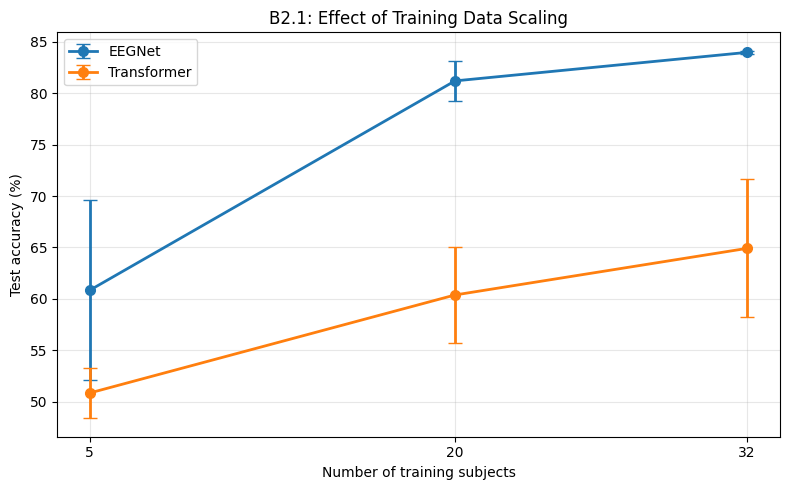

Plot saved: /content/Assignment/task1/B2_scaling_accuracy.png


In [102]:
import os
import pandas as pd
import matplotlib.pyplot as plt

base = "/content/Assignment/task1"

summary = pd.read_csv(
    os.path.join(base, "B2_scaling_summary.csv")
)

plt.figure(figsize=(8, 5))

for model in ["EEGNet", "Transformer"]:
    subset = summary[summary["Model"] == model].sort_values(
        "Training_subjects"
    )

    plt.errorbar(
        subset["Training_subjects"],
        subset["Mean_Accuracy"],
        yerr=subset["SD_Accuracy"],
        marker="o",
        markersize=7,
        capsize=5,
        linewidth=2,
        label=model
    )

plt.xlabel("Number of training subjects")
plt.ylabel("Test accuracy (%)")
plt.title("B2.1: Effect of Training Data Scaling")
plt.xticks([5, 20, 32])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plot_path = os.path.join(base, "B2_scaling_accuracy.png")
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Plot saved:", plot_path)

In [103]:
print("EEGNet available:", "EEGNet" in globals())
print("EEGTransformer available:", "EEGTransformer" in globals())

print("\nDataset:")
data = np.load("/content/Assignment/task1/B_eeg_dataset.npz")
for key in data.files:
    value = data[key]
    print(key, value.shape if hasattr(value, "shape") else type(value))

print("\nPartitions:")
print(pd.read_csv(
    "/content/Assignment/task1/B_subject_partitions.csv"
).groupby("partition")["subject"].apply(list))

EEGNet available: True
EEGTransformer available: True

Dataset:
X (1806, 64, 384)
y (1806,)
subjects (1806,)
channels (64,)
sampling_rate ()

Partitions:
partition
model_training    [70, 71, 72, 73, 75, 76, 77, 78, 81, 83, 84, 8...
test                              [74, 82, 85, 86, 89, 96, 97, 107]
validation                          [79, 80, 90, 92, 101, 106, 108]
Name: subject, dtype: object


In [104]:
print("EEG channel names:")
print(data["channels"].tolist())

print("\nExisting EEGTransformer:")
print(EEGTransformer)

print("\nTraining function:")
import inspect
print(inspect.signature(train_model))
print(inspect.signature(evaluate_model))

EEG channel names:
['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'Fp1', 'Fpz', 'Fp2', 'AF7', 'AF3', 'AFz', 'AF4', 'AF8', 'F7', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FT8', 'T7', 'T8', 'T9', 'T10', 'TP7', 'TP8', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2', 'Iz']

Existing EEGTransformer:
<class '__main__.EEGTransformer'>

Training function:
(model, model_name)
(model, loader)


In [105]:
import inspect

print(inspect.getsource(train_model))

def train_model(model, model_name):

    model = model.to(device)

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    patience_counter = 0

    history = []

    start_time = time.time()

    print(f"\n========== Training {model_name} ==========")

    for epoch in range(1, MAX_EPOCHS + 1):

        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer
        )

        val_loss, val_acc = evaluate_model(
            model, val_loader
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })

        # Save best model using validation loss
        if val_loss < best_val_loss - 0.0001:

            best_val_loss = val_loss
            best_epoch 

In [107]:
print("Available data-related variables:")

for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "loader", "dataset", "train_subject",
        "val_subject", "x_train", "y_train",
        "x_val", "y_val", "x_test", "y_test"
    ]):
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, value.shape)
        elif isinstance(value, (list, tuple, set)):
            print(name, "length =", len(value))
        else:
            print(name, type(value).__name__)

Available data-related variables:
DataLoader type
TensorDataset type
X_test (360, 64, 384)
X_test_final (360, 64, 384)
X_test_final_t torch.Size([360, 1, 64, 384])
X_test_raw (360, 64, 384)
X_test_t torch.Size([360, 1, 64, 384])
X_test_tensor torch.Size([360, 1, 64, 384])
X_train torch.Size([1446, 1, 64, 384])
X_train_raw (1446, 64, 384)
X_train_t torch.Size([1122, 1, 64, 384])
X_val (324, 64, 384)
X_val_t torch.Size([324, 1, 64, 384])
__loader__ NoneType
create_final_loader function
final_test_dataset TensorDataset
final_test_loader DataLoader
final_train_dataset TensorDataset
final_train_loader DataLoader
test_dataset TensorDataset
test_loader DataLoader
train_dataset TensorDataset
train_subjects (25,)
val_dataset TensorDataset
val_loader DataLoader
val_subjects (7,)
y_test (360,)
y_test_final (360,)
y_test_final_t torch.Size([360])
y_test_t torch.Size([360])
y_train (1446,)
y_train_t torch.Size([1122])
y_train_tensor torch.Size([1446])
y_val (324,)
y_val_t torch.Size([324])


In [108]:
print("train_dataset:", len(train_dataset))
print("val_dataset:", len(val_dataset))
print("final_train_dataset:", len(final_train_dataset))
print("final_train_loader:", len(final_train_loader))

print("\nTraining dataset sample:")
print(train_dataset[0][0].shape, train_dataset[0][1])

print("\nValidation dataset sample:")
print(val_dataset[0][0].shape, val_dataset[0][1])

train_dataset: 1446
val_dataset: 324
final_train_dataset: 1446
final_train_loader: 46

Training dataset sample:
torch.Size([1, 64, 384]) tensor(1)

Validation dataset sample:
torch.Size([1, 64, 384]) tensor(0)


In [109]:
from torch.utils.data import DataLoader, TensorDataset

BATCH_SIZE = 32

# Use only the 25 model-training subjects
train_dataset_b22 = TensorDataset(X_train_t, y_train_t)

# Use the 7 validation subjects
val_dataset_b22 = TensorDataset(X_val_t, y_val_t)

train_loader = DataLoader(
    train_dataset_b22,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset_b22,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training trials:", len(train_dataset_b22))
print("Validation trials:", len(val_dataset_b22))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training trials: 1122
Validation trials: 324
Training batches: 36
Validation batches: 11


In [110]:
import torch
import torch.nn as nn

# --------------------------------------------------
# Channel-token Transformer
# --------------------------------------------------

class ChannelTokenTransformer(nn.Module):

    def __init__(
        self,
        n_channels=64,
        n_samples=384,
        embed_dim=8,
        num_heads=2,
        num_layers=1,
        ff_dim=16,
        dropout_rate=0.3,
        use_electrode_identity=False
    ):
        super().__init__()

        self.use_electrode_identity = use_electrode_identity

        # Shared temporal encoder for every electrode
        self.temporal_encoder = nn.Conv1d(
            in_channels=1,
            out_channels=embed_dim,
            kernel_size=16,
            stride=16
        )

        # Optional learned electrode-identity embeddings
        if use_electrode_identity:
            self.electrode_embedding = nn.Parameter(
                torch.randn(1, n_channels, embed_dim) * 0.02
            )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout_rate,
            activation="gelu",
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.classifier = nn.Linear(embed_dim, 2)

    def forward(self, x):

        # Input: (batch, 1, 64, 384)
        x = x.squeeze(1)

        batch_size, n_channels, n_samples = x.shape

        # Each electrode becomes an independent sequence
        x = x.reshape(batch_size * n_channels, 1, n_samples)

        # Temporal feature extraction
        x = self.temporal_encoder(x)

        # Average temporal patches to obtain one token per electrode
        x = x.mean(dim=-1)

        # Reshape to (batch, 64 electrodes, embedding dimension)
        x = x.reshape(batch_size, n_channels, -1)

        # Add electrode identity when enabled
        if self.use_electrode_identity:
            x = x + self.electrode_embedding

        # Attention across electrode tokens
        x = self.transformer(x)

        # Global average pooling across electrodes
        x = x.mean(dim=1)

        return self.classifier(x)


# --------------------------------------------------
# Instantiate three variants
# --------------------------------------------------

time_patch_model = EEGTransformer()

channel_no_identity_model = ChannelTokenTransformer(
    use_electrode_identity=False
)

channel_identity_model = ChannelTokenTransformer(
    use_electrode_identity=True
)


# --------------------------------------------------
# Compare parameter counts
# --------------------------------------------------

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


models_b22 = {
    "TimePatch": time_patch_model,
    "Channel_NoIdentity": channel_no_identity_model,
    "Channel_WithIdentity": channel_identity_model
}

print("B2.2(a) model parameter counts:\n")

for name, model in models_b22.items():
    print(f"{name}: {count_parameters(model):,} trainable parameters")

B2.2(a) model parameter counts:

TimePatch: 1,482 trainable parameters
Channel_NoIdentity: 754 trainable parameters
Channel_WithIdentity: 1,266 trainable parameters


In [111]:
for name, model in models_b22.items():
    model = model.to(device)
    with torch.no_grad():
        output = model(X_train_t[:4].to(device))

    print(
        name,
        "| Output shape:", tuple(output.shape),
        "| Parameters:", count_parameters(model)
    )

TimePatch | Output shape: (4, 2) | Parameters: 1482
Channel_NoIdentity | Output shape: (4, 2) | Parameters: 754
Channel_WithIdentity | Output shape: (4, 2) | Parameters: 1266


In [112]:
import os
import random
import numpy as np
import torch
import pandas as pd

base = "/content/Assignment/task1"
os.makedirs(base, exist_ok=True)

SEEDS_B22 = [0, 21, 42]

# Fresh model factory for every run
model_factories = {
    "TimePatch": lambda: EEGTransformer(),

    "Channel_NoIdentity": lambda: ChannelTokenTransformer(
        use_electrode_identity=False
    ),

    "Channel_WithIdentity": lambda: ChannelTokenTransformer(
        use_electrode_identity=True
    )
}

results_b22 = []
checkpoints_b22 = {}
histories_b22 = {}

for model_name, model_factory in model_factories.items():

    for seed in SEEDS_B22:

        print("\n" + "=" * 65)
        print(f"Model: {model_name} | Seed: {seed}")
        print("=" * 65)

        # Set reproducible random seed
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        # Initialize a fresh model
        model = model_factory()

        # Train using the existing validation-based early stopping
        trained_model, best_state, best_epoch, history = train_model(
            model,
            f"{model_name}_seed{seed}"
        )

        # Record validation performance
        val_loss, val_acc = evaluate_model(
            trained_model,
            val_loader
        )

        results_b22.append({
            "Model": model_name,
            "Seed": seed,
            "Best_Epoch": best_epoch,
            "Validation_Loss": val_loss,
            "Validation_Accuracy": val_acc * 100,
            "Parameters": count_parameters(trained_model)
        })

        checkpoints_b22[f"{model_name}_seed{seed}"] = best_state
        histories_b22[f"{model_name}_seed{seed}"] = history

# Save results
results_df_b22 = pd.DataFrame(results_b22)

results_df_b22.to_csv(
    os.path.join(base, "B2_2a_tokenisation_seed_results.csv"),
    index=False
)

# Save model checkpoints and training histories
torch.save(
    checkpoints_b22,
    os.path.join(base, "B2_2a_tokenisation_checkpoints.pt")
)

for name, history in histories_b22.items():
    history.to_csv(
        os.path.join(base, f"B2_2a_history_{name}.csv"),
        index=False
    )

print("\n========== B2.2(a) RESULTS ==========")
display(results_df_b22)


Model: TimePatch | Seed: 0

========== Training TimePatch_seed0 ==========
Epoch 001 | Train Loss: 0.7125 | Train Acc: 0.4786 | Val Loss: 0.7083 | Val Acc: 0.4506
Epoch 005 | Train Loss: 0.6834 | Train Acc: 0.5499 | Val Loss: 0.7063 | Val Acc: 0.4383
Epoch 010 | Train Loss: 0.6556 | Train Acc: 0.6168 | Val Loss: 0.7068 | Val Acc: 0.4969
Epoch 015 | Train Loss: 0.6183 | Train Acc: 0.6533 | Val Loss: 0.7018 | Val Acc: 0.5278
Epoch 020 | Train Loss: 0.5559 | Train Acc: 0.7264 | Val Loss: 0.6483 | Val Acc: 0.6142
Epoch 025 | Train Loss: 0.4790 | Train Acc: 0.7781 | Val Loss: 0.6229 | Val Acc: 0.6790
Epoch 030 | Train Loss: 0.4099 | Train Acc: 0.8155 | Val Loss: 0.6480 | Val Acc: 0.6883
Epoch 035 | Train Loss: 0.3625 | Train Acc: 0.8307 | Val Loss: 0.6315 | Val Acc: 0.7068
Early stopping at epoch 39.

Best epoch: 27
Best validation loss: 0.6191
Training time: 39.72 seconds

Model: TimePatch | Seed: 21

========== Training TimePatch_seed21 ==========
Epoch 001 | Train Loss: 0.7131 | Train A

,Model,Seed,Best_Epoch,Validation_Loss,Validation_Accuracy,Parameters
0,TimePatch,0,27,0.619144,69.444444,1482
1,TimePatch,21,23,0.605490,68.209877,1482
2,TimePatch,42,9,0.694372,53.395062,1482
3,Channel_NoIdentity,0,2,0.693709,52.160494,754
4,Channel_NoIdentity,21,6,0.693201,49.691358,754
5,Channel_NoIdentity,42,2,0.692376,50.308642,754
6,Channel_WithIdentity,0,1,0.690762,54.012346,1266
7,Channel_WithIdentity,21,4,0.692080,52.777778,1266
8,Channel_WithIdentity,42,100,0.676536,57.098765,1266


In [113]:
summary_b22 = (
    results_df_b22
    .groupby("Model")
    .agg(
        Mean_Val_Accuracy=("Validation_Accuracy", "mean"),
        SD_Val_Accuracy=("Validation_Accuracy", "std"),
        Mean_Val_Loss=("Validation_Loss", "mean"),
        SD_Val_Loss=("Validation_Loss", "std"),
        Mean_Best_Epoch=("Best_Epoch", "mean"),
        Parameters=("Parameters", "first")
    )
    .reset_index()
)

summary_path = os.path.join(
    base, "B2_2a_tokenisation_summary.csv"
)

summary_b22.to_csv(summary_path, index=False)

display(summary_b22)
print("Saved:", summary_path)

,Model,Mean_Val_Accuracy,SD_Val_Accuracy,Mean_Val_Loss,SD_Val_Loss,Mean_Best_Epoch,Parameters
0,Channel_NoIdentity,50.720165,1.284979,0.693095,0.000673,3.333333,754
1,Channel_WithIdentity,54.629630,2.225649,0.686459,0.008619,35.000000,1266
2,TimePatch,63.683128,8.931084,0.639668,0.047864,19.666667,1482


Saved: /content/Assignment/task1/B2_2a_tokenisation_summary.csv


In [114]:
import mne
import numpy as np

channels = data["channels"].tolist()

montage = mne.channels.make_standard_montage("standard_1005")
montage_positions = montage.get_positions()["ch_pos"]

missing_channels = [
    ch for ch in channels if ch not in montage_positions
]

print("Total EEG channels:", len(channels))
print("Channels with standard coordinates:",
      len(channels) - len(missing_channels))

print("Missing channels:", missing_channels)

print("\nExample electrode coordinates:")
for ch in ["Fp1", "Fz", "C3", "Cz", "C4", "Pz", "O1", "O2"]:
    if ch in montage_positions:
        print(ch, np.round(montage_positions[ch], 4))

/tmp/ipykernel_2868/3726013056.py:6: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


Total EEG channels: 64
Channels with standard coordinates: 64
Missing channels: []

Example electrode coordinates:
Fp1 [-0.0294  0.0839 -0.007 ]
Fz [0.0003 0.0585 0.0665]
C3 [-0.0654 -0.0116  0.0644]
Cz [ 0.0004 -0.0092  0.1002]
C4 [ 0.0671 -0.0109  0.0636]
Pz [ 0.0003 -0.0811  0.0826]
O1 [-0.0294 -0.1124  0.0088]
O2 [ 0.0298 -0.1122  0.0088]


In [121]:
import inspect
import mne.channels.interpolation as interpolation

print(inspect.signature(interpolation._make_interpolation_matrix))
print(inspect.getdoc(interpolation._make_interpolation_matrix))

(pos_from, pos_to, alpha=1e-05)
Compute interpolation matrix based on spherical splines.

Implementation based on [1]

Parameters
----------
pos_from : np.ndarray of float, shape(n_good_sensors, 3)
    The positions to interpolate from.
pos_to : np.ndarray of float, shape(n_bad_sensors, 3)
    The positions to interpolate.
alpha : float
    Regularization parameter. Defaults to 1e-5.

Returns
-------
interpolation : np.ndarray of float, shape(len(pos_from), len(pos_to))
    The interpolation matrix that maps good signals to the location
    of bad signals.

References
----------
[1] Perrin, F., Pernier, J., Bertrand, O. and Echallier, JF. (1989).
    Spherical splines for scalp potential and current density mapping.
    Electroencephalography Clinical Neurophysiology, Feb; 72(2):184-7.


In [123]:
print("Data archive keys:", data.files)
print("Channel variable type:", type(channels))
print("Number of channels:", len(channels))
print("First 10 channels:", channels[:10])

Data archive keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'train_subjects', 'val_subjects', 'test_subjects', 'channel_mean', 'channel_std']
Channel variable type: <class 'numpy.ndarray'>
Number of channels: 64
First 10 channels: ['FC5' 'FC3' 'FC1' 'FCz' 'FC2' 'FC4' 'FC6' 'C5' 'C3' 'C1']


In [124]:
import numpy as np
import mne
from mne.channels.interpolation import _make_interpolation_matrix

channels = list(channels)

# Obtain electrode coordinates in the exact dataset order
montage = mne.channels.make_standard_montage("standard_1005")
positions = montage.get_positions()["ch_pos"]

pos_original = np.array([
    positions[ch] for ch in channels
])

# Approximate head centre in MNE head coordinates
head_center = np.array([0.0, 0.0, 0.04])

# Preserve each electrode's original distance from head centre
vectors = pos_original - head_center
radii = np.linalg.norm(vectors, axis=1)
unit_vectors = vectors / radii[:, None]

# Positive y points anteriorly in this coordinate system
anterior_direction = np.array([0.0, 1.0, 0.0])

# Tangential direction toward the anterior
dot_products = unit_vectors @ anterior_direction
tangent = (
    anterior_direction[None, :]
    - dot_products[:, None] * unit_vectors
)

tangent_norm = np.linalg.norm(tangent, axis=1)
tangent = tangent / np.maximum(tangent_norm[:, None], 1e-12)

# Rotate each electrode approximately 10 mm anteriorly
displacement_mm = 10.0
angles = (displacement_mm / 1000.0) / radii

unit_displaced = (
    np.cos(angles)[:, None] * unit_vectors
    + np.sin(angles)[:, None] * tangent
)

pos_displaced = (
    head_center + radii[:, None] * unit_displaced
)

# Calculate spherical-spline interpolation matrix
interpolation_matrix = _make_interpolation_matrix(
    pos_original,
    pos_displaced,
    alpha=1e-5
)

actual_displacement = np.linalg.norm(
    pos_displaced - pos_original, axis=1
) * 1000

print("Original positions:", pos_original.shape)
print("Displaced positions:", pos_displaced.shape)
print("Interpolation matrix:", interpolation_matrix.shape)
print("All matrix values finite:",
      np.isfinite(interpolation_matrix).all())
print("Mean displacement (mm):", actual_displacement.mean())
print("Minimum displacement (mm):", actual_displacement.min())
print("Maximum displacement (mm):", actual_displacement.max())

Original positions: (64, 3)
Displaced positions: (64, 3)
Interpolation matrix: (64, 64)
All matrix values finite: True
Mean displacement (mm): 9.994230285122143
Minimum displacement (mm): 9.986646061165823
Maximum displacement (mm): 9.997690028857754


/tmp/ipykernel_2868/1430909327.py:8: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


In [125]:
print("Test data:")
print("X_test_raw:", X_test_raw.shape)
print("X_test_final_t:", X_test_final_t.shape)

print("\nTraining normalization statistics:")
print("channel_mean:", data["channel_mean"].shape)
print("channel_std:", data["channel_std"].shape)

print("\nTest subjects:", np.unique(data["test_subjects"]))
print("Test labels:", np.unique(data["y_test"], return_counts=True))

print("\nAvailable trained model objects:")
for name, obj in globals().copy().items():
    if isinstance(obj, torch.nn.Module):
        print(name, type(obj).__name__)

Test data:
X_test_raw: (360, 64, 384)
X_test_final_t: torch.Size([360, 1, 64, 384])

Training normalization statistics:
channel_mean: (1, 64, 1)
channel_std: (1, 64, 1)

Test subjects: [ 74  82  85  86  89  96  97 107]
Test labels: (array([0, 1]), array([186, 174]))

Available trained model objects:
eegnet EEGNet
transformer EEGTransformer
criterion CrossEntropyLoss
final_eegnet EEGNet
final_transformer EEGTransformer
model ChannelTokenTransformer
time_patch_model EEGTransformer
channel_no_identity_model ChannelTokenTransformer
channel_identity_model ChannelTokenTransformer
trained_model ChannelTokenTransformer


In [126]:

import numpy as np
import os

RAW_PATH = "/content/Assignment/task1/B_eeg_dataset.npz"
NORM_PATH = "/content/Assignment/task1/B_normalized_dataset.npz"

assert os.path.exists(RAW_PATH)
assert os.path.exists(NORM_PATH)

raw_data = np.load(RAW_PATH, allow_pickle=True)
norm_data = np.load(NORM_PATH, allow_pickle=True)

# Original, unnormalized EEG signals
X_raw_all = raw_data["X"]
y_raw_all = raw_data["y"].astype(int)
subjects_all = raw_data["subjects"]
channels = raw_data["channels"]
sampling_rate = int(raw_data["sampling_rate"])

# Existing subject-level split
train_subjects = norm_data["train_subjects"]
val_subjects = norm_data["val_subjects"]
test_subjects = norm_data["test_subjects"]

# Training-derived normalization statistics
channel_mean = norm_data["channel_mean"]
channel_std = norm_data["channel_std"]

# Existing normalized test data
X_test_saved = norm_data["X_test"]
y_test = norm_data["y_test"].astype(int)

print("Raw dataset:", X_raw_all.shape)
print("Normalized test:", X_test_saved.shape)
print("Sampling rate:", sampling_rate)

print("Training subjects:", len(train_subjects))
print("Validation subjects:", len(val_subjects))
print("Test subjects:", len(test_subjects))

print("Normalization mean:", channel_mean.shape)
print("Normalization std:", channel_std.shape)


Raw dataset: (1806, 64, 384)
Normalized test: (360, 64, 384)
Sampling rate: 128
Training subjects: 25
Validation subjects: 7
Test subjects: 8
Normalization mean: (1, 64, 1)
Normalization std: (1, 64, 1)


In [127]:

development_subjects = np.concatenate([
    train_subjects,
    val_subjects
])

development_subjects = np.unique(
    development_subjects
)

test_subjects = np.unique(test_subjects)

print("Development subjects:",
      development_subjects)

print("\nNumber of development subjects:",
      len(development_subjects))

print("\nTest subjects:",
      test_subjects)

print("Number of test subjects:",
      len(test_subjects))

print("\nDevelopment/test overlap:",
      set(development_subjects) & set(test_subjects))

assert len(development_subjects) == 32
assert len(test_subjects) == 8

assert len(
    set(development_subjects) & set(test_subjects)
) == 0

assert len(
    np.union1d(development_subjects, test_subjects)
) == 40

print("\nSubject-level split verified.")


Development subjects: [ 70  71  72  73  75  76  77  78  79  80  81  83  84  87  88  90  91  92
  93  94  95  98  99 100 101 102 103 104 105 106 108 109]

Number of development subjects: 32

Test subjects: [ 74  82  85  86  89  96  97 107]
Number of test subjects: 8

Development/test overlap: set()

Subject-level split verified.


In [130]:

test_mask = np.isin(
    subjects_all,
    test_subjects
)

X_test_raw = X_raw_all[test_mask].copy()

y_test_raw = y_raw_all[test_mask]

subjects_test_raw = subjects_all[test_mask]

print("Raw test signals:", X_test_raw.shape)
print("Raw test labels:", y_test_raw.shape)

print("Test subjects:",
      np.unique(subjects_test_raw))

print("Label distribution:",
      np.unique(y_test_raw, return_counts=True))

assert X_test_raw.shape == (360, 64, 384)
assert np.array_equal(y_test_raw, y_test)

assert set(np.unique(subjects_test_raw)) == set(test_subjects)

print("\nRaw test extraction verified.")


Raw test signals: (360, 64, 384)
Raw test labels: (360,)
Test subjects: [ 74  82  85  86  89  96  97 107]
Label distribution: (array([0, 1]), array([186, 174]))

Raw test extraction verified.


In [129]:

# Avoid division by zero
assert np.all(channel_std > 0)

# Normalize original test signals
X_test_original_norm = (
    X_test_raw - channel_mean
) / channel_std

print("Normalized original test:",
      X_test_original_norm.shape)

# Verify against the previously saved normalized test data
max_difference = np.max(
    np.abs(X_test_original_norm - X_test_saved)
)

print("Maximum difference from saved normalized test:",
      max_difference)

assert np.allclose(
    X_test_original_norm,
    X_test_saved,
    rtol=1e-4,
    atol=1e-5
), "Normalization does not reproduce the saved test data."

print("\nOriginal test normalization verified.")


Normalized original test: (360, 64, 384)
Maximum difference from saved normalized test: 0.0

Original test normalization verified.


In [132]:

import numpy as np
import mne

from mne.channels.interpolation import (
    _make_interpolation_matrix
)

# Recover exact channel order from original dataset
channel_names = [
    ch.decode() if isinstance(ch, bytes) else str(ch)
    for ch in raw_data["channels"]
]

# Use the same montage as the previous experiment
montage = mne.channels.make_standard_montage(
    "standard_1005"
)

montage_positions = montage.get_positions()["ch_pos"]

# Match coordinates to dataset channel order
missing_channels = [
    ch for ch in channel_names
    if ch not in montage_positions
]

assert len(missing_channels) == 0, missing_channels

original_coords = np.array([
    montage_positions[ch]
    for ch in channel_names
])

# Apply 10-mm anterior displacement
DISPLACEMENT_M = 0.010

shifted_coords = (
    original_coords
    + np.array([0.0, DISPLACEMENT_M, 0.0])
)

# Project back onto the original scalp radius
scalp_radius = np.linalg.norm(
    original_coords, axis=1
)

displaced_norm = np.linalg.norm(
    shifted_coords, axis=1
)

displaced_coords = (
    shifted_coords
    / displaced_norm[:, None]
) * scalp_radius[:, None]

# Construct spatial interpolation matrix
W = _make_interpolation_matrix(
    pos_from=original_coords,
    pos_to=displaced_coords,
    alpha=1e-5
)

# Verify matrix
actual_displacement = np.linalg.norm(
    displaced_coords - original_coords,
    axis=1
) * 1000

print("Original positions:", original_coords.shape)
print("Displaced positions:", displaced_coords.shape)
print("Interpolation matrix:", W.shape)
print("All matrix values finite:", np.isfinite(W).all())

print(
    "Mean displacement (mm):",
    actual_displacement.mean()
)

print(
    "Minimum displacement (mm):",
    actual_displacement.min()
)

print(
    "Maximum displacement (mm):",
    actual_displacement.max()
)

assert W.shape == (64, 64)
assert np.isfinite(W).all()


Original positions: (64, 3)
Displaced positions: (64, 3)
Interpolation matrix: (64, 64)
All matrix values finite: True
Mean displacement (mm): 7.4559055442326825
Minimum displacement (mm): 0.1747041588803559
Maximum displacement (mm): 10.014021240186224


/tmp/ipykernel_2868/1547225495.py:15: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage(


In [133]:

# Apply spatial interpolation BEFORE normalization
X_test_displaced_raw = np.einsum(
    "ij,njt->nit",
    W,
    X_test_raw
)

print("Displaced raw test:",
      X_test_displaced_raw.shape)

assert X_test_displaced_raw.shape == X_test_raw.shape
assert np.isfinite(X_test_displaced_raw).all()

# Apply EXACTLY the same training statistics
X_test_displaced_norm = (
    X_test_displaced_raw - channel_mean
) / channel_std

print("Displaced normalized test:",
      X_test_displaced_norm.shape)

assert np.isfinite(X_test_displaced_norm).all()

print("\nSpatial perturbation and normalization completed.")


Displaced raw test: (360, 64, 384)
Displaced normalized test: (360, 64, 384)

Spatial perturbation and normalization completed.


In [134]:

print("ORIGINAL TEST")
print("Shape:", X_test_original_norm.shape)
print("Mean:", X_test_original_norm.mean())
print("SD:", X_test_original_norm.std())

print("\nDISPLACED TEST")
print("Shape:", X_test_displaced_norm.shape)
print("Mean:", X_test_displaced_norm.mean())
print("SD:", X_test_displaced_norm.std())

# Calculate relative signal change
relative_change = (
    np.linalg.norm(
        X_test_displaced_norm - X_test_original_norm
    )
    /
    (np.linalg.norm(X_test_original_norm) + 1e-12)
)

print("\nRelative signal change:", relative_change)

assert relative_change > 0

# Both conditions must use identical labels
assert np.array_equal(y_test_raw, y_test)

print("\nBoth test conditions are ready.")


ORIGINAL TEST
Shape: (360, 64, 384)
Mean: 0.021978414
SD: 0.9113365

DISPLACED TEST
Shape: (360, 64, 384)
Mean: 0.00587509052652831
SD: 0.8498554026736934

Relative signal change: 0.42512491430095434

Both test conditions are ready.


In [135]:

import torch

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Keep the same input convention as your earlier models.
X_original_tensor = torch.tensor(
    X_test_original_norm[:, None, :, :],
    dtype=torch.float32
)

X_displaced_tensor = torch.tensor(
    X_test_displaced_norm[:, None, :, :],
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_raw,
    dtype=torch.long
)

print("Device:", DEVICE)

print("Original input:", X_original_tensor.shape)
print("Displaced input:", X_displaced_tensor.shape)
print("Labels:", y_test_tensor.shape)


Device: cpu
Original input: torch.Size([360, 1, 64, 384])
Displaced input: torch.Size([360, 1, 64, 384])
Labels: torch.Size([360])


In [136]:
print("Original test data:", X_test_raw.shape)
print("Displaced raw test data:", X_test_displaced_raw.shape)
print("Original normalized test data:", X_test_original_norm.shape)
print("Displaced normalized test data:", X_test_displaced_norm.shape)

print("\nInterpolation matrix:")
print("W shape:", W.shape)
print("All values finite:", np.isfinite(W).all())

print("\nNormalization check:")
print("Original normalized data matches saved test data:",
      np.allclose(X_test_original_norm, X_test_saved,
                  rtol=1e-4, atol=1e-5))

print("\nTest subjects:", np.unique(subjects_test_raw))
print("Number of test subjects:", len(np.unique(subjects_test_raw)))

Original test data: (360, 64, 384)
Displaced raw test data: (360, 64, 384)
Original normalized test data: (360, 64, 384)
Displaced normalized test data: (360, 64, 384)

Interpolation matrix:
W shape: (64, 64)
All values finite: True

Normalization check:
Original normalized data matches saved test data: True

Test subjects: [ 74  82  85  86  89  96  97 107]
Number of test subjects: 8


In [137]:
import os
import torch
from pathlib import Path

print("========== LOADED PYTORCH MODELS ==========")

loaded_models = {}

for name, obj in globals().copy().items():
    if isinstance(obj, torch.nn.Module):
        loaded_models[name] = obj
        print(f"{name}: {type(obj).__name__}")

print("\nTotal loaded models:", len(loaded_models))

print("\n========== MODEL/CHECKPOINT FILES ==========")

search_dirs = [
    Path("/content/Assignment"),
    Path("/content")
]

seen = set()

for base_dir in search_dirs:
    if base_dir.exists():
        for path in base_dir.rglob("*"):
            if path.is_file() and path.suffix.lower() in [
                ".pt", ".pth", ".ckpt", ".pkl", ".safetensors"
            ]:
                if str(path) not in seen:
                    seen.add(str(path))
                    print(path)

========== LOADED PYTORCH MODELS ==========
eegnet: EEGNet
transformer: EEGTransformer
criterion: CrossEntropyLoss
final_eegnet: EEGNet
final_transformer: EEGTransformer
model: ChannelTokenTransformer
time_patch_model: EEGTransformer
channel_no_identity_model: ChannelTokenTransformer
channel_identity_model: ChannelTokenTransformer
trained_model: ChannelTokenTransformer

Total loaded models: 10

========== MODEL/CHECKPOINT FILES ==========
/content/Assignment/task1/B2_2a_tokenisation_checkpoints.pt
/content/Assignment/task1/B_validation_checkpoints.pt
/content/Assignment/task1/B_final_Transformer.pt
/content/Assignment/task1/B_final_EEGNet.pt


In [138]:
import torch
from pathlib import Path

checkpoint_paths = [
    "/content/Assignment/task1/B2_2a_tokenisation_checkpoints.pt",
    "/content/Assignment/task1/B_validation_checkpoints.pt",
    "/content/Assignment/task1/B_final_Transformer.pt",
    "/content/Assignment/task1/B_final_EEGNet.pt"
]

for path in checkpoint_paths:
    print("\n" + "=" * 75)
    print("FILE:", Path(path).name)

    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print("Top-level type:", type(checkpoint).__name__)

        if isinstance(checkpoint, dict):
            print("Top-level keys:", list(checkpoint.keys()))

            for key, value in checkpoint.items():
                print(f"\n  Key: {key}")
                print("  Type:", type(value).__name__)

                if isinstance(value, dict):
                    print("  Nested keys:", list(value.keys())[:30])

                    tensor_items = [
                        (k, v.shape)
                        for k, v in value.items()
                        if isinstance(v, torch.Tensor)
                    ]
                    if tensor_items:
                        print("  Tensor shapes:", tensor_items[:10])

                elif isinstance(value, torch.Tensor):
                    print("  Shape:", tuple(value.shape))

                elif isinstance(value, (list, tuple)):
                    print("  Number of items:", len(value))
                    if len(value) > 0:
                        print("  First item type:", type(value[0]).__name__)

        else:
            print("Content preview:", str(checkpoint)[:500])

    except Exception as e:
        print("Could not inspect:", repr(e))


FILE: B2_2a_tokenisation_checkpoints.pt
Top-level type: dict
Top-level keys: ['TimePatch_seed0', 'TimePatch_seed21', 'TimePatch_seed42', 'Channel_NoIdentity_seed0', 'Channel_NoIdentity_seed21', 'Channel_NoIdentity_seed42', 'Channel_WithIdentity_seed0', 'Channel_WithIdentity_seed21', 'Channel_WithIdentity_seed42']

  Key: TimePatch_seed0
  Type: OrderedDict
  Nested keys: ['positional_embedding', 'temporal_embedding.0.weight', 'temporal_embedding.1.weight', 'temporal_embedding.1.bias', 'temporal_embedding.1.running_mean', 'temporal_embedding.1.running_var', 'temporal_embedding.1.num_batches_tracked', 'spatial_extraction.0.weight', 'spatial_extraction.1.weight', 'spatial_extraction.1.bias', 'spatial_extraction.1.running_mean', 'spatial_extraction.1.running_var', 'spatial_extraction.1.num_batches_tracked', 'transformer.layers.0.self_attn.in_proj_weight', 'transformer.layers.0.self_attn.in_proj_bias', 'transformer.layers.0.self_attn.out_proj.weight', 'transformer.layers.0.self_attn.out_pr

In [139]:
import torch

checkpoint = torch.load(
    "/content/Assignment/task1/B2_2a_tokenisation_checkpoints.pt",
    map_location="cpu",
    weights_only=False
)

model_objects = {
    "eegnet": eegnet,
    "final_eegnet": final_eegnet,
    "time_patch_model": time_patch_model,
    "transformer": transformer,
    "final_transformer": final_transformer,
    "channel_no_identity_model": channel_no_identity_model,
    "channel_identity_model": channel_identity_model,
    "trained_model": trained_model,
    "model": model
}

def check_compatibility(model_obj, saved_state):
    current_state = model_obj.state_dict()

    same_keys = set(current_state.keys()) == set(saved_state.keys())

    same_shapes = (
        same_keys and all(
            current_state[k].shape == saved_state[k].shape
            for k in current_state
        )
    )

    return same_keys, same_shapes

print("========== CHECKPOINT COMPATIBILITY ==========")

for checkpoint_name, saved_state in checkpoint.items():
    print(f"\n{checkpoint_name}")

    matches = []

    for model_name, model_obj in model_objects.items():
        same_keys, same_shapes = check_compatibility(
            model_obj, saved_state
        )

        if same_keys and same_shapes:
            matches.append(model_name)

    print("Compatible model objects:", matches if matches else "None")

========== CHECKPOINT COMPATIBILITY ==========

TimePatch_seed0
Compatible model objects: ['time_patch_model', 'transformer', 'final_transformer']

TimePatch_seed21
Compatible model objects: ['time_patch_model', 'transformer', 'final_transformer']

TimePatch_seed42
Compatible model objects: ['time_patch_model', 'transformer', 'final_transformer']

Channel_NoIdentity_seed0
Compatible model objects: ['channel_no_identity_model']

Channel_NoIdentity_seed21
Compatible model objects: ['channel_no_identity_model']

Channel_NoIdentity_seed42
Compatible model objects: ['channel_no_identity_model']

Channel_WithIdentity_seed0
Compatible model objects: ['channel_identity_model', 'trained_model', 'model']

Channel_WithIdentity_seed21
Compatible model objects: ['channel_identity_model', 'trained_model', 'model']

Channel_WithIdentity_seed42
Compatible model objects: ['channel_identity_model', 'trained_model', 'model']


In [140]:
import torch

eegnet_state = torch.load(
    "/content/Assignment/task1/B_final_EEGNet.pt",
    map_location="cpu",
    weights_only=False
)

print("========== EEGNET CHECKPOINT COMPATIBILITY ==========")

for name, obj in {
    "eegnet": eegnet,
    "final_eegnet": final_eegnet
}.items():

    current_state = obj.state_dict()

    same_keys = set(current_state.keys()) == set(eegnet_state.keys())

    same_shapes = (
        same_keys and all(
            current_state[k].shape == eegnet_state[k].shape
            for k in current_state
        )
    )

    print(f"\nModel: {name}")
    print("Matching parameter names:", same_keys)
    print("Matching tensor shapes:", same_shapes)

========== EEGNET CHECKPOINT COMPATIBILITY ==========

Model: eegnet
Matching parameter names: True
Matching tensor shapes: True

Model: final_eegnet
Matching parameter names: True
Matching tensor shapes: True


In [141]:
import inspect

models_to_inspect = {
    "EEGNet": final_eegnet,
    "TimePatch": time_patch_model,
    "Channel_NoIdentity": channel_no_identity_model,
    "Channel_WithIdentity": channel_identity_model
}

for name, obj in models_to_inspect.items():
    print("\n" + "=" * 75)
    print("MODEL:", name)
    print("Class:", type(obj).__name__)
    print("Forward signature:", inspect.signature(obj.forward))

    try:
        print("\nForward method:")
        print(inspect.getsource(type(obj).forward))
    except Exception as e:
        print("Could not retrieve source:", repr(e))


MODEL: EEGNet
Class: EEGNet
Forward signature: (x)

Forward method:
    def forward(self, x):
        x = self._forward_features(x)
        return self.classifier(x)


MODEL: TimePatch
Class: EEGTransformer
Forward signature: (x)

Forward method:
    def forward(self, x):

        # Temporal patch embedding
        x = self.temporal_embedding(x)

        # Spatial feature extraction
        x = self.spatial_extraction(x)

        # Shape: (batch, embed_dim, 1, num_patches)
        x = x.squeeze(2)

        # Shape: (batch, num_patches, embed_dim)
        x = x.transpose(1, 2)

        # Add positional information
        x = x + self.positional_embedding

        # Transformer encoder
        x = self.transformer(x)

        # Global average pooling over temporal patches
        x = x.mean(dim=1)

        # Classification
        return self.classifier(x)


MODEL: Channel_NoIdentity
Class: ChannelTokenTransformer
Forward signature: (x)

Forward method:
    def forward(self, x):

     

In [142]:
import copy
import numpy as np
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Evaluation device:", device)

# Load saved checkpoints
transformer_checkpoints = torch.load(
    "/content/Assignment/task1/B2_2a_tokenisation_checkpoints.pt",
    map_location="cpu",
    weights_only=False
)

eegnet_checkpoint = torch.load(
    "/content/Assignment/task1/B_final_EEGNet.pt",
    map_location="cpu",
    weights_only=False
)

# Create independent model instances
model_templates = {
    "EEGNet": final_eegnet,
    "TimePatch": time_patch_model,
    "Channel_NoIdentity": channel_no_identity_model,
    "Channel_WithIdentity": channel_identity_model
}

model_instances = {}

# EEGNet
model_instances["EEGNet"] = copy.deepcopy(final_eegnet)
model_instances["EEGNet"].load_state_dict(eegnet_checkpoint, strict=True)

# Three Transformer variants, each with three seeds
for variant, template in [
    ("TimePatch", time_patch_model),
    ("Channel_NoIdentity", channel_no_identity_model),
    ("Channel_WithIdentity", channel_identity_model)
]:
    for seed in [0, 21, 42]:
        model_name = f"{variant}_seed{seed}"

        model_copy = copy.deepcopy(template)
        model_copy.load_state_dict(
            transformer_checkpoints[model_name],
            strict=True
        )

        model_instances[model_name] = model_copy

# Prepare inputs: (N, 1, 64, 384)
X_original_tensor = torch.from_numpy(
    X_test_original_norm.astype(np.float32)
).unsqueeze(1)

X_displaced_tensor = torch.from_numpy(
    X_test_displaced_norm.astype(np.float32)
).unsqueeze(1)

print("\nOriginal input:", tuple(X_original_tensor.shape))
print("Displaced input:", tuple(X_displaced_tensor.shape))
print("Test labels:", np.unique(y_test))

# Smoke test: first 8 samples
print("\n========== INFERENCE CHECK ==========")

for name, net in model_instances.items():
    net = net.to(device)
    net.eval()

    with torch.no_grad():
        original_logits = net(
            X_original_tensor[:8].to(device)
        )
        displaced_logits = net(
            X_displaced_tensor[:8].to(device)
        )

    print(
        f"{name}: "
        f"original={tuple(original_logits.shape)}, "
        f"displaced={tuple(displaced_logits.shape)}, "
        f"finite={torch.isfinite(original_logits).all().item() and torch.isfinite(displaced_logits).all().item()}"
    )

Evaluation device: cpu

Original input: (360, 1, 64, 384)
Displaced input: (360, 1, 64, 384)
Test labels: [0 1]

========== INFERENCE CHECK ==========
EEGNet: original=(8, 2), displaced=(8, 2), finite=True
TimePatch_seed0: original=(8, 2), displaced=(8, 2), finite=True
TimePatch_seed21: original=(8, 2), displaced=(8, 2), finite=True
TimePatch_seed42: original=(8, 2), displaced=(8, 2), finite=True
Channel_NoIdentity_seed0: original=(8, 2), displaced=(8, 2), finite=True
Channel_NoIdentity_seed21: original=(8, 2), displaced=(8, 2), finite=True
Channel_NoIdentity_seed42: original=(8, 2), displaced=(8, 2), finite=True
Channel_WithIdentity_seed0: original=(8, 2), displaced=(8, 2), finite=True
Channel_WithIdentity_seed21: original=(8, 2), displaced=(8, 2), finite=True
Channel_WithIdentity_seed42: original=(8, 2), displaced=(8, 2), finite=True


In [143]:
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

def get_predictions(net, X, batch_size=64):
    net.eval()
    predictions = []

    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            batch = X[start:start + batch_size].to(device)
            logits = net(batch)
            predictions.extend(
                torch.argmax(logits, dim=1).cpu().numpy()
            )

    return np.asarray(predictions)


y_true = np.asarray(y_test).astype(int)

results = []

for model_name, net in model_instances.items():

    net = net.to(device)
    net.eval()

    # Original test condition
    pred_original = get_predictions(
        net, X_original_tensor
    )

    # Displaced test condition
    pred_displaced = get_predictions(
        net, X_displaced_tensor
    )

    # Original metrics
    acc_original = accuracy_score(y_true, pred_original)
    f1_original = f1_score(
        y_true, pred_original, average="macro"
    )
    kappa_original = cohen_kappa_score(
        y_true, pred_original
    )

    # Displaced metrics
    acc_displaced = accuracy_score(y_true, pred_displaced)
    f1_displaced = f1_score(
        y_true, pred_displaced, average="macro"
    )
    kappa_displaced = cohen_kappa_score(
        y_true, pred_displaced
    )

    results.append({
        "Model": model_name,
        "Accuracy_original": acc_original,
        "Accuracy_displaced": acc_displaced,
        "Delta_accuracy": acc_displaced - acc_original,
        "MacroF1_original": f1_original,
        "MacroF1_displaced": f1_displaced,
        "Delta_macroF1": f1_displaced - f1_original,
        "Kappa_original": kappa_original,
        "Kappa_displaced": kappa_displaced,
        "Delta_kappa": kappa_displaced - kappa_original
    })

results_df = pd.DataFrame(results)

# Display results as percentages for accuracy and macro-F1
display_df = results_df.copy()

for col in [
    "Accuracy_original", "Accuracy_displaced", "Delta_accuracy",
    "MacroF1_original", "MacroF1_displaced", "Delta_macroF1"
]:
    display_df[col] = display_df[col] * 100

print("========== ORIGINAL vs DISPLACED TEST PERFORMANCE ==========")
display(display_df.round(4))

========== ORIGINAL vs DISPLACED TEST PERFORMANCE ==========


,Model,Accuracy_original,Accuracy_displaced,Delta_accuracy,MacroF1_original,MacroF1_displaced,Delta_macroF1,Kappa_original,Kappa_displaced,Delta_kappa
0,EEGNet,84.4444,85.2778,0.8333,84.4440,85.2749,0.8310,0.6893,0.7056,0.0163
1,TimePatch_seed0,75.5556,75.5556,0.0000,75.5185,75.5488,0.0302,0.5104,0.5111,0.0007
2,TimePatch_seed21,76.1111,79.1667,3.0556,75.8961,79.0657,3.1696,0.5197,0.5819,0.0621
3,TimePatch_seed42,53.0556,51.3889,-1.6667,52.7489,50.3119,-2.4370,0.0672,0.0383,-0.0289
4,Channel_NoIdentity_seed0,50.2778,49.4444,-0.8333,48.4937,46.3847,-2.1090,0.0188,0.0058,-0.0130
5,Channel_NoIdentity_seed21,49.4444,48.3333,-1.1111,41.3135,38.1626,-3.1509,0.0144,-0.0050,-0.0195
6,Channel_NoIdentity_seed42,50.0000,49.4444,-0.5556,49.2418,49.3882,0.1464,-0.0071,-0.0122,-0.0051
7,Channel_WithIdentity_seed0,49.1667,47.7778,-1.3889,47.4536,44.9201,-2.5336,-0.0035,-0.0277,-0.0242
8,Channel_WithIdentity_seed21,49.1667,48.8889,-0.2778,39.9557,34.6591,-5.2966,0.0103,0.0097,-0.0006
9,Channel_WithIdentity_seed42,54.1667,55.0000,0.8333,51.7226,52.2765,0.5539,0.0704,0.0865,0.0160


In [144]:
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import confusion_matrix, accuracy_score

y_true = np.asarray(y_test).astype(int)
subject_ids = np.asarray(subjects_test_raw)

assert len(y_true) == len(subject_ids) == len(X_original_tensor)

diagnostic_predictions = {}

for model_name, net in model_instances.items():

    net = net.to(device)
    net.eval()

    pred_original = get_predictions(net, X_original_tensor)
    pred_displaced = get_predictions(net, X_displaced_tensor)

    diagnostic_predictions[model_name] = {
        "original": pred_original,
        "displaced": pred_displaced
    }

    print("\n" + "=" * 65)
    print("MODEL:", model_name)

    print("\nTrue class counts:", np.bincount(y_true, minlength=2))
    print("Original predicted counts:",
          np.bincount(pred_original, minlength=2))
    print("Displaced predicted counts:",
          np.bincount(pred_displaced, minlength=2))

    print("\nOriginal confusion matrix:")
    print(confusion_matrix(y_true, pred_original, labels=[0, 1]))

    print("\nDisplaced confusion matrix:")
    print(confusion_matrix(y_true, pred_displaced, labels=[0, 1]))

    subject_rows = []

    for subject in np.unique(subject_ids):
        mask = subject_ids == subject

        subject_rows.append({
            "Subject": int(subject),
            "N": int(mask.sum()),
            "Original_accuracy": accuracy_score(
                y_true[mask], pred_original[mask]
            ),
            "Displaced_accuracy": accuracy_score(
                y_true[mask], pred_displaced[mask]
            )
        })

    print("\nSubject-wise accuracy:")
    display(pd.DataFrame(subject_rows).round(4))


MODEL: EEGNet

True class counts: [186 174]
Original predicted counts: [172 188]
Displaced predicted counts: [179 181]

Original confusion matrix:
[[151  35]
 [ 21 153]]

Displaced confusion matrix:
[[156  30]
 [ 23 151]]

Subject-wise accuracy:


,Subject,N,Original_accuracy,Displaced_accuracy
0,74,45,0.7556,0.8000
1,82,45,0.7556,0.7778
2,85,45,0.8000,0.8000
3,86,45,0.9556,0.9556
4,89,45,0.8889,0.8889
5,96,45,0.9778,0.9778
6,97,45,0.8222,0.8222
7,107,45,0.8000,0.8000



MODEL: TimePatch_seed0

True class counts: [186 174]
Original predicted counts: [188 172]
Displaced predicted counts: [180 180]

Original confusion matrix:
[[143  43]
 [ 45 129]]

Displaced confusion matrix:
[[139  47]
 [ 41 133]]

Subject-wise accuracy:


,Subject,N,Original_accuracy,Displaced_accuracy
0,74,45,0.5778,0.6667
1,82,45,0.6222,0.6667
2,85,45,0.7556,0.7556
3,86,45,0.9111,0.8889
4,89,45,0.8444,0.8667
5,96,45,0.8889,0.8889
6,97,45,0.7333,0.6444
7,107,45,0.7111,0.6667



MODEL: TimePatch_seed21

True class counts: [186 174]
Original predicted counts: [208 152]
Displaced predicted counts: [199 161]

Original confusion matrix:
[[154  32]
 [ 54 120]]

Displaced confusion matrix:
[[155  31]
 [ 44 130]]

Subject-wise accuracy:


,Subject,N,Original_accuracy,Displaced_accuracy
0,74,45,0.6222,0.7111
1,82,45,0.8000,0.8444
2,85,45,0.6444,0.6667
3,86,45,0.8667,0.8667
4,89,45,0.8222,0.8444
5,96,45,0.9333,0.9556
6,97,45,0.7111,0.7556
7,107,45,0.6889,0.6889


... (10 outputs left out)


MODEL: Channel_WithIdentity_seed21

True class counts: [186 174]
Original predicted counts: [ 33 327]
Displaced predicted counts: [  6 354]

Original confusion matrix:
[[ 18 168]
 [ 15 159]]

Displaced confusion matrix:
[[  4 182]
 [  2 172]]

Subject-wise accuracy:


,Subject,N,Original_accuracy,Displaced_accuracy
0,74,45,0.4667,0.4667
1,82,45,0.4889,0.4889
2,85,45,0.4889,0.5556
3,86,45,0.4889,0.5111
4,89,45,0.4667,0.4667
5,96,45,0.6000,0.4889
6,97,45,0.4889,0.4667
7,107,45,0.4444,0.4667



MODEL: Channel_WithIdentity_seed42

True class counts: [186 174]
Original predicted counts: [255 105]
Displaced predicted counts: [260 100]

Original confusion matrix:
[[138  48]
 [117  57]]

Displaced confusion matrix:
[[142  44]
 [118  56]]

Subject-wise accuracy:


,Subject,N,Original_accuracy,Displaced_accuracy
0,74,45,0.4889,0.5333
1,82,45,0.5333,0.4667
2,85,45,0.6222,0.4889
3,86,45,0.5556,0.5333
4,89,45,0.6000,0.6000
5,96,45,0.5333,0.6444
6,97,45,0.5333,0.5333
7,107,45,0.4667,0.6000


In [145]:
import numpy as np
import inspect

print("========== TEST LABEL DISTRIBUTION ==========")

for subject in np.unique(subjects_test_raw):
    mask = subjects_test_raw == subject

    counts = np.bincount(
        np.asarray(y_test)[mask].astype(int),
        minlength=2
    )

    print(
        f"Subject {subject}: "
        f"class 0 = {counts[0]}, "
        f"class 1 = {counts[1]}, "
        f"total = {counts.sum()}"
    )

print("\n========== CHANNEL MODEL CONFIGURATION ==========")

for name, net in {
    "Channel_NoIdentity": channel_no_identity_model,
    "Channel_WithIdentity": channel_identity_model
}.items():

    print(f"\n{name}")
    print("use_electrode_identity:",
          getattr(net, "use_electrode_identity", "Attribute not found"))

    print("Model configuration attributes:")
    for attr in [
        "n_channels", "n_samples", "embed_dim",
        "num_heads", "num_classes"
    ]:
        if hasattr(net, attr):
            print(f"  {attr}: {getattr(net, attr)}")

print("\n========== CHANNEL MODEL CONSTRUCTOR ==========")

print(inspect.getsource(ChannelTokenTransformer.__init__))

========== TEST LABEL DISTRIBUTION ==========
Subject 74: class 0 = 24, class 1 = 21, total = 45
Subject 82: class 0 = 23, class 1 = 22, total = 45
Subject 85: class 0 = 23, class 1 = 22, total = 45
Subject 86: class 0 = 22, class 1 = 23, total = 45
Subject 89: class 0 = 24, class 1 = 21, total = 45
Subject 96: class 0 = 23, class 1 = 22, total = 45
Subject 97: class 0 = 23, class 1 = 22, total = 45
Subject 107: class 0 = 24, class 1 = 21, total = 45

========== CHANNEL MODEL CONFIGURATION ==========

Channel_NoIdentity
use_electrode_identity: False
Model configuration attributes:

Channel_WithIdentity
use_electrode_identity: True
Model configuration attributes:

========== CHANNEL MODEL CONSTRUCTOR ==========
    def __init__(
        self,
        n_channels=64,
        n_samples=384,
        embed_dim=8,
        num_heads=2,
        num_layers=1,
        ff_dim=16,
        dropout_rate=0.3,
        use_electrode_identity=False
    ):
        super().__init__()

        self.use_elec

In [146]:

import torch
import numpy as np
import pandas as pd

# Select the transformer using validation performance
best_model = model_instances["TimePatch_seed0"]

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

best_model = best_model.to(device)
best_model.eval()

X_explain = X_original_tensor.to(device)
y_explain = torch.as_tensor(
    y_test,
    dtype=torch.long,
    device=device
)

print("Selected model: TimePatch_seed0")
print("Parameters:",
      sum(p.numel() for p in best_model.parameters()))
print("Test samples:", len(X_explain))
print("Test subjects:", np.unique(subjects_test_raw))


Selected model: TimePatch_seed0
Parameters: 1482
Test samples: 360
Test subjects: [ 74  82  85  86  89  96  97 107]


Number of temporal tokens: 24
Attribution shape: (24,)


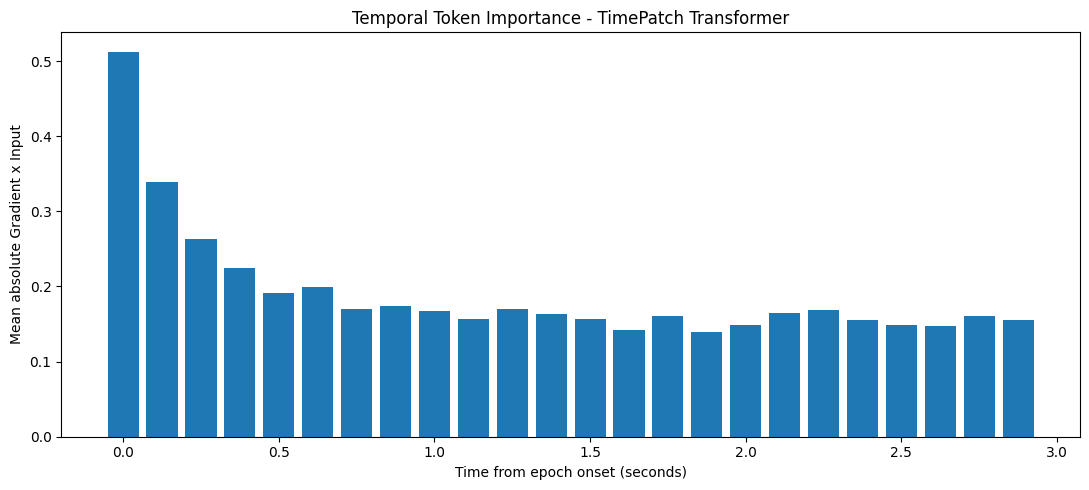

,Token,Start_Time_s,End_Time_s,Importance
0,0,0.000,0.125,0.512584
1,1,0.125,0.250,0.338504
2,2,0.250,0.375,0.263068
3,3,0.375,0.500,0.224582
5,5,0.625,0.750,0.199006
4,4,0.500,0.625,0.190889
7,7,0.875,1.000,0.174431
6,6,0.750,0.875,0.170389
10,10,1.250,1.375,0.170021
18,18,2.250,2.375,0.169017


In [147]:

import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd

# Reproduce the TimePatch model's forward pass
# and expose its temporal token embeddings.

def forward_with_tokens(model, x, remove_indices=None):

    # Temporal patch embedding
    x = model.temporal_embedding(x)

    # Spatial feature extraction across electrodes
    x = model.spatial_extraction(x)

    # Convert to temporal tokens
    tokens = x.squeeze(2).transpose(1, 2)

    # Add learned temporal positional embeddings
    tokens = tokens + model.positional_embedding

    # Optional token deletion
    if remove_indices is not None:

        mask = torch.zeros(
            (1, tokens.shape[1]),
            dtype=torch.bool,
            device=tokens.device
        )

        mask[:, remove_indices] = True

        # Replace deleted tokens with the sample's
        # mean token embedding as a neutral baseline
        baseline = tokens.mean(
            dim=1, keepdim=True
        )

        tokens = torch.where(
            mask.unsqueeze(-1),
            baseline.expand_as(tokens),
            tokens
        )

    # Transformer encoder
    x = model.transformer(tokens)

    # Global average pooling
    x = x.mean(dim=1)

    # Classification
    logits = model.classifier(x)

    return logits, tokens


# ---------------------------------------
# Calculate Gradient x Input attribution
# ---------------------------------------

best_model.eval()

batch_size = 32

attribution_sum = None
total_samples = 0

for start in range(0, len(X_explain), batch_size):

    xb = X_explain[start:start + batch_size]

    with torch.enable_grad():

        logits, tokens = forward_with_tokens(
            best_model, xb
        )

        # Explain the class predicted by the model
        predicted_class = logits.argmax(dim=1)

        target_score = logits.gather(
            1, predicted_class.unsqueeze(1)
        ).sum()

        gradients = torch.autograd.grad(
            target_score, tokens
        )[0]

        attribution = (
            tokens * gradients
        ).abs().sum(dim=-1)

    batch_sum = attribution.detach().sum(
        dim=0
    ).cpu().numpy()

    if attribution_sum is None:
        attribution_sum = batch_sum
    else:
        attribution_sum += batch_sum

    total_samples += len(xb)


# Average attribution across test trials
token_importance = attribution_sum / total_samples

n_tokens = len(token_importance)

print("Number of temporal tokens:", n_tokens)
print("Attribution shape:", token_importance.shape)


# ---------------------------------------
# Plot token importance
# ---------------------------------------

sampling_rate = 128
patch_size = 16

token_start_times = (
    np.arange(n_tokens) * patch_size / sampling_rate
)

token_importance_df = pd.DataFrame({
    "Token": np.arange(n_tokens),
    "Start_Time_s": token_start_times,
    "End_Time_s": token_start_times +
                  patch_size / sampling_rate,
    "Importance": token_importance
})

token_importance_df = token_importance_df.sort_values(
    "Importance", ascending=False
)

token_importance_df.to_csv(
    os.path.join(base, "B2_3_token_attribution.csv"),
    index=False
)

plt.figure(figsize=(11, 5))

plt.bar(
    token_start_times,
    attribution_sum / total_samples,
    width=0.10
)

plt.xlabel("Time from epoch onset (seconds)")
plt.ylabel("Mean absolute Gradient x Input")
plt.title("Temporal Token Importance - TimePatch Transformer")
plt.tight_layout()

plt.savefig(
    os.path.join(base, "B2_3_token_attribution.png"),
    dpi=300
)

plt.show()

display(token_importance_df.head(10))


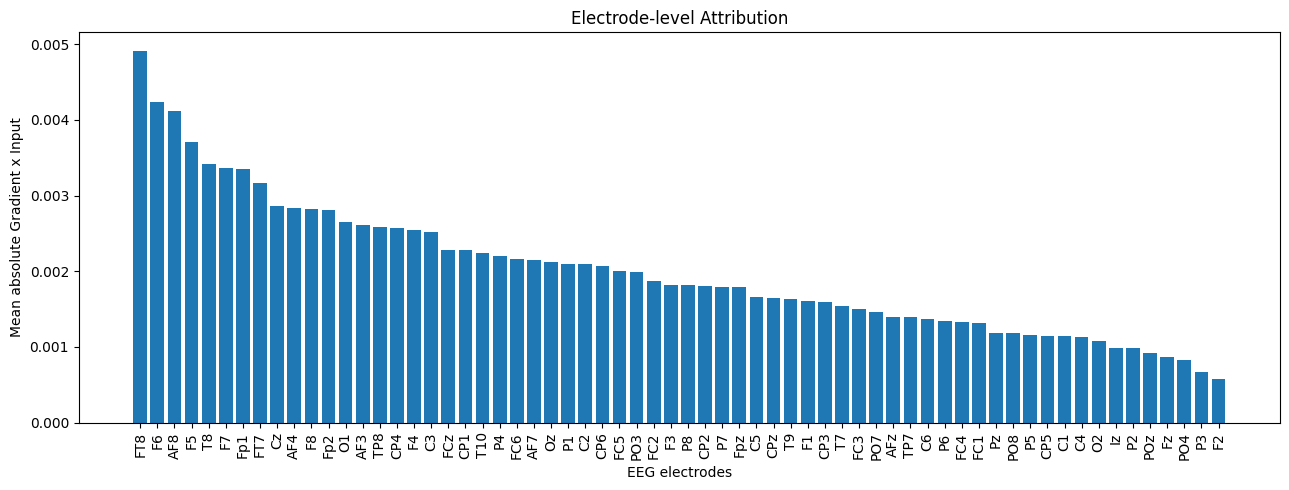

,Channel,Importance
39,FT8,0.004913
36,F6,0.004241
28,AF8,0.004121
30,F5,0.003710
41,T8,0.003414
29,F7,0.003362
21,Fp1,0.003346
38,FT7,0.003162
10,Cz,0.002858
27,AF4,0.002841


In [148]:

channel_names = [
    ch.decode() if isinstance(ch, bytes) else str(ch)
    for ch in raw_data["channels"]
]

channel_importance_sum = np.zeros(
    len(channel_names)
)

best_model.eval()

for start in range(0, len(X_explain), 32):

    xb = X_explain[start:start + 32].clone().detach()
    xb.requires_grad_(True)

    logits = best_model(xb)

    predicted_class = logits.argmax(dim=1)

    score = logits.gather(
        1, predicted_class.unsqueeze(1)
    ).sum()

    gradients = torch.autograd.grad(
        score, xb
    )[0]

    channel_attr = (
        xb * gradients
    ).abs().mean(dim=(0, 1, 3))

    channel_importance_sum += (
        channel_attr.detach().cpu().numpy()
        * len(xb)
    )

channel_importance = (
    channel_importance_sum / len(X_explain)
)

channel_df = pd.DataFrame({
    "Channel": channel_names,
    "Importance": channel_importance
}).sort_values(
    "Importance", ascending=False
)

channel_df.to_csv(
    os.path.join(base, "B2_3_channel_attribution.csv"),
    index=False
)

plt.figure(figsize=(13, 5))

plt.bar(
    channel_df["Channel"],
    channel_df["Importance"]
)

plt.xticks(rotation=90)
plt.xlabel("EEG electrodes")
plt.ylabel("Mean absolute Gradient x Input")
plt.title("Electrode-level Attribution")

plt.tight_layout()

plt.savefig(
    os.path.join(base, "B2_3_channel_attribution.png"),
    dpi=300
)

plt.show()

display(channel_df.head(20))


B2.3: MODEL SELECTION
Selected model: TimePatch_seed0
Device: cpu
Input shape: (360, 1, 64, 384)
Number of test trials: 360
Trainable parameters: 1482

Forward-pass verification:
Maximum output difference: 0.0
Forward pass verified successfully!

STEP 4: GRADIENT ATTRIBUTION
Total temporal tokens: 24
Attribution values: [0.51258385 0.33850401 0.26306825 0.2245821  0.19088889 0.19900565
 0.17038928 0.17443074 0.16698646 0.15730794 0.17002053 0.16336272
 0.15605251 0.14152187 0.16003102 0.13899994 0.1487748  0.16421672
 0.16901676 0.15534027 0.14855008 0.1470959  0.16041014 0.15508664]

Most important token indices:
[0 1 2 3 5]

Top five important tokens:


,Token,Start_Time_s,End_Time_s,Importance
0,0,0.000,0.125,0.512584
1,1,0.125,0.250,0.338504
2,2,0.250,0.375,0.263068
3,3,0.375,0.500,0.224582
5,5,0.625,0.750,0.199006


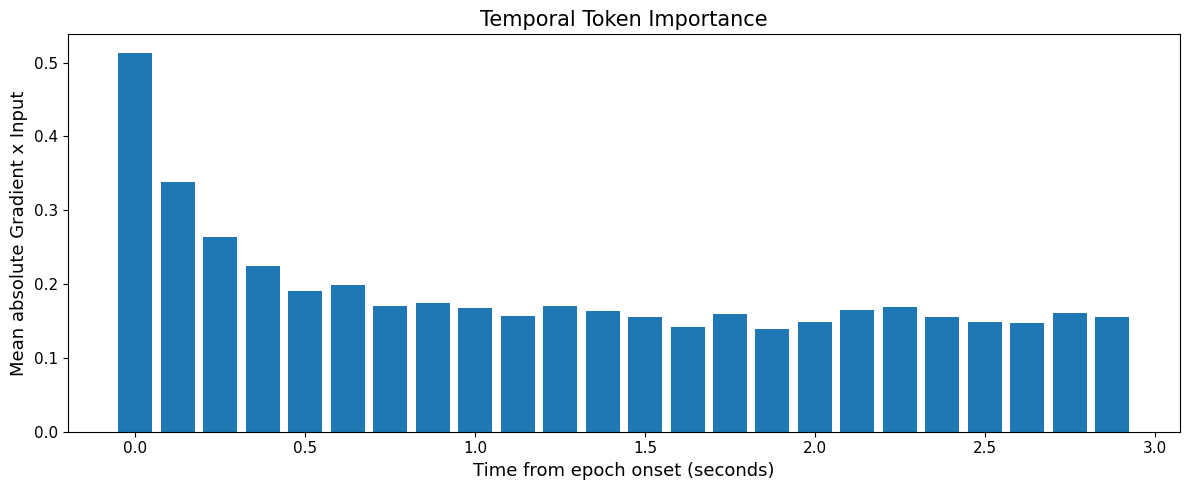


STEP 8: ORIGINAL PERFORMANCE
{'Accuracy': 75.55555555555556, 'Macro_F1': 75.51853111186671, 'True_Class_Probability': np.float32(0.67651314)}

STEP 9: IMPORTANT TOKEN DELETION
Deleted token indices: [0 1 2 3 5]
Performance after important-token deletion:
{'Accuracy': 59.166666666666664, 'Macro_F1': 58.45860382601597, 'True_Class_Probability': np.float32(0.556429)}

STEP 10: RANDOM TOKEN DELETION
Completed 20/100 random deletion experiments
Completed 40/100 random deletion experiments
Completed 60/100 random deletion experiments
Completed 80/100 random deletion experiments
Completed 100/100 random deletion experiments

FINAL DELETION EXPERIMENT RESULTS


,Condition,Accuracy,Macro_F1,True_Class_Probability
0,Original,75.5556,75.5185,0.6765
1,Important tokens removed,59.1667,58.4586,0.5564
2,Random tokens removed,74.4972,74.4042,0.6735



Random deletion variability:
Accuracy                  2.5696
Macro_F1                  2.6880
True_Class_Probability    0.0206
dtype: float64

ACCURACY REDUCTION
Original accuracy: 75.556
Important-token deletion accuracy: 59.167
Mean random deletion accuracy: 74.497
Accuracy drop after important deletion: 16.389
Mean accuracy drop after random deletion: 1.058
Empirical randomisation p-value: 0.0099


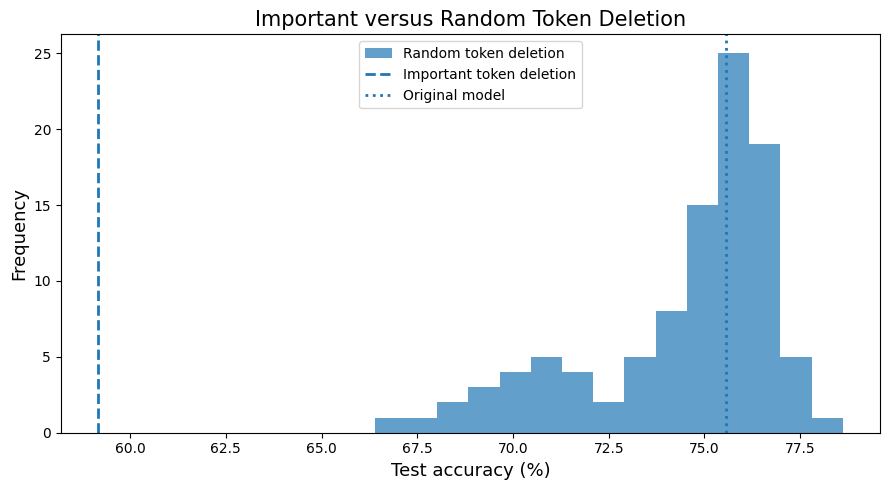


B2.3 ATTRIBUTION AND DELETION COMPLETED
Selected model: TimePatch_seed0
Number of temporal tokens: 24
Important tokens: [0 1 2 3 5]
Original accuracy: 75.56 %
Important deletion accuracy: 59.17 %
Random deletion mean accuracy: 74.5 %
Empirical randomisation p-value: 0.0099

Files saved in: /content/Assignment/task1
1. B2_3_token_attribution.csv
2. B2_3_token_attribution.png
3. B2_3_deletion_summary.csv
4. B2_3_random_deletion_results.csv
5. B2_3_deletion_comparison.png

B2.3 attribution and deletion experiment finished!


In [150]:

# ============================================================
# B2.3: GRADIENT ATTRIBUTION AND TOKEN DELETION EXPERIMENT
# ============================================================

import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import accuracy_score, f1_score


# ============================================================
# STEP 1: SELECT THE BEST TRANSFORMER
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Select using validation performance, NOT test performance
best_model = copy.deepcopy(
    model_instances["TimePatch_seed0"]
)

best_model = best_model.to(device)
best_model.eval()

# Original held-out test data
X_explain = X_original_tensor.to(
    device=device,
    dtype=torch.float32
)

y_explain = torch.as_tensor(
    np.asarray(y_test).copy(),
    dtype=torch.long,
    device=device
)

print("=" * 65)
print("B2.3: MODEL SELECTION")
print("=" * 65)

print("Selected model: TimePatch_seed0")
print("Device:", device)

print("Input shape:", tuple(X_explain.shape))
print("Number of test trials:", len(X_explain))

print(
    "Trainable parameters:",
    sum(p.numel() for p in best_model.parameters())
)


# ============================================================
# STEP 2: DEFINE FORWARD FUNCTION WITH TOKEN ACCESS
# ============================================================

def forward_with_tokens(
    model,
    x,
    remove_indices=None
):
    """
    Reproduce the original EEGTransformer forward pass.

    If remove_indices is provided, replace those temporal
    token embeddings with the mean token embedding.

    Input shape:
        (batch, 1, 64, 384)

    Token shape:
        (batch, 24, 8)
    """

    # Stage 1: Temporal patch embedding
    x = model.temporal_embedding(x)

    # Stage 2: Spatial feature extraction
    x = model.spatial_extraction(x)

    # Convert to temporal tokens
    x = x.squeeze(2)
    tokens = x.transpose(1, 2)

    # Add learned positional embeddings
    tokens = tokens + model.positional_embedding

    # --------------------------------------------------------
    # Optional token deletion
    # --------------------------------------------------------

    if remove_indices is not None:

        # Convert NumPy indices into a safe PyTorch tensor
        # .copy() prevents the negative-stride error
        remove_indices = np.asarray(
            remove_indices,
            dtype=np.int64
        ).copy()

        remove_indices = torch.as_tensor(
            remove_indices,
            dtype=torch.long,
            device=tokens.device
        )

        # Create a mask for the selected tokens
        mask = torch.zeros(
            tokens.shape[1],
            dtype=torch.bool,
            device=tokens.device
        )

        mask[remove_indices] = True

        # Calculate the mean token embedding for each trial
        baseline = tokens.mean(
            dim=1,
            keepdim=True
        )

        # Replace selected tokens with the baseline
        tokens = torch.where(
            mask.view(1, -1, 1),
            baseline.expand_as(tokens),
            tokens
        )

    # Stage 3: Transformer encoder
    x = model.transformer(tokens)

    # Global average pooling
    x = x.mean(dim=1)

    # Classification
    logits = model.classifier(x)

    return logits, tokens


# ============================================================
# STEP 3: VERIFY THAT THE FUNCTION REPRODUCES THE MODEL
# ============================================================

with torch.no_grad():

    original_logits = best_model(
        X_explain[:8]
    )

    reconstructed_logits, _ = forward_with_tokens(
        best_model,
        X_explain[:8]
    )

difference = (
    original_logits - reconstructed_logits
).abs().max().item()

print("\nForward-pass verification:")
print("Maximum output difference:", difference)

assert torch.allclose(
    original_logits,
    reconstructed_logits,
    atol=1e-5,
    rtol=1e-5
), "The reconstructed forward pass does not match the original model."

print("Forward pass verified successfully!")


# ============================================================
# STEP 4: GRADIENT X INPUT ATTRIBUTION
# ============================================================

print("\n" + "=" * 65)
print("STEP 4: GRADIENT ATTRIBUTION")
print("=" * 65)

best_model.eval()

batch_size = 32

attribution_sum = np.zeros(
    best_model.num_patches,
    dtype=np.float64
)

total_samples = 0

for start in range(
    0,
    len(X_explain),
    batch_size
):

    xb = X_explain[
        start:start + batch_size
    ]

    # Enable gradient computation
    with torch.enable_grad():

        logits, tokens = forward_with_tokens(
            best_model,
            xb
        )

        # Select the predicted class
        predicted_class = logits.argmax(dim=1)

        # Obtain the predicted-class scores
        target_score = logits.gather(
            1,
            predicted_class.unsqueeze(1)
        ).sum()

        # Calculate gradients with respect to tokens
        gradients = torch.autograd.grad(
            outputs=target_score,
            inputs=tokens
        )[0]

        # Gradient x Input attribution
        attribution = (
            tokens * gradients
        ).abs().sum(dim=-1)

    # Average attribution across samples
    attribution_sum += (
        attribution.detach()
        .sum(dim=0)
        .cpu()
        .numpy()
    )

    total_samples += len(xb)


# Mean importance of each token
token_importance = (
    attribution_sum / total_samples
)

n_tokens = len(token_importance)

print("Total temporal tokens:", n_tokens)
print("Attribution values:", token_importance)


# ============================================================
# STEP 5: RANK THE TEMPORAL TOKENS
# ============================================================

# Select five most important tokens
N_DELETE = 5

# IMPORTANT: .copy() fixes the negative-stride problem
important_indices = (
    np.argsort(token_importance)[-N_DELETE:][::-1].copy()
)

print("\nMost important token indices:")
print(important_indices)

# Prepare token information
sampling_rate = 128
patch_size = 16

token_times = (
    np.arange(n_tokens)
    * patch_size
    / sampling_rate
)

token_df = pd.DataFrame({
    "Token": np.arange(n_tokens),
    "Start_Time_s": token_times,
    "End_Time_s": (
        token_times + patch_size / sampling_rate
    ),
    "Importance": token_importance
})

token_df = token_df.sort_values(
    "Importance",
    ascending=False
)

print("\nTop five important tokens:")
display(token_df.head(5))


# ============================================================
# STEP 6: PLOT ATTRIBUTION
# ============================================================

plt.figure(figsize=(12, 5))

plt.bar(
    token_times,
    token_importance,
    width=0.10
)

plt.xlabel(
    "Time from epoch onset (seconds)",
    fontsize=13
)

plt.ylabel(
    "Mean absolute Gradient x Input",
    fontsize=13
)

plt.title(
    "Temporal Token Importance",
    fontsize=15
)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()

plt.savefig(
    os.path.join(
        base,
        "B2_3_token_attribution.png"
    ),
    dpi=300
)

plt.show()

token_df.to_csv(
    os.path.join(
        base,
        "B2_3_token_attribution.csv"
    ),
    index=False
)


# ============================================================
# STEP 7: DEFINE EVALUATION FUNCTION
# ============================================================

def evaluate_token_deletion(
    model,
    X,
    y,
    remove_indices=None,
    batch_size=32
):

    model.eval()

    predictions = []
    true_class_probabilities = []

    for start in range(
        0,
        len(X),
        batch_size
    ):

        xb = X[
            start:start + batch_size
        ]

        yb = y[
            start:start + batch_size
        ]

        with torch.no_grad():

            if remove_indices is None:

                # Original model
                logits = model(xb)

            else:

                # Model with selected tokens deleted
                logits, _ = forward_with_tokens(
                    model,
                    xb,
                    remove_indices=remove_indices
                )

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predicted = logits.argmax(dim=1)

            predictions.extend(
                predicted.cpu().numpy()
            )

            # Probability assigned to the actual class
            true_prob = probabilities.gather(
                1,
                yb.unsqueeze(1)
            ).squeeze(1)

            true_class_probabilities.extend(
                true_prob.cpu().numpy()
            )

    predictions = np.asarray(predictions)

    y_true = y.cpu().numpy()

    return {
        "Accuracy": accuracy_score(
            y_true,
            predictions
        ) * 100,

        "Macro_F1": f1_score(
            y_true,
            predictions,
            average="macro"
        ) * 100,

        "True_Class_Probability": np.mean(
            true_class_probabilities
        )
    }


# ============================================================
# STEP 8: ORIGINAL MODEL PERFORMANCE
# ============================================================

print("\n" + "=" * 65)
print("STEP 8: ORIGINAL PERFORMANCE")
print("=" * 65)

original_result = evaluate_token_deletion(
    best_model,
    X_explain,
    y_explain
)

print(original_result)


# ============================================================
# STEP 9: DELETE THE FIVE MOST IMPORTANT TOKENS
# ============================================================

print("\n" + "=" * 65)
print("STEP 9: IMPORTANT TOKEN DELETION")
print("=" * 65)

important_result = evaluate_token_deletion(
    best_model,
    X_explain,
    y_explain,
    remove_indices=important_indices
)

print("Deleted token indices:", important_indices)

print("Performance after important-token deletion:")

print(important_result)


# ============================================================
# STEP 10: RANDOM TOKEN DELETION
# ============================================================

print("\n" + "=" * 65)
print("STEP 10: RANDOM TOKEN DELETION")
print("=" * 65)

N_RANDOM = 100

rng = np.random.default_rng(42)

random_results = []

for iteration in range(N_RANDOM):

    # Select five random tokens
    random_indices = rng.choice(
        n_tokens,
        size=N_DELETE,
        replace=False
    ).copy()

    result = evaluate_token_deletion(
        best_model,
        X_explain,
        y_explain,
        remove_indices=random_indices
    )

    result["Iteration"] = iteration + 1

    result["Deleted_Tokens"] = str(
        random_indices.tolist()
    )

    random_results.append(result)

    if (iteration + 1) % 20 == 0:

        print(
            f"Completed {iteration + 1}/{N_RANDOM} "
            "random deletion experiments"
        )


random_df = pd.DataFrame(
    random_results
)


# ============================================================
# STEP 11: SUMMARISE THE RESULTS
# ============================================================

random_mean = random_df[
    [
        "Accuracy",
        "Macro_F1",
        "True_Class_Probability"
    ]
].mean()

random_std = random_df[
    [
        "Accuracy",
        "Macro_F1",
        "True_Class_Probability"
    ]
].std()


deletion_summary = pd.DataFrame([

    {
        "Condition": "Original",
        **original_result
    },

    {
        "Condition": "Important tokens removed",
        **important_result
    },

    {
        "Condition": "Random tokens removed",
        "Accuracy": random_mean["Accuracy"],
        "Macro_F1": random_mean["Macro_F1"],
        "True_Class_Probability":
            random_mean["True_Class_Probability"]
    }

])


print("\n" + "=" * 65)
print("FINAL DELETION EXPERIMENT RESULTS")
print("=" * 65)

display(
    deletion_summary.round(4)
)


print("\nRandom deletion variability:")

print(
    random_std.round(4)
)


# ============================================================
# STEP 12: CALCULATE ACCURACY REDUCTION
# ============================================================

important_drop = (
    original_result["Accuracy"]
    - important_result["Accuracy"]
)

random_drops = (
    original_result["Accuracy"]
    - random_df["Accuracy"]
)

empirical_p = (
    1 + np.sum(
        random_drops >= important_drop
    )
) / (N_RANDOM + 1)


print("\n" + "=" * 65)
print("ACCURACY REDUCTION")
print("=" * 65)

print(
    "Original accuracy:",
    round(original_result["Accuracy"], 3)
)

print(
    "Important-token deletion accuracy:",
    round(important_result["Accuracy"], 3)
)

print(
    "Mean random deletion accuracy:",
    round(random_mean["Accuracy"], 3)
)

print(
    "Accuracy drop after important deletion:",
    round(important_drop, 3)
)

print(
    "Mean accuracy drop after random deletion:",
    round(random_drops.mean(), 3)
)

print(
    "Empirical randomisation p-value:",
    round(empirical_p, 4)
)


# ============================================================
# STEP 13: PLOT DELETION COMPARISON
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    random_df["Accuracy"],
    bins=15,
    alpha=0.7,
    label="Random token deletion"
)

plt.axvline(
    important_result["Accuracy"],
    linestyle="--",
    linewidth=2,
    label="Important token deletion"
)

plt.axvline(
    original_result["Accuracy"],
    linestyle=":",
    linewidth=2,
    label="Original model"
)

plt.xlabel(
    "Test accuracy (%)",
    fontsize=13
)

plt.ylabel(
    "Frequency",
    fontsize=13
)

plt.title(
    "Important versus Random Token Deletion",
    fontsize=15
)

plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        base,
        "B2_3_deletion_comparison.png"
    ),
    dpi=300
)

plt.show()


# ============================================================
# STEP 14: SAVE ALL RESULTS
# ============================================================

token_df.to_csv(
    os.path.join(
        base,
        "B2_3_token_attribution.csv"
    ),
    index=False
)

deletion_summary.to_csv(
    os.path.join(
        base,
        "B2_3_deletion_summary.csv"
    ),
    index=False
)

random_df.to_csv(
    os.path.join(
        base,
        "B2_3_random_deletion_results.csv"
    ),
    index=False
)


# ============================================================
# STEP 15: FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("B2.3 ATTRIBUTION AND DELETION COMPLETED")
print("=" * 65)

print("Selected model: TimePatch_seed0")

print("Number of temporal tokens:", n_tokens)

print("Important tokens:", important_indices)

print("Original accuracy:",
      round(original_result["Accuracy"], 2), "%")

print("Important deletion accuracy:",
      round(important_result["Accuracy"], 2), "%")

print("Random deletion mean accuracy:",
      round(random_mean["Accuracy"], 2), "%")

print("Empirical randomisation p-value:",
      round(empirical_p, 4))

print("\nFiles saved in:", base)

print("1. B2_3_token_attribution.csv")
print("2. B2_3_token_attribution.png")
print("3. B2_3_deletion_summary.csv")
print("4. B2_3_random_deletion_results.csv")
print("5. B2_3_deletion_comparison.png")

print("\nB2.3 attribution and deletion experiment finished!")


In [151]:
# ---------------------------------------------------------------------
# Per-subject (and per-trial) predictions of the models
# ---------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import torch

BASE = "/content/Assignment/task1"
TEST_SUBJECTS = [74, 82, 85, 86, 89, 96, 97, 107]

@torch.no_grad()
def logits_of(net, X, bs=64):
    net = net.to(device).eval()
    out = []
    for i in range(0, len(X), bs):
        out.append(net(X[i:i + bs].to(device)).cpu())
    return torch.cat(out).numpy()

y_true = np.asarray(y_test).astype(int)
subj = np.asarray(subjects_test_raw).astype(int)

# models to analyse: EEGNet, the transformer chosen on VALIDATION (seed 0),
# and the mean over the three TimePatch seeds (avoids "cherry-picking" a seed)
names = {
    "EEGNet": ["EEGNet"],
    "Transformer_best": ["TimePatch_seed0"],
    "Transformer_3seeds": ["TimePatch_seed0", "TimePatch_seed21", "TimePatch_seed42"],
}

trial_rows = pd.DataFrame({"subject": subj, "true": y_true})
for label, members in names.items():
    # average the class-1 minus class-0 logit margin over the members
    margins = []
    for m in members:
        lg = logits_of(model_instances[m], X_original_tensor)
        margins.append(lg[:, 1] - lg[:, 0])
    margin = np.mean(margins, axis=0)
    trial_rows[f"{label}_margin"] = margin
    trial_rows[f"{label}_pred"] = (margin > 0).astype(int)
    trial_rows[f"{label}_correct"] = (trial_rows[f"{label}_pred"] == y_true).astype(int)

model_subject = (
    trial_rows.groupby("subject")[[c for c in trial_rows if c.endswith("_correct")]]
    .mean().mul(100).round(2)
    .rename(columns=lambda c: c.replace("_correct", "_acc"))
    .reset_index()
)
print(model_subject.to_string(index=False))
trial_rows.to_csv(os.path.join(BASE, "B2_3_trial_level_model_outputs.csv"), index=False)

 subject  EEGNet_acc  Transformer_best_acc  Transformer_3seeds_acc
      74       75.56                 57.78                   53.33
      82       75.56                 62.22                   68.89
      85       80.00                 75.56                   71.11
      86       95.56                 91.11                   88.89
      89       88.89                 84.44                   86.67
      96       97.78                 88.89                   93.33
      97       82.22                 73.33                   82.22
     107       80.00                 71.11                   77.78


In [152]:

# ---------------------------------------------------------------------
#  Per-subject A3 decoders (visual 4-15 Hz occipital, ocular
#          0.5-4 Hz frontal), trained ONLY on development subjects and
#          tested on each held-out subject separately.
# ---------------------------------------------------------------------
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from scipy.stats import binom

parts = pd.read_csv(os.path.join(BASE, "B_subject_partitions.csv"))
dev_subjects = parts.loc[parts.partition.isin(["model_training", "validation"]), "subject"].tolist()
assert set(dev_subjects).isdisjoint(TEST_SUBJECTS)

def chance_threshold(n, alpha=0.05):
    """Smallest #correct k with P(X >= k | p=0.5, n) <= alpha (one-sided binomial)."""
    k = int(binom.ppf(1 - alpha, n, 0.5)) + 1
    while binom.sf(k - 1, n, 0.5) > alpha:
        k += 1
    while k > 0 and binom.sf(k - 2, n, 0.5) <= alpha:
        k -= 1
    return k

a3_rows, a3_trial = [], []
for route in ["visual", "ocular"]:
    df = pd.read_csv(os.path.join(BASE, f"A3_{route}_features.csv"))
    feat = [c for c in df.columns if c not in ("subject", "run", "label", "event")]
    tr = df[df.subject.isin(dev_subjects)]
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
    clf.fit(tr[feat].values, tr["label"].values)
    for s in TEST_SUBJECTS:
        te = df[df.subject == s]
        pred = clf.predict(te[feat].values)
        k = int((pred == te["label"].values).sum())
        n = len(te)
        thr = chance_threshold(n)
        a3_rows.append({
            "subject": s, "route": route, "n_trials": n, "correct": k,
            "acc_pct": round(100 * k / n, 2),
            "chance_threshold_correct": thr,
            "chance_threshold_pct": round(100 * thr / n, 2),
            "binom_p_one_sided": round(binom.sf(k - 1, n, 0.5), 4),
            "above_chance": k >= thr,
        })
a3_subject = pd.DataFrame(a3_rows)
print(a3_subject.to_string(index=False))
a3_subject.to_csv(os.path.join(BASE, "B2_3_A3_per_subject_decoders.csv"), index=False)
print("\nNOTE: with n=45 the 5% chance threshold is", chance_threshold(45),
      "/45 =", round(100 * chance_threshold(45) / 45, 1), "%")
print("Rows in A3 feature files differ from Part B (1813 vs 1806)? Check per-subject n above.")




 subject  route  n_trials  correct  acc_pct  chance_threshold_correct  chance_threshold_pct  binom_p_one_sided  above_chance
      74 visual        45       20    44.44                        29                 64.44             0.8144         False
      82 visual        45       26    57.78                        29                 64.44             0.1856         False
      85 visual        45       25    55.56                        29                 64.44             0.2757         False
      86 visual        45       28    62.22                        29                 64.44             0.0676         False
      89 visual        45       20    44.44                        29                 64.44             0.8144         False
      96 visual        45       27    60.00                        29                 64.44             0.1163         False
      97 visual        45       25    55.56                        29                 64.44             0.2757         False


In [153]:
# ---------------------------------------------------------------------
# Subject-level correlations (n = 8, so use exact permutation tests)
# ---------------------------------------------------------------------
from itertools import permutations
from scipy.stats import spearmanr, rankdata

def exact_spearman(x, y):
    """Spearman rho with an exact two-sided permutation p-value (8! = 40320)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    rx, ry = rankdata(x), rankdata(y)
    rho = np.corrcoef(rx, ry)[0, 1]
    if np.isnan(rho):
        return np.nan, np.nan
    count = 0
    total = 0
    for p in permutations(range(len(y))):
        r = np.corrcoef(rx, ry[list(p)])[0, 1]
        total += 1
        if abs(r) >= abs(rho) - 1e-12:
            count += 1
    return rho, count / total

# --- A2: per-subject LI (median across trials; the mean is dominated by
#         outliers, e.g. subject 72) and the run-aware robust label
stats = pd.read_csv(os.path.join(BASE, "subject_band_lateralisation_stats.csv"))
li = stats.pivot(index="subject", columns="band", values="median_LI")
li.columns = [f"LI_median_{c}" for c in li.columns]
li["LI_median_mu_beta_mean"] = li.mean(axis=1)
labels = pd.read_csv(os.path.join(BASE, "subject_lateralisation_robust_labels.csv"))[["subject", "final_label"]]

a3w = a3_subject.pivot(index="subject", columns="route", values="acc_pct")
a3w.columns = [f"A3_{c}_acc" for c in a3w.columns]

master = (
    model_subject.set_index("subject")
    .join(li).join(a3w)
    .join(labels.set_index("subject"))
    .loc[TEST_SUBJECTS].reset_index()
)
master.to_csv(os.path.join(BASE, "B2_3_subject_master_table.csv"), index=False)
print(master.round(2).to_string(index=False))

pairs = []
for m in ["EEGNet_acc", "Transformer_best_acc", "Transformer_3seeds_acc"]:
    for pred in ["LI_median_mu", "LI_median_beta", "LI_median_mu_beta_mean",
                 "A3_visual_acc", "A3_ocular_acc"]:
        rho, p = exact_spearman(master[m], master[pred])
        pairs.append({"model_accuracy": m, "predictor": pred,
                      "spearman_rho": round(rho, 3), "exact_p_two_sided": round(p, 4)})
corr = pd.DataFrame(pairs)
print("\n", corr.to_string(index=False))
corr.to_csv(os.path.join(BASE, "B2_3_subject_level_correlations.csv"), index=False)
print("\nWith n=8, |rho| must be >= ~0.74 to reach p<0.05 -> low power; "
      "report effect sizes, do not over-interpret 'no correlation'.")
print("Held-out subjects labelled 'ERD present':",
      int((master.final_label == "Lateralised ERD present").sum()), "of 8")




 subject  EEGNet_acc  Transformer_best_acc  Transformer_3seeds_acc  LI_median_beta  LI_median_mu  LI_median_mu_beta_mean  A3_ocular_acc  A3_visual_acc             final_label
      74       75.56                 57.78                   53.33            5.32          1.72                    3.52          62.22          44.44  Lateralised ERD absent
      82       75.56                 62.22                   68.89            7.38         11.48                    9.43          46.67          57.78  Lateralised ERD absent
      85       80.00                 75.56                   71.11           18.61         31.52                   25.06          46.67          55.56 Lateralised ERD present
      86       95.56                 91.11                   88.89            1.78         -8.66                   -3.44          53.33          62.22  Lateralised ERD absent
      89       88.89                 84.44                   86.67            2.17        -13.09                   -5.46     

In [154]:
# ---------------------------------------------------------------------
# Trial-level analysis (n = 360): much more power than n = 8.
#   For each test trial we have: model margin, the trial's own mu/beta LI
#   (A2) and the trial's A3 confound-decoder margin. We ask whether the
#   model is *more likely correct* when the trial shows stronger
#   contralateral ERD, and whether its output follows the confound decoder.
#   Everything is computed within subject, then combined (Fisher z), so that
#   between-subject baseline differences cannot create the effect.
# ---------------------------------------------------------------------
from scipy.stats import norm

man = pd.read_csv(os.path.join(BASE, "B_dataset_manifest.csv"))
man_test = man[man.split == "test"].reset_index(drop=True)
assert len(man_test) == len(trial_rows)
# the manifest row order must match X (checked through labels)
assert np.array_equal(man_test["label"].values, trial_rows["true"].values), \
    "Manifest order != X order. Merge by (subject, run, trial) from your build cell instead."
assert np.array_equal(man_test["subject"].values, trial_rows["subject"].values)
trial_rows[["run", "trial"]] = man_test[["run", "trial"]].values

li_tr = pd.read_csv(os.path.join(BASE, "all_subjects_trial_LI.csv"))
li_w = li_tr.pivot_table(index=["subject", "run", "trial"], columns="band", values="LI").reset_index()
li_w.columns.name = None
li_w = li_w.rename(columns={"mu": "LI_mu", "beta": "LI_beta"})
T = trial_rows.merge(li_w, on=["subject", "run", "trial"], how="left")
print("Trials with LI after merge:", T.LI_mu.notna().sum(), "/", len(T))

# A3 trial-level decoder margins (same train/test protocol as CELL 2). We need
# per-trial identifiers in the feature files: subject, run, and position within run.
conf_margin = {}
for route in ["visual", "ocular"]:
    df = pd.read_csv(os.path.join(BASE, f"A3_{route}_features.csv"))
    feat = [c for c in df.columns if c not in ("subject", "run", "label", "event")]
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    clf.fit(df[df.subject.isin(dev_subjects)][feat].values, df[df.subject.isin(dev_subjects)]["label"].values)
    te = df[df.subject.isin(TEST_SUBJECTS)].copy()
    te["trial"] = te.groupby(["subject", "run"]).cumcount() + 1
    te[f"{route}_margin"] = clf.decision_function(te[feat].values)
    conf_margin[route] = te[["subject", "run", "trial", f"{route}_margin"]]
for route, d in conf_margin.items():
    T = T.merge(d, on=["subject", "run", "trial"], how="left")

# Sign the margins by the TRUE class so that "larger = evidence for the correct class"
sgn = np.where(T["true"] == 1, 1, -1)
T["model_evidence"] = T["Transformer_best_margin"] * sgn
T["eegnet_evidence"] = T["EEGNet_margin"] * sgn
for route in ["visual", "ocular"]:
    T[f"{route}_evidence"] = T[f"{route}_margin"] * sgn

def within_subject_spearman(T, a, b):
    """Spearman within each subject, combined across subjects by Fisher z (random-effects-lite)."""
    zs, ws = [], []
    for s, g in T.dropna(subset=[a, b]).groupby("subject"):
        if len(g) < 10:
            continue
        r = spearmanr(g[a], g[b]).correlation
        if np.isfinite(r):
            zs.append(np.arctanh(np.clip(r, -0.999, 0.999)))
            ws.append(len(g) - 3)
    zs, ws = np.array(zs), np.array(ws)
    zbar = np.sum(zs * ws) / np.sum(ws)
    se = 1 / np.sqrt(np.sum(ws))
    p = 2 * (1 - norm.cdf(abs(zbar / se)))
    return float(np.tanh(zbar)), float(p), len(zs)

rows = []
for model_col, mname in [("eegnet_evidence", "EEGNet"), ("model_evidence", "Transformer_best")]:
    for pred in ["LI_mu", "LI_beta", "visual_evidence", "ocular_evidence"]:
        r, p, k = within_subject_spearman(T, model_col, pred)
        rows.append({"model": mname, "trial_predictor": pred,
                     "pooled_within_subject_rho": round(r, 3), "p": round(p, 4), "n_subjects": k})
trial_corr = pd.DataFrame(rows)
print(trial_corr.to_string(index=False))
trial_corr.to_csv(os.path.join(BASE, "B2_3_trial_level_correlations.csv"), index=False)

# Partial effect: does the model follow ERD AFTER controlling for the confound decoders?
import statsmodels.api as sm
Z = T.dropna(subset=["LI_mu", "LI_beta", "visual_evidence", "ocular_evidence"]).copy()
for c in ["LI_mu", "LI_beta"]:   # LI is heavy-tailed (ERD% ratio) -> rank within subject
    Z[c] = Z.groupby("subject")[c].rank(pct=True)
Zx = Z[["LI_mu", "LI_beta", "visual_evidence", "ocular_evidence"]]
Zx = (Zx - Zx.mean()) / Zx.std()
ols = sm.OLS(Z["model_evidence"].values, sm.add_constant(Zx.values)).fit(
    cov_type="cluster", cov_kwds={"groups": Z["subject"].values})
print("\nOLS (cluster-robust by subject): model evidence ~ LI_mu + LI_beta + visual + ocular")
print(pd.DataFrame({"term": ["const"] + list(Zx.columns), "coef": ols.params.round(4),
                    "p": ols.pvalues.round(4)}).to_string(index=False))




Trials with LI after merge: 360 / 360
           model trial_predictor  pooled_within_subject_rho      p  n_subjects
          EEGNet           LI_mu                     -0.057 0.2969           8
          EEGNet         LI_beta                      0.114 0.0357           8
          EEGNet visual_evidence                      0.063 0.2479           8
          EEGNet ocular_evidence                     -0.029 0.5931           8
Transformer_best           LI_mu                     -0.017 0.7564           8
Transformer_best         LI_beta                      0.085 0.1179           8
Transformer_best visual_evidence                      0.159 0.0033           8
Transformer_best ocular_evidence                      0.004 0.9431           8

OLS (cluster-robust by subject): model evidence ~ LI_mu + LI_beta + visual + ocular
           term    coef      p
          const  0.9956 0.0000
          LI_mu -0.0428 0.6131
        LI_beta  0.1356 0.0012
visual_evidence  0.1943 0.0153
ocular_evid

In [156]:
# ---------------------------------------------------------------------
# Which electrodes does the transformer's spatial filter use?
#   (also answers B2.2: electrode identity lives in the depthwise
#    (64x1) conv weights of `spatial_extraction`, NOT in an embedding)
# ---------------------------------------------------------------------
import matplotlib.pyplot as plt

ch = [c.decode() if isinstance(c, bytes) else str(c) for c in np.load(
    os.path.join(BASE, "B_eeg_dataset.npz"), allow_pickle=True)["channels"]]
rows = []
for seed in [0, 21, 42]:
    net = model_instances[f"TimePatch_seed{seed}"]
    w = net.spatial_extraction[0].weight.detach().cpu().numpy()[:, 0, :, 0]   # (8 filters, 64 channels)
    mag = np.abs(w).mean(axis=0)
    mag = mag / mag.sum()
    for name, group in {
        "sensorimotor (C3,C4,C1,C2,CP3,CP4,FC3,FC4)": ["C3", "C4", "C1", "C2", "CP3", "CP4", "FC3", "FC4"],
        "visual/occipital (O1,Oz,O2,PO7,PO8)": ["O1", "Oz", "O2", "PO7", "PO8"],
        "frontal/ocular (Fp1,Fpz,Fp2,AF7,AF8,F7,F8)": ["Fp1", "Fpz", "Fp2", "AF7", "AF8", "F7", "F8"],
    }.items():
        idx = [ch.index(c) for c in group if c in ch]
        rows.append({"seed": seed, "group": name, "share_of_weight": round(mag[idx].sum(), 3),
                     "share_if_uniform": round(len(idx) / len(ch), 3)})
print(pd.DataFrame(rows).to_string(index=False))
# Antisymmetry check: a lateralisation reader needs opposite-sign weights on C3 and C4
for seed in [0, 21, 42]:
    w = model_instances[f"TimePatch_seed{seed}"].spatial_extraction[0].weight.detach().cpu().numpy()[:, 0, :, 0]
    print(f"seed {seed}: corr(w_C3, w_C4) across the 8 filters =",
          round(np.corrcoef(w[:, ch.index('C3')], w[:, ch.index('C4')])[0, 1], 3))



 seed                                      group  share_of_weight  share_if_uniform
    0 sensorimotor (C3,C4,C1,C2,CP3,CP4,FC3,FC4)            0.125             0.125
    0        visual/occipital (O1,Oz,O2,PO7,PO8)            0.067             0.078
    0 frontal/ocular (Fp1,Fpz,Fp2,AF7,AF8,F7,F8)            0.147             0.109
   21 sensorimotor (C3,C4,C1,C2,CP3,CP4,FC3,FC4)            0.126             0.125
   21        visual/occipital (O1,Oz,O2,PO7,PO8)            0.079             0.078
   21 frontal/ocular (Fp1,Fpz,Fp2,AF7,AF8,F7,F8)            0.135             0.109
   42 sensorimotor (C3,C4,C1,C2,CP3,CP4,FC3,FC4)            0.126             0.125
   42        visual/occipital (O1,Oz,O2,PO7,PO8)            0.076             0.078
   42 frontal/ocular (Fp1,Fpz,Fp2,AF7,AF8,F7,F8)            0.125             0.109
seed 0: corr(w_C3, w_C4) across the 8 filters = 0.159
seed 21: corr(w_C3, w_C4) across the 8 filters = -0.327
seed 42: corr(w_C3, w_C4) across the 8 filters = -

In [157]:
%cd /content/Assignment

/content/Assignment


In [158]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	task1/B2_2a_history_Channel_NoIdentity_seed0.csv
	task1/B2_2a_history_Channel_NoIdentity_seed21.csv
	task1/B2_2a_history_Channel_NoIdentity_seed42.csv
	task1/B2_2a_history_Channel_WithIdentity_seed0.csv
	task1/B2_2a_history_Channel_WithIdentity_seed21.csv
	task1/B2_2a_history_Channel_WithIdentity_seed42.csv
	task1/B2_2a_history_TimePatch_seed0.csv
	task1/B2_2a_history_TimePatch_seed21.csv
	task1/B2_2a_history_TimePatch_seed42.csv
	task1/B2_2a_tokenisation_checkpoints.pt
	task1/B2_2a_tokenisation_seed_results.csv
	task1/B2_2a_tokenisation_summary.csv
	task1/B2_3_A3_per_subject_decoders.csv
	task1/B2_3_channel_attribution.csv
	task1/B2_3_channel_attribution.png
	task1/B2_3_deletion_comparison.png
	task1/B2_3_deletion_summary.csv
	task1/B2_3_random_deletion_results.csv
	task1/B2_3_subject_level_correlations.csv
	task1/B2_3_subject_master_table.cs

In [159]:
import os

files = [
    "task1/B_eeg_dataset.npz",
    "task1/B_normalized_dataset.npz",
    "task1/B2_2a_tokenisation_checkpoints.pt"
]

for file in files:
    size_mb = os.path.getsize(file) / (1024 * 1024)
    print(f"{file}: {size_mb:.2f} MB")

task1/B_eeg_dataset.npz: 153.28 MB
task1/B_normalized_dataset.npz: 156.91 MB
task1/B2_2a_tokenisation_checkpoints.pt: 0.10 MB


In [160]:
!git add task1/*.csv task1/*.png

In [161]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   task1/B2_2a_history_Channel_NoIdentity_seed0.csv
	new file:   task1/B2_2a_history_Channel_NoIdentity_seed21.csv
	new file:   task1/B2_2a_history_Channel_NoIdentity_seed42.csv
	new file:   task1/B2_2a_history_Channel_WithIdentity_seed0.csv
	new file:   task1/B2_2a_history_Channel_WithIdentity_seed21.csv
	new file:   task1/B2_2a_history_Channel_WithIdentity_seed42.csv
	new file:   task1/B2_2a_history_TimePatch_seed0.csv
	new file:   task1/B2_2a_history_TimePatch_seed21.csv
	new file:   task1/B2_2a_history_TimePatch_seed42.csv
	new file:   task1/B2_2a_tokenisation_seed_results.csv
	new file:   task1/B2_2a_tokenisation_summary.csv
	new file:   task1/B2_3_A3_per_subject_decoders.csv
	new file:   task1/B2_3_channel_attribution.csv
	new file:   task1/B2_3_channel_attribution.png
	new file:   task1/B2_3_deletion_comparison.png
	new file:   task

In [162]:
!git add task1/B2_2a_tokenisation_checkpoints.pt

In [163]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   task1/B2_2a_history_Channel_NoIdentity_seed0.csv
	new file:   task1/B2_2a_history_Channel_NoIdentity_seed21.csv
	new file:   task1/B2_2a_history_Channel_NoIdentity_seed42.csv
	new file:   task1/B2_2a_history_Channel_WithIdentity_seed0.csv
	new file:   task1/B2_2a_history_Channel_WithIdentity_seed21.csv
	new file:   task1/B2_2a_history_Channel_WithIdentity_seed42.csv
	new file:   task1/B2_2a_history_TimePatch_seed0.csv
	new file:   task1/B2_2a_history_TimePatch_seed21.csv
	new file:   task1/B2_2a_history_TimePatch_seed42.csv
	new file:   task1/B2_2a_tokenisation_checkpoints.pt
	new file:   task1/B2_2a_tokenisation_seed_results.csv
	new file:   task1/B2_2a_tokenisation_summary.csv
	new file:   task1/B2_3_A3_per_subject_decoders.csv
	new file:   task1/B2_3_channel_attribution.csv
	new file:   task1/B2_3_channel_attribution.png
	new file:  

In [164]:
!git commit -m "Add Task 1 B2 experimental results and analysis"

[main 9507615] Add Task 1 B2 experimental results and analysis
 28 files changed, 930 insertions(+)
 create mode 100644 task1/B2_2a_history_Channel_NoIdentity_seed0.csv
 create mode 100644 task1/B2_2a_history_Channel_NoIdentity_seed21.csv
 create mode 100644 task1/B2_2a_history_Channel_NoIdentity_seed42.csv
 create mode 100644 task1/B2_2a_history_Channel_WithIdentity_seed0.csv
 create mode 100644 task1/B2_2a_history_Channel_WithIdentity_seed21.csv
 create mode 100644 task1/B2_2a_history_Channel_WithIdentity_seed42.csv
 create mode 100644 task1/B2_2a_history_TimePatch_seed0.csv
 create mode 100644 task1/B2_2a_history_TimePatch_seed21.csv
 create mode 100644 task1/B2_2a_history_TimePatch_seed42.csv
 create mode 100644 task1/B2_2a_tokenisation_checkpoints.pt
 create mode 100644 task1/B2_2a_tokenisation_seed_results.csv
 create mode 100644 task1/B2_2a_tokenisation_summary.csv
 create mode 100644 task1/B2_3_A3_per_subject_decoders.csv
 create mode 100644 task1/B2_3_channel_attribution.csv
 

In [165]:
!git push origin main

fatal: could not read Username for 'https://github.com': terminal prompts disabled


In [166]:
!git log -1 --oneline

9507615 (HEAD -> main) Add Task 1 B2 experimental results and analysis


In [168]:
!git status


On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	task1/B_eeg_dataset.npz
	task1/B_normalized_dataset.npz

nothing added to commit but untracked files present (use "git add" to track)
